# Case Study 3: Market Making the SPY Limit Order Book

## Setup and Conventions

- **Files.** The notebook imports `fake_broker.py`, `main.py` and `simulate_as.py` from this folder. The only edit to them is Module 8's parser fix in `fake_broker._parse_line` (`int(fields["size"])` becomes `int(float(fields["size"]))`). Everything else is done by subclassing `FakeBroker` or wrapping `main.handle_next_tick`. The submission zip includes these files and `data/20260812_spy.txt`.
- **Tape.** `TAPE_PATH = "data/20260812_spy.txt"`, next to the notebook.
- **Evaluation window.** Every strategy run reads the full tape (2,367,205 messages, 09:22:04-16:15:01). `main.py` only quotes from 09:30 to 16:00, so every variant is evaluated on the same 23,400-second session. (With `main.py`'s default `MAX_MESSAGES = 300_000` the run would stop at 09:45:15.) The only shorter runs are 300,000-message checks that a modified broker or handler gives the same fills as the original.
- **Units.** Dollars, seconds and shares: $\sigma$ in dollars per $\sqrt{s}$, $k$ per dollar, $A$ per second.
- **Signs.** A buy adds to inventory and subtracts price $\times$ size from cash, and a sell does the opposite. P&L = cash + inventory $\times$ NBBO mid. We don't use `main.py`'s last-trade mark because one print is badly off: a 300,000-share average-price print at \$722.57 at 16:09:40 is about \$50 away from the market. Rebates add to P&L, and fees and adverse selection subtract from it. Markout is positive when the price moves in our favour after a fill.
- **Frictionless baseline.** Sections 0-1 run `main.py` as written (no fees, no latency, front-of-queue fills). We only use its P&L for calibration. It is not an estimate of live performance.

In [1]:
import os
import re
import time as walltime
from collections import defaultdict
from dataclasses import dataclass
from datetime import datetime

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_missing = [f for f in ("fake_broker.py", "main.py", "simulate_as.py") if not os.path.exists(f)]
assert not _missing, f"put the instructor's demo files next to this notebook: missing {_missing}"
import fake_broker
import main
from fake_broker import FakeBroker, OrderFilled, QuoteUpdate, TradePrint
from simulate_as import simulate_as

TAPE_PATH = "data/20260812_spy.txt"  # submission layout: data/ next to this notebook
assert os.path.exists(TAPE_PATH), f"tape not found at {TAPE_PATH}"

EVAL_MAX_MESSAGES = 2_400_000  # more than the tape's 2,367,205 lines, so every run reads the whole day
SEED = 4170

COLORS = {"real": "#2a78d6", "sim": "#eb6834", "accent": "#1baf7a", "muted": "#898781", "ink": "#52514e"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    "lines.linewidth": 1.6, "figure.dpi": 110,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 140)

### Backtest harness used by every section

- **Parser.** From 11:41:56 the tape writes some trade sizes as `3e+05`, which the original `int()` rejects (Section 0). `parse_event` applies the same fix and also keeps NBBO sizes, venue and condition codes.
- **`TapeBroker`** subclasses `FakeBroker` with matching unchanged. It logs each fill with the NBBO just *before* the triggering print, and how long our orders rest at each distance from the mid, using only lines already read.
- **`run_session`** is `main.run_backtest`'s loop with a pluggable handler and broker, so later sections swap in latency, queue and quoting variants on the same tape.

In [2]:
_FIELD_SPLIT = re.compile(r", (?=\w+=)")
NON_BOOK_CONDITIONS = {2, 10, 52, 53}  # average-price, derivatively priced, contingent, qualified contingent


@dataclass
class TapeQuote(QuoteUpdate):
    """A QuoteUpdate that also keeps the displayed NBBO sizes."""
    bid_size: float = np.nan
    ask_size: float = np.nan


@dataclass
class TapePrint(TradePrint):
    """A TradePrint that also keeps the reporting venue and SIP condition codes."""
    exchange: str = ""
    conditions: tuple = ()


def parse_fields(line):
    """Split one MarketData(...) line into raw field strings, exactly as fake_broker._parse_line does."""
    body = line.strip()[len("MarketData("):-1]
    return dict(part.split("=", 1) for part in _FIELD_SPLIT.split(body))


def parse_conditions(text):
    return tuple(int(code) for code in text.strip("[]").split(",") if code.strip())


def parse_event(line):
    """fake_broker._parse_line, except that sizes written like '3e+05' parse instead of raising."""
    f = parse_fields(line)
    t = datetime.strptime(f["local_time"], "%Y-%m-%d %H:%M:%S.%f")
    if "bid" in f:
        return TapeQuote(t, float(f["bid"]), float(f["ask"]), float(f["bid_size"]), float(f["ask_size"]))
    return TapePrint(t, float(f["last"]), int(float(f["size"])), f["exchange"],
                     parse_conditions(f.get("conditions", "[]")))


FILL_COLUMNS = ["time", "side", "price", "size", "mid", "distance", "bid", "ask",
                "print_price", "print_size", "exchange", "conditions"]


class TapeBroker(FakeBroker):
    """FakeBroker with the tolerant parser plus a fill log and a resting-time log.

    `distance` is how far an order sits behind the mid: mid - price for a buy, price - mid for a sell.
    """

    def __init__(self, data_path):
        super().__init__(data_path)
        self.messages_read = 0
        self.bid = self.ask = self.mid = None
        self.fill_log = []
        self.exposure = defaultdict(float)  # (side, distance) -> seconds resting there
        self._last_time = None

    def poll(self):
        event = self._read_event()
        if event is None:
            return []
        messages = self._pending_broker_messages
        self._pending_broker_messages = []
        return messages + [event] + self._exchange_step(event)

    def _read_event(self):
        """The next tape line as a TapeQuote/TapePrint, or None (with done=True) at the end of the tape."""
        line = self._file.readline()
        if not line:
            self.done = True
            return None
        self.messages_read += 1
        return parse_event(line)

    def _exchange_step(self, event):
        """What the exchange does with one tape event: log resting time, match a trade, track the NBBO."""
        self._accumulate_exposure(event.time)
        fills = []
        if isinstance(event, TradePrint):
            fills = self._check_fill(event)
            for fill in fills:
                self.fill_log.append((event.time, fill.side, fill.price, fill.size, self.mid,
                                      self._distance(fill.side, fill.price), self.bid, self.ask,
                                      event.price, event.size, event.exchange, event.conditions))
        else:
            self.bid, self.ask = event.bid, event.ask
            self.mid = 0.5 * (event.bid + event.ask)
        self._last_time = event.time
        return fills

    def _distance(self, side, price):
        return round(self.mid - price if side == "buy" else price - self.mid, 4)

    def _accumulate_exposure(self, now):
        # Orders in self._resting have been live since the previous message.
        if self._last_time is None or self.mid is None:
            return
        elapsed = (now - self._last_time).total_seconds()
        for side, (_, price, _) in self._resting.items():
            self.exposure[(side, self._distance(side, price))] += elapsed


@dataclass
class SessionResult:
    fills: pd.DataFrame     # one row per fill of size > 0, in tape order
    exposure: pd.DataFrame  # side, distance from mid, seconds resting there
    book: dict              # final `book` from the tick handler (pnl_history moved to main_pnl)
    main_pnl: pd.Series     # main.py's own last-trade-marked P&L, last value in each second
    messages_read: int
    zero_size_fills: int    # FakeBroker "fills" of 0 shares, triggered by fractional-share prints
    elapsed_s: float
    broker: FakeBroker      # the (closed) broker, for anything a subclass accumulated during the run


class PerSecondHistory(list):
    """Stands in for book["pnl_history"]: keeps only the last (time, pnl) in each second.

    main.handle_next_tick appends on every message (about 2.3 million tuples a day); we only ever use the
    last value per second, so this saves a few hundred MB per full-day run without changing any result.
    """

    def append(self, item):
        if self and self[-1][0].replace(microsecond=0) == item[0].replace(microsecond=0):
            self[-1] = item
        else:
            super().append(item)


def run_session(tick_handler=main.handle_next_tick, broker_cls=TapeBroker, tape_path=TAPE_PATH,
                max_messages=EVAL_MAX_MESSAGES):
    """main.run_backtest's loop with a pluggable handler and broker; returns everything needed to audit the run."""
    started = walltime.perf_counter()
    broker = broker_cls(tape_path)
    book = {"time": None, "best_bid": None, "best_ask": None, "last_trade_price": None,
            "inventory": 0, "cash": 0.0, "pnl_history": PerSecondHistory()}
    for _ in range(max_messages):
        if broker.done:
            break
        tick_handler(broker, book)
    broker.close()

    fills = pd.DataFrame(broker.fill_log, columns=FILL_COLUMNS)
    zero_size = int((fills["size"] == 0).sum())
    fills = fills[fills["size"] > 0].reset_index(drop=True)
    fills["signed"] = np.where(fills["side"] == "buy", fills["size"], -fills["size"])
    fills["cashflow"] = -fills["signed"] * fills["price"]
    exposure = pd.DataFrame([(side, dist, secs) for (side, dist), secs in broker.exposure.items()],
                            columns=["side", "distance", "seconds"])
    history = pd.DataFrame(book.pop("pnl_history"), columns=["time", "pnl"])
    main_pnl = history.groupby(history["time"].dt.floor("s"))["pnl"].last()
    return SessionResult(fills, exposure, book, main_pnl, broker.messages_read, zero_size,
                         walltime.perf_counter() - started, broker)


def show(values, name="value"):
    """Display labelled results (a dict or Series) as a one-column table."""
    display(pd.Series(values, name=name, dtype=object).to_frame())


def to_ns(times):
    return np.asarray(times, dtype="datetime64[ns]")


def prevailing(event_times, values, at_times):
    """Value of the latest event at or before each of `at_times` (NaN before the first event)."""
    idx = np.searchsorted(to_ns(event_times), to_ns(at_times), side="right") - 1
    out = np.asarray(values, dtype=float)[np.maximum(idx, 0)]
    return np.where(idx >= 0, out, np.nan)


with open(TAPE_PATH) as _f:
    TAPE_DAY = parse_event(_f.readline()).time.date()
SESSION_OPEN = datetime.combine(TAPE_DAY, main.MARKET_OPEN)
SESSION_CLOSE = datetime.combine(TAPE_DAY, main.MARKET_CLOSE)
SESSION_SECONDS = (SESSION_CLOSE - SESSION_OPEN).total_seconds()
SESSION_MINUTES = int(SESSION_SECONDS // 60)


def session_grid(freq_s=1):
    return pd.date_range(SESSION_OPEN, SESSION_CLOSE, freq=f"{freq_s}s")


def session_paths(fills, quotes, freq_s=1):
    """Inventory, cash and mid-marked P&L of a run on a regular grid from 09:30:00 to 16:00:00."""
    grid = session_grid(freq_s)
    flows = fills.groupby("time")[["signed", "cashflow"]].sum().cumsum()
    inventory = np.nan_to_num(prevailing(flows.index, flows["signed"], grid))
    cash = np.nan_to_num(prevailing(flows.index, flows["cashflow"], grid))
    mid = prevailing(quotes["time"], quotes["mid"], grid)
    return pd.DataFrame({"inventory": inventory, "cash": cash, "mid": mid, "pnl": cash + inventory * mid},
                        index=grid)


def load_tape(tape_path=TAPE_PATH, max_messages=EVAL_MAX_MESSAGES):
    """Read the tape once into quote and trade DataFrames.

    `line` is the 0-based tape line. Each trade gets the NBBO from the last quote line *before* it
    (`bid_before`, `ask_before`, `mid_before`), so nothing is looked up from the future.
    """
    q, t = defaultdict(list), defaultdict(list)
    with open(tape_path) as f:
        for line_no, line in enumerate(f):
            if line_no >= max_messages:
                break
            fld = parse_fields(line)
            if "bid" in fld:
                q["line"].append(line_no)
                q["time"].append(fld["local_time"])
                q["bid"].append(float(fld["bid"]))
                q["ask"].append(float(fld["ask"]))
                q["bid_size"].append(float(fld["bid_size"]))
                q["ask_size"].append(float(fld["ask_size"]))
            else:
                t["line"].append(line_no)
                t["time"].append(fld["local_time"])
                t["price"].append(float(fld["last"]))
                t["size"].append(int(float(fld["size"])))
                t["exchange"].append(fld["exchange"])
                t["conditions"].append(fld.get("conditions", "[]"))
    fmt = "%Y-%m-%d %H:%M:%S.%f"
    quotes = pd.DataFrame(q)
    quotes["time"] = pd.to_datetime(quotes["time"], format=fmt)
    quotes["mid"] = 0.5 * (quotes["bid"] + quotes["ask"])
    trades = pd.DataFrame(t)
    trades["time"] = pd.to_datetime(trades["time"], format=fmt)
    trades["exchange"] = trades["exchange"].astype("category")
    trades["non_book"] = [bool(NON_BOOK_CONDITIONS.intersection(parse_conditions(c))) for c in trades["conditions"]]
    before = np.searchsorted(quotes["line"].to_numpy(), trades["line"].to_numpy()) - 1
    for col in ("bid", "ask", "mid"):
        vals = quotes[col].to_numpy()[np.maximum(before, 0)]
        trades[f"{col}_before"] = np.where(before >= 0, vals, np.nan)
    return quotes, trades

## Section 0 - Before You Start: What's Already Built

The baseline as shipped (`main.run_backtest`, default 300,000 messages), as a smoke test. Its window ends at 09:45:15.

In [3]:
smoke_book = main.run_backtest(TAPE_PATH)
print(f"\nlast message read: {smoke_book['time']:%H:%M:%S}")

final inventory: 0 shares
final cash:      18.81
mark-to-market:  772.86
total PnL:       18.81

last message read: 09:45:15


The line that breaks the original parser, and a check that the fixed parser and `parse_event` read the tape identically:

In [4]:
with open(TAPE_PATH) as f:
    bad_line = next(line for line in f if ", size=3e+05," in line)  # a trade print, not a quote's ask_size
print(bad_line[:205], "...")
try:
    int(parse_fields(bad_line)["size"])  # what the original fake_broker._parse_line did with the size
except ValueError as err:
    print("\noriginal int():   ", repr(err))
print("fixed _parse_line:", fake_broker._parse_line(bad_line))
print("parse_event:      ", parse_event(bad_line))

# parse_event and the fixed fake_broker._parse_line agree on time/price/size (every 47th line of the tape).
checked = 0
with open(TAPE_PATH) as f:
    for line_no, line in enumerate(f):
        if line_no % 47:
            continue
        new, old = parse_event(line), fake_broker._parse_line(line)
        assert type(new).__mro__[1] is type(old)
        assert all(getattr(old, name) == getattr(new, name) for name in old.__dataclass_fields__)
        checked += 1
assert parse_event(bad_line).size == fake_broker._parse_line(bad_line).size == 300_000
print(f"lines checked: {checked:,}")

MarketData(ticker=SPY, local_time=2026-08-12 11:41:56.836280, remote_time=2026-08-12 11:41:56.821000, last=771.62, size=3e+05, exchange=UNKNOWN, raw_exchange_id=9, trade_id=52983525036366, tape=1, conditio ...

original int():    ValueError("invalid literal for int() with base 10: '3e+05'")
fixed _parse_line: TradePrint(time=datetime.datetime(2026, 8, 12, 11, 41, 56, 836280), price=771.62, size=300000)
parse_event:       TapePrint(time=datetime.datetime(2026, 8, 12, 11, 41, 56, 836280), price=771.62, size=300000, exchange='UNKNOWN', conditions=(53, 41))


lines checked: 50,367


## Section 1 - Calibrating the Model to Real Data

1a and 1b estimate $\sigma$, $k$ and $A$ (in $\lambda(\delta) = A e^{-k\delta}$) from the 09:30-16:00 session. 1c runs `simulate_as` with these values and compares it to the real `main.py` backtest.

### 1.0 - Loading the tape and running the frictionless baseline

In [5]:
quotes, trades = load_tape()
rth = lambda frame: frame[(frame["time"] >= SESSION_OPEN) & (frame["time"] < SESSION_CLOSE)]
rth_quotes, rth_trades = rth(quotes), rth(trades)

# Time-weighted NBBO spread over the session: each quote counts for as long as it stood.
standing = np.diff(np.append(to_ns(rth_quotes["time"]), to_ns([SESSION_CLOSE]))).astype("timedelta64[ns]")
standing_s = standing.astype(np.int64) / 1e9
spread_cents = ((rth_quotes["ask"] - rth_quotes["bid"]) * 100).round().astype(int)
spread_share = pd.Series(standing_s).groupby(spread_cents.to_numpy()).sum() / standing_s.sum()

off_market = (rth_trades["price"] - rth_trades["mid_before"]).abs() > 1.0
crossed_by = (rth_quotes["bid"] - rth_quotes["ask"]).to_numpy()
deviation = (trades["price"] - trades["mid_before"]).abs()
worst = trades.loc[deviation.idxmax()]
overview = pd.Series({
    "tape lines": len(quotes) + len(trades),
    "quote updates / trade prints (whole tape)": f"{len(quotes):,} / {len(trades):,}",
    "first / last message": f"{min(quotes['time'].min(), trades['time'].min()):%H:%M:%S} / "
                            f"{max(quotes['time'].max(), trades['time'].max()):%H:%M:%S}",
    "session quote updates": f"{len(rth_quotes):,}",
    "session trade prints": f"{len(rth_trades):,}",
    "  of which size 0 (fractional-share prints)": f"{(rth_trades['size'] == 0).sum():,}",
    "  of which DARK (off-exchange) venue": f"{(rth_trades['exchange'] == 'DARK').mean():.1%}",
    "  of which average-price / derivatively priced / contingent": f"{rth_trades['non_book'].sum():,}",
    "  of which more than $1 from the pre-trade mid": f"{off_market.sum():,}",
    "session crossed (ask < bid) / locked (ask = bid) quotes": f"{(rth_quotes['ask'] < rth_quotes['bid'] - 1e-9).sum():,} / {((rth_quotes['ask'] - rth_quotes['bid']).abs() < 1e-9).sum():,}",
    "session time with the NBBO crossed / crossed by >= 2 cents": f"{standing_s[crossed_by > 1e-9].sum():.1f} s / {standing_s[crossed_by >= 0.02 - 1e-9].sum():.1f} s",
    "time-weighted mean NBBO spread": f"{100 * (standing_s * (rth_quotes['ask'] - rth_quotes['bid'])).sum() / standing_s.sum():.2f} cents",
    "most off-market print on the tape": f"{worst['size']:,} sh at ${worst['price']:.2f} at {worst['time']:%H:%M:%S} "
                                         f"({worst['exchange']}, conditions {worst['conditions']}), ${deviation.max():.2f} from the mid",
})
show(overview)
spread_table = spread_share[spread_share > 0.001].rename("share of session").to_frame()
spread_table.index.name = "NBBO spread (cents)"
display(spread_table.style.format("{:.1%}"))

,value
tape lines,2367205
quote updates / trade prints (whole tape),"1,895,940 / 471,265"
first / last message,09:22:04 / 16:15:01
session quote updates,"1,862,747"
session trade prints,"465,180"
of which size 0 (fractional-share prints),"67,146"
of which DARK (off-exchange) venue,49.7%
of which average-price / derivatively priced / contingent,"17,819"
of which more than $1 from the pre-trade mid,18
session crossed (ask < bid) / locked (ask = bid) quotes,"730 / 8,316"


,share of session
NBBO spread (cents),
1,34.9%
2,48.9%
3,15.5%
4,0.6%


In [6]:
baseline = run_session()
paths = session_paths(baseline.fills, quotes)

# Audits: whole tape read; fill log reproduces main.py's own cash and inventory; no fills outside the session.
assert baseline.messages_read == len(quotes) + len(trades)
assert np.isclose(baseline.fills["cashflow"].sum(), baseline.book["cash"], atol=1e-6)
assert baseline.fills["signed"].sum() == baseline.book["inventory"]
assert baseline.fills["time"].between(SESSION_OPEN, SESSION_CLOSE, inclusive="left").all()

fills = baseline.fills
show({
    "messages read": f"{baseline.messages_read:,}",
    "run time (s)": f"{baseline.elapsed_s:.0f}",
    "shares filled": f"{fills['size'].sum():,}",
    "shares bought / sold": f"{fills.loc[fills['side'] == 'buy', 'size'].sum():,} / "
                            f"{fills.loc[fills['side'] == 'sell', 'size'].sum():,}",
    "zero-share fills dropped": f"{baseline.zero_size_fills:,}",
    "inventory at 16:00 (shares)": f"{paths['inventory'].iloc[-1]:.0f}",
    "P&L at 16:00, marked at the mid ($)": f"{paths['pnl'].iloc[-1]:,.2f}",
    "main.py's P&L, last-trade mark at 16:15:01 ($)": f"{baseline.main_pnl.iloc[-1]:,.2f}",
}, "frictionless baseline")

Over the full session the baseline fills 41,072 shares and ends with 6 shares of inventory and \$247.54 of P&L marked at the mid. `main.py`'s own last-trade mark gives almost the same number (\$248.50). The run also produced 8,874 zero-share "fills" from fractional-share prints, which we drop.

### 1a - Volatility from the realized midprice

We sample the NBBO mid every 10 ms (last quote at or before each point) from 09:30 to 16:00, close to how often the NBBO itself updates (about 80 times a second). Realized variance is the sum of squared 10 ms mid changes divided by 23,400 s, so $\hat\sigma$ is in dollars per $\sqrt{s}$, the unit `simulate_as` uses (its mid moves $\sigma\sqrt{dt}\,Z$ per step). We use the mid rather than trades because trades bounce between bid and ask. The signature plot repeats the estimate at intervals from 10 ms to 30 minutes, averaging over all grid offsets.

In [7]:
SIGMA_STEP_S = 0.01  # 10 ms sampling
grid_10ms = pd.date_range(SESSION_OPEN, SESSION_CLOSE, freq="10ms")
mid_10ms = prevailing(quotes["time"], quotes["mid"], grid_10ms)  # previous-tick mid every 10 ms (2,340,001 points)
del grid_10ms  # only needed to build mid_10ms
mid_1s = paths["mid"].to_numpy()                                  # the same mids every second (23,401 points)
assert np.array_equal(mid_10ms[::100], mid_1s)


def realized_sigma(mid_grid, step, base_s):
    """Subsampled realized volatility in $/sqrt(s).

    mid_grid is a previous-tick mid sampled every base_s seconds. The sampling interval is step * base_s, and the
    realized variance is averaged over all `step` starting offsets.
    """
    variances = []
    for offset in range(step):
        moves = np.diff(mid_grid[offset::step])
        variances.append(np.sum(moves ** 2) / (step * base_s * len(moves)))
    return float(np.sqrt(np.mean(variances)))


def single_grid_sigma(mid_grid, step, base_s):
    moves = np.diff(mid_grid[::step])
    return float(np.sqrt(np.sum(moves ** 2) / (step * base_s * len(moves))))


def sigma_at(interval_s, estimator):
    """Sub-second intervals use the 10 ms grid, longer ones the 1 s grid (same mids, far fewer offsets to loop over)."""
    if interval_s < 1:
        return estimator(mid_10ms, int(round(interval_s / SIGMA_STEP_S)), SIGMA_STEP_S)
    return estimator(mid_1s, int(interval_s), 1.0)


SIGNATURE_INTERVALS = [0.01, 0.1, 1, 2, 5, 10, 15, 30, 60, 120, 300, 600, 1800]
signature = pd.DataFrame({
    "interval_s": SIGNATURE_INTERVALS,
    "moves_per_grid": [int(round(SESSION_SECONDS / s)) for s in SIGNATURE_INTERVALS],
    "sigma_subsampled": [sigma_at(s, realized_sigma) for s in SIGNATURE_INTERVALS],
    "sigma_single_grid": [sigma_at(s, single_grid_sigma) for s in SIGNATURE_INTERVALS],
}).set_index("interval_s")

sigma_hat = realized_sigma(mid_10ms, 1, SIGMA_STEP_S)
mean_mid = mid_10ms.mean()
sigma_daily = sigma_hat * np.sqrt(SESSION_SECONDS)
moving_share = np.mean(np.diff(mid_10ms) != 0)
quote_rate = len(rth_quotes) / SESSION_SECONDS

points_per_half_hour = int(round(1800 / SIGMA_STEP_S))
half_hours = [realized_sigma(mid_10ms[b * points_per_half_hour:(b + 1) * points_per_half_hour + 1], 1, SIGMA_STEP_S)
              for b in range(13)]
half_hour_labels = [f"{(SESSION_OPEN + pd.Timedelta(minutes=30 * b)):%H:%M}" for b in range(13)]
intraday_sigma = pd.Series(half_hours, index=half_hour_labels, name="sigma ($/sqrt s)")

five_s = mid_1s[5:] - mid_1s[:-5]
j = int(np.argmin(five_s))

display(signature.round(5))
show({
    "sigma_hat, 10 ms sampling ($/sqrt s)": f"{sigma_hat:.5f}",
    "10 ms intervals where the mid changes": f"{moving_share:.1%}",
    "NBBO updates per second": f"{quote_rate:.0f}",
    "one-session move, sigma_hat x sqrt(23,400 s) ($)": f"{sigma_daily:.2f}",
    "mean mid ($)": f"{mean_mid:.2f}",
    "one-session move as % of mean mid": f"{sigma_daily / mean_mid:.3%}",
    "annualized (x sqrt 252)": f"{sigma_daily / mean_mid * np.sqrt(252):.1%}",
    "mid at 09:30 / 16:00 ($)": f"{mid_1s[0]:.3f} / {mid_1s[-1]:.3f}",
    "lowest / highest mid ($)": f"{mid_1s.min():.3f} / {mid_1s.max():.3f}",
    "largest 5-s mid move ($)": f"{five_s[j]:+.3f} ({paths.index[j]:%H:%M:%S}-{paths.index[j + 5]:%H:%M:%S})",
    "largest 5-s move in 5-s standard deviations": f"{five_s[j] / (sigma_hat * np.sqrt(5)):.0f}",
}, "1a")
display(intraday_sigma.round(4).to_frame().T)

,moves_per_grid,sigma_subsampled,sigma_single_grid
interval_s,,,
0.01,2340000,0.01669,0.01669
0.10,234000,0.01721,0.01715
1.00,23400,0.01855,0.01855
2.00,11700,0.01885,0.01910
5.00,4680,0.01945,0.02007
10.00,2340,0.01978,0.02030
15.00,1560,0.01965,0.02025
30.00,780,0.01916,0.01822
60.00,390,0.01892,0.01930


,1a
"sigma_hat, 10 ms sampling ($/sqrt s)",0.01669
10 ms intervals where the mid changes,3.3%
NBBO updates per second,80
"one-session move, sigma_hat x sqrt(23,400 s) ($)",2.55
mean mid ($),772.70
one-session move as % of mean mid,0.330%
annualized (x sqrt 252),5.2%
mid at 09:30 / 16:00 ($),774.680 / 772.610
lowest / highest mid ($),771.355 / 774.800
largest 5-s mid move ($),-1.200 (10:31:10-10:31:15)


,09:30,10:00,10:30,11:00,11:30,12:00,12:30,13:00,13:30,14:00,14:30,15:00,15:30
sigma ($/sqrt s),0.0297,0.0218,0.0278,0.0188,0.0141,0.0121,0.0117,0.0101,0.0097,0.0093,0.0084,0.0094,0.0147


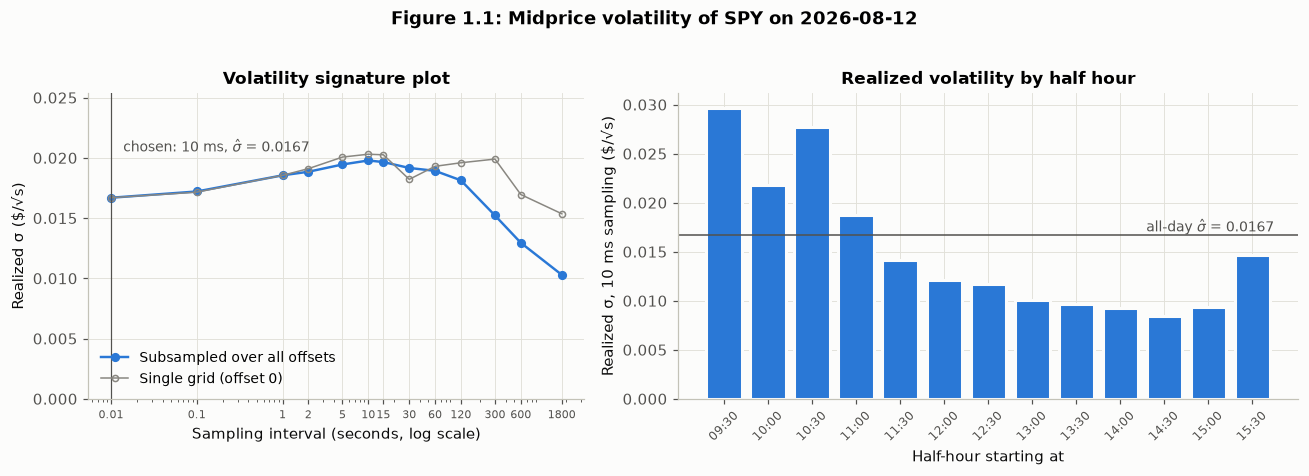

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})

ax1.plot(signature.index, signature["sigma_subsampled"], marker="o", ms=5, color=COLORS["real"],
         label="Subsampled over all offsets")
ax1.plot(signature.index, signature["sigma_single_grid"], marker="o", ms=4, lw=1, color=COLORS["muted"],
         mfc="none", label="Single grid (offset 0)")
ax1.axvline(SIGMA_STEP_S, color=COLORS["ink"], lw=0.8)
ax1.annotate(rf"chosen: 10 ms, $\hat{{\sigma}}$ = {sigma_hat:.4f}", xy=(SIGMA_STEP_S, sigma_hat),
             xytext=(8, 30), textcoords="offset points", fontsize=9, color=COLORS["ink"])
ax1.set_xscale("log")
ax1.set_ylim(0, signature["sigma_single_grid"].max() * 1.25)
ax1.set_xticks(SIGNATURE_INTERVALS, [f"{s:g}" for s in SIGNATURE_INTERVALS], fontsize=7.5)
ax1.set_xlabel("Sampling interval (seconds, log scale)")
ax1.set_ylabel("Realized σ ($/√s)")
ax1.set_title("Volatility signature plot")
ax1.legend(fontsize=9, loc="lower left")

x = np.arange(len(intraday_sigma))
ax2.bar(x, intraday_sigma.to_numpy(), width=0.8, color=COLORS["real"], edgecolor="#fcfcfb", linewidth=2)
ax2.axhline(sigma_hat, color=COLORS["ink"], lw=1)
ax2.text(len(x) - 0.5, sigma_hat, rf"all-day $\hat{{\sigma}}$ = {sigma_hat:.4f}", va="bottom", ha="right",
         fontsize=9, color=COLORS["ink"])
ax2.set_xticks(x, intraday_sigma.index, rotation=45, fontsize=8)
ax2.set_xlabel("Half-hour starting at")
ax2.set_ylabel("Realized σ, 10 ms sampling ($/√s)")
ax2.set_title("Realized volatility by half hour")
fig.suptitle("Figure 1.1: Midprice volatility of SPY on 2026-08-12", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**Result:** $\hat{\sigma}$ = 0.0167 dollars per $\sqrt{s}$. Over the 23,400-second session that is a one-standard-deviation move of \$2.55 (0.330% of the \$772.70 average mid), or 5.2% annualized over 252 sessions. It was a quiet day, with the mid staying between \$771.36 and \$774.80. We keep $\sigma$ in dollars and seconds for the rest of the notebook.

**Sampling interval** (Figure 1.1, left). The estimate rises from 0.0167 at 10 ms to 0.0198 at 10 s and then falls (0.0152 at 5 min and 0.0103 at 30 min, though these use few observations). This means short moves tend to keep going for a few seconds. In 1c we pick $\gamma$ so that $\gamma\hat\sigma^2$ matches `main.py`'s skew, so the sampling choice mostly just changes how much the simulated mid moves.

**Intraday pattern** (Figure 1.1, right). Half-hour volatility goes from 0.030 at the open down to 0.008 at 14:30, then back up to 0.015 into the close, a 3.5x range. The day's largest 5-second move (-\$1.20, 10:31:10-10:31:15) is in the 10:30 half hour. `simulate_as` assumes $\sigma$ is constant, which clearly isn't true on this day.

### 1b - Fill-intensity parameters (k, A)

We follow Module 8's Hints 1 and 2: record $\delta$ = |trade price - prevailing mid| for every trade, bucket the $\delta$'s into 14 equal bins up to their 95th percentile, divide counts by elapsed time to get $\hat\lambda(\delta)$, and regress $\log\hat\lambda$ on the bin midpoints (slope $-k$, intercept $\log A$). We can't observe fills on our own orders, so market-wide trades at each distance are the proxy for how often a quote there gets hit. Changes from the slide code:
- **Full 09:30-16:00 session**, not the first 300,000 messages (09:22-09:45, including pre-market), so calibration covers the backtest's session. The slide window is reproduced for comparison.
- **Size-0 prints dropped.** They are fractional-share prints that can't fill a 1-share order.
- `parse_event` instead of `_parse_line` (same logic).

Each $\delta$ uses the mid from the last quote before the trade, so nothing comes from the future.

In [9]:
# Hint 1 from the Module 8 slides, over the whole 09:30-16:00 session (see the changes listed above).
bid = ask = None
deltas, delta_minutes, delta_sizes = [], [], []
with open(TAPE_PATH) as f:
    for line in f:
        msg = parse_event(line)
        if msg.time >= SESSION_CLOSE:
            break
        if isinstance(msg, QuoteUpdate):
            bid, ask = msg.bid, msg.ask
        elif isinstance(msg, TradePrint) and bid is not None and msg.time >= SESSION_OPEN:
            deltas.append(abs(msg.price - (bid + ask) / 2))
            delta_minutes.append(int((msg.time - SESSION_OPEN).total_seconds() // 60))  # for the bootstrap
            delta_sizes.append(msg.size)
delta_sizes = np.array(delta_sizes)
all_deltas = np.array(deltas)
elapsed_seconds = SESSION_SECONDS

# The loop and load_tape() read the tape independently; they must agree trade for trade.
assert np.allclose(all_deltas, np.abs(rth_trades["price"] - rth_trades["mid_before"]).to_numpy())

deltas = all_deltas[delta_sizes > 0]  # drop the fractional-share prints
delta_minutes = np.array(delta_minutes)[delta_sizes > 0]
print(f"session trades: {len(all_deltas):,}, with size > 0: {len(deltas):,}")

session trades: 465,180, with size > 0: 398,034


In [10]:
def module8_fit(deltas, elapsed_seconds, bins=None):
    """Hint 2 from the Module 8 slides: bucket the deltas, turn counts into rates, fit a line to log(rate)."""
    if bins is None:
        bins = np.linspace(0, np.quantile(deltas, 0.95), 15)
    bin_mids = 0.5 * (bins[:-1] + bins[1:])
    counts, _ = np.histogram(deltas, bins=bins)
    rate = counts / elapsed_seconds
    keep = rate > 0  # log is undefined at zero -- drop empty bins
    slope, log_A = np.polyfit(bin_mids[keep], np.log(rate[keep]), 1)
    return -slope, np.exp(log_A), bins, counts


k_hat, A_hat, bins, bin_counts = module8_fit(deltas, elapsed_seconds)
bin_mids = 0.5 * (bins[:-1] + bins[1:])

# For comparison: the fit with the size-0 prints left in, and the slide's own window (first 300k messages, all prints).
k_all, A_all, _, _ = module8_fit(all_deltas, elapsed_seconds)
first_300k = trades[(trades["line"] < 300_000) & trades["mid_before"].notna()]
first_300k_times = pd.concat([quotes.loc[quotes["line"] < 300_000, "time"], trades.loc[trades["line"] < 300_000, "time"]])
slide_elapsed = (first_300k_times.max() - first_300k_times.min()).total_seconds()
k_slide, A_slide, slide_bins, _ = module8_fit(np.abs(first_300k["price"] - first_300k["mid_before"]).to_numpy(),
                                              slide_elapsed)

# Uncertainty: rebuild the session from randomly drawn one-minute blocks and refit (bins held fixed).
in_bins = (deltas >= bins[0]) & (deltas <= bins[-1])
bin_of_delta = np.clip(np.searchsorted(bins, deltas[in_bins], side="right") - 1, 0, len(bin_mids) - 1)
counts_by_minute = np.zeros((SESSION_MINUTES, len(bin_mids)))
np.add.at(counts_by_minute, (delta_minutes[in_bins], bin_of_delta), 1)
assert np.array_equal(counts_by_minute.sum(axis=0), bin_counts)


def fit_bin_rates(rate):
    keep = rate > 0
    slope, log_A = np.polyfit(bin_mids[keep], np.log(rate[keep]), 1)
    return -slope, np.exp(log_A)


rng = np.random.default_rng(SEED)
boot = np.array([fit_bin_rates(counts_by_minute[rng.integers(0, SESSION_MINUTES, SESSION_MINUTES)].sum(axis=0)
                               / SESSION_SECONDS) for _ in range(1000)])
k_ci, A_ci = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5])

buckets = pd.DataFrame({
    "bin from (c)": 100 * bins[:-1], "bin to (c)": 100 * bins[1:], "trades": bin_counts,
    "rate (trades/s)": bin_counts / elapsed_seconds, "fitted rate": A_hat * np.exp(-k_hat * bin_mids),
})
display(buckets.style.hide(axis="index").format({"bin from (c)": "{:.3f}", "bin to (c)": "{:.3f}", "trades": "{:,}",
                                                 "rate (trades/s)": "{:.4f}", "fitted rate": "{:.4f}"}))
fits = pd.DataFrame([[k_hat, A_hat], [k_ci[0], A_ci[0]], [k_ci[1], A_ci[1]], [k_all, A_all], [k_slide, A_slide]],
                    index=["session, size > 0 (used)", "  bootstrap 2.5%", "  bootstrap 97.5%",
                           "session, size-0 prints kept", "slide window (first 300,000 messages)"],
                    columns=["k (per $)", "A (per s)"])
display(fits.round(2))
show({
    "bin width (c)": f"{100 * (bins[1] - bins[0]):.3f}",
    "95th percentile of delta (c)": f"{100 * bins[-1]:.2f}",
    "rate multiplier per extra cent, exp(-0.01 k)": f"{np.exp(-0.01 * k_hat):.3f}",
    "slide window: length incl. pre-market (s)": f"{slide_elapsed:,.0f}",
    "slide window: 95th percentile of delta (c)": f"{100 * slide_bins[-1]:.1f}",
    "slide window: bin width (c)": f"{100 * (slide_bins[1] - slide_bins[0]):.2f}",
}, "1b")

# The same fit inside each half hour (bins held fixed), to see how much the parameters drift during the day.
per_half_hour = pd.DataFrame([fit_bin_rates(counts_by_minute[30 * b:30 * (b + 1)].sum(axis=0) / 1800) for b in range(13)],
                             index=half_hour_labels, columns=["k (per $)", "A (per s)"])
per_half_hour["trades/s in the bins"] = [counts_by_minute[30 * b:30 * (b + 1)].sum() / 1800 for b in range(13)]
per_half_hour.index.name = "Module 8 fit by half hour"
display(per_half_hour.round({"k (per $)": 1, "A (per s)": 2, "trades/s in the bins": 1}).T)

bin from (c),bin to (c),trades,rate (trades/s),fitted rate
0.000,0.393,"111,992",4.7860,2.8906
0.393,0.786,"130,933",5.5954,1.9732
0.786,1.179,"74,347",3.1772,1.3470
1.179,1.571,"30,821",1.3171,0.9196
1.571,1.964,885,0.0378,0.6277
1.964,2.357,"9,909",0.4235,0.4285
2.357,2.750,"7,017",0.2999,0.2925
2.750,3.143,"3,220",0.1376,0.1997
3.143,3.536,"2,943",0.1258,0.1363
3.536,3.929,466,0.0199,0.0931


,k (per $),A (per s)
"session, size > 0 (used)",97.18,3.50
bootstrap 2.5%,90.41,3.17
bootstrap 97.5%,104.74,3.88
"session, size-0 prints kept",103.69,5.29
"slide window (first 300,000 messages)",11.70,2.38


,1b
bin width (c),0.393
95th percentile of delta (c),5.50
"rate multiplier per extra cent, exp(-0.01 k)",0.378
slide window: length incl. pre-market (s),"1,392"
slide window: 95th percentile of delta (c),40.0
slide window: bin width (c),2.86


Module 8 fit by half hour,09:30,10:00,10:30,11:00,11:30,12:00,12:30,13:00,13:30,14:00,14:30,15:00,15:30
k (per $),87.10,109.60,90.20,110.20,115.50,106.90,124.10,92.00,91.40,106.20,105.8,103.10,91.9
A (per s),6.38,5.57,3.89,3.42,2.62,2.83,3.05,1.83,1.79,3.15,2.7,2.49,5.7
trades/s in the bins,30.90,20.50,18.10,11.90,10.10,12.70,12.10,10.80,10.60,13.30,13.0,13.50,32.7


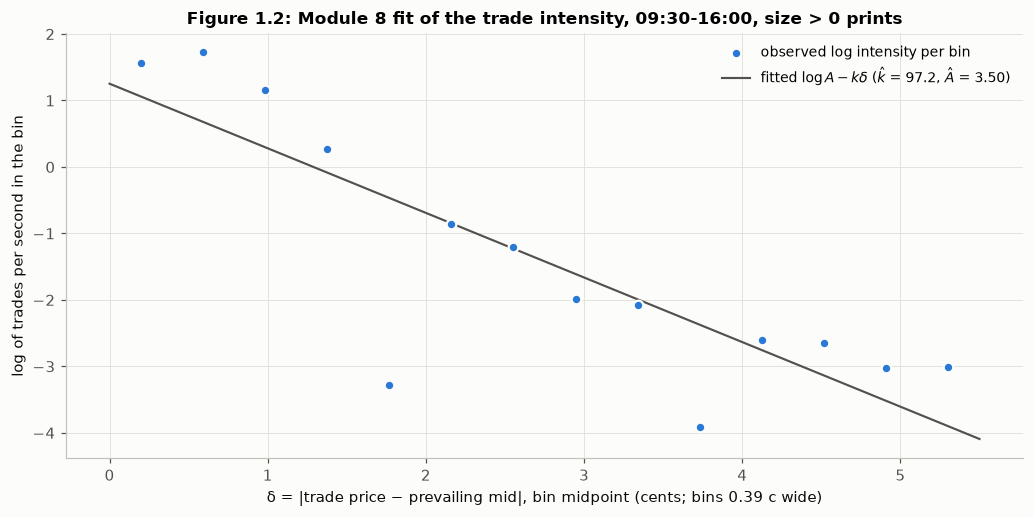

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 4.8))
keep = bin_counts > 0
ax.scatter(100 * bin_mids[keep], np.log(bin_counts[keep] / elapsed_seconds), s=40, color=COLORS["real"],
           edgecolor="#fcfcfb", linewidth=1.5, zorder=3, label="observed log intensity per bin")
d_line = np.linspace(0, bins[-1], 100)
ax.plot(100 * d_line, np.log(A_hat) - k_hat * d_line, color=COLORS["ink"], lw=1.4,
        label=rf"fitted $\log A - k\delta$ ($\hat{{k}}$ = {k_hat:.1f}, $\hat{{A}}$ = {A_hat:.2f})")
ax.set_xlabel(f"δ = |trade price − prevailing mid|, bin midpoint (cents; bins {100 * (bins[1] - bins[0]):.2f} c wide)")
ax.set_ylabel("log of trades per second in the bin")
ax.set_title("Figure 1.2: Module 8 fit of the trade intensity, 09:30-16:00, size > 0 prints")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**Result:** $\hat{k}$ = 97.2 per dollar and $\hat{A}$ = 3.50 per second, with 95% one-minute block bootstrap intervals of 90.4-104.7 and 3.17-3.88. Each extra cent away from the mid cuts the trade rate by a factor of $e^{-0.972}$ = 0.378. These are the values used in `simulate_as` in 1c.

- *Why not the slide's window:* running the same code on the first 300,000 messages gives k = 11.7 and A = 2.38. A few scattered pre-market prints push the 95th percentile of $\delta$ out to 40 cents, so the bins are 2.9 cents wide and can't show the decay within 1-2 cents of the mid. Dropping the size-0 prints matters less (with them left in, k = 103.7 and A = 5.29).
- *Fit quality:* prices are on a penny grid and the mid is on a half-penny grid, so the bin counts zig-zag (885 trades in the 1.571-1.964 c bin vs 30,821 and 9,909 in the bins next to it). The unweighted fit also underpredicts the two busiest bins (2.89 and 1.97 fitted vs 4.79 and 5.60 trades/s observed).
- *Units of A:* A is trades per second per 0.393-cent bin with both sides combined, so it isn't exactly the per-side hit rate `simulate_as` assumes. We check it below and in 1c.
- *Drift:* by half hour, A falls from 6.38 at the open to 1.79 at 13:30 and comes back to 5.7 at the close, while k moves between 87 and 124. This is the reason for the rolling recalibration in Section 7.

#### Checking the fit against the backtest's own fills

`TapeBroker` recorded how long the baseline rested at each distance from the mid and how often it filled there. We compare that with trades that reach *at least* $\delta$ on one side, which is what fills a resting order at $\delta$. Same-side prints less than 1 ms apart are merged into one "burst", since one sweep across venues only fills our 1-share quote once.

In [12]:
DELTA_GRID = np.round(0.005 * np.arange(1, 11), 3)  # 0.5 ... 5 cents from the mid
FIT_RANGE = (0.005, 0.030)
BURST_GAP_S = 0.001
TOL = 1e-9
HALF_CENT = 0.005
calib_trades = rth_trades[rth_trades["size"] > 0]


def aggressor_bursts(trade_frame, gap_s=BURST_GAP_S, merge=True):
    """One row per aggressive burst: consecutive prints on one side of the pre-trade mid, < gap_s apart.

    book_side "bid" = prints below the mid (they would fill a resting buy), "ask" = above it.
    depth = furthest distance from the pre-trade mid reached. merge=False keeps every print as its own row.
    all_dark / any_non_book record whether the burst is made only of off-exchange prints, and whether it
    contains an average-price / derivatively priced / contingent print.
    """
    pieces = []
    for book_side, sign in (("bid", 1.0), ("ask", -1.0)):
        depth = (sign * (trade_frame["mid_before"] - trade_frame["price"])).round(6)
        side = trade_frame.assign(depth=depth, dark=trade_frame["exchange"].eq("DARK"))[depth > TOL]
        gaps = side["time"].diff().dt.total_seconds().fillna(np.inf).to_numpy()
        starts = gaps > gap_s if merge else np.ones(len(side), dtype=bool)
        grouped = side.groupby(np.cumsum(starts)).agg(time=("time", "first"), depth=("depth", "max"),
                                                      prints=("price", "size"), all_dark=("dark", "all"),
                                                      any_non_book=("non_book", "any"))
        pieces.append(grouped.assign(book_side=book_side))
    out = pd.concat(pieces, ignore_index=True)
    out["minute"] = ((out["time"] - SESSION_OPEN).dt.total_seconds() // 60).astype(int)
    return out


def reach_per_side(bursts, deltas=DELTA_GRID):
    """Bursts per side (average of bid and ask) reaching at least each delta over the session."""
    sides = [(bursts.loc[bursts["book_side"] == s, "depth"].to_numpy()[:, None] >= deltas[None, :] - TOL).sum(axis=0)
             for s in ("bid", "ask")]
    return np.mean(sides, axis=0)


def survival_fit(per_side_counts, deltas=DELTA_GRID, fit_range=FIT_RANGE):
    """(k, A) for lambda(delta) = A exp(-k delta) on survival counts: least squares of log rate, weights sqrt(N)."""
    use = (deltas >= fit_range[0] - TOL) & (deltas <= fit_range[1] + TOL)
    n = per_side_counts[use]
    slope, intercept = np.polyfit(deltas[use], np.log(n / SESSION_SECONDS), 1, w=np.sqrt(n))
    return float(-slope), float(np.exp(intercept))


def fill_rate_by_distance(result, deltas=DELTA_GRID):
    """Fills per second of resting time at each quote distance (both sides pooled), and the share of resting time.

    Distances are multiples of half a cent (cent prices against a half-cent mid), so they are grouped as
    integer half-cent ticks to avoid float-equality surprises.
    """
    exposure_ticks = np.rint(result.exposure["distance"] / HALF_CENT).astype(int)
    fill_ticks = np.rint(result.fills["distance"] / HALF_CENT).astype(int)
    seconds = result.exposure.groupby(exposure_ticks.to_numpy())["seconds"].sum()
    n_fills = result.fills.groupby(fill_ticks.to_numpy())["size"].count()
    grid_ticks = np.rint(deltas / HALF_CENT).astype(int)
    rate = (n_fills.reindex(seconds.index, fill_value=0) / seconds).reindex(grid_ticks)
    share = (seconds / seconds.sum()).reindex(grid_ticks, fill_value=0)
    return pd.Series(rate.to_numpy(), index=deltas), pd.Series(share.to_numpy(), index=deltas)


bursts = aggressor_bursts(calib_trades)
burst_counts = reach_per_side(bursts)
print_counts = reach_per_side(aggressor_bursts(calib_trades, merge=False))
lit_counts = reach_per_side(aggressor_bursts(calib_trades[calib_trades["exchange"] != "DARK"]))
book_counts = reach_per_side(aggressor_bursts(calib_trades[~calib_trades["non_book"]]))
bt_rate, bt_share = fill_rate_by_distance(baseline)
fit_share = bt_share.loc[FIT_RANGE[0] - TOL:FIT_RANGE[1] + TOL].sum()

check = pd.DataFrame({
    "prints/s reaching >= delta": print_counts / SESSION_SECONDS,
    "bursts/s reaching >= delta": burst_counts / SESSION_SECONDS,
    "lit-venue bursts/s": lit_counts / SESSION_SECONDS,
    "share of bursts that are all DARK": [bursts.loc[bursts["depth"] >= d - TOL, "all_dark"].mean() for d in DELTA_GRID],
    "backtest fill rate /s": bt_rate.to_numpy(),
    "backtest resting share": bt_share.to_numpy(),
}, index=pd.Index([f"{100 * d:.1f}" for d in DELTA_GRID], name="delta (cents)"))
percent_cols = ["share of bursts that are all DARK", "backtest resting share"]
display(check.style.format({c: "{:.3f}" for c in check.columns} | {c: "{:.1%}" for c in percent_cols}))

survival_fits = pd.DataFrame({
    "bursts, all prints": survival_fit(burst_counts),
    "raw prints": survival_fit(print_counts),
    "bursts, lit venues only": survival_fit(lit_counts),
    "bursts, no average-price / derivatively priced / contingent prints": survival_fit(book_counts),
}, index=["k (per $)", "A (per s, per side)"]).T
display(survival_fits.style.format({"k (per $)": "{:.1f}", "A (per s, per side)": "{:.3f}"}))
k_burst, A_burst = survival_fits.loc["bursts, all prints"]
k_lit, A_lit = survival_fits.loc["bursts, lit venues only"]

triggered_by_dark = (fills["exchange"] == "DARK").mean()
triggered_by_non_book = fills["conditions"].map(lambda c: bool(NON_BOOK_CONDITIONS.intersection(c))).mean()
deep = bursts[bursts["depth"] >= 0.05 - TOL]
show({
    "baseline resting time at 0.5-3 c (the fit range)": f"{fit_share:.1%}",
    "prints per burst (mean)": f"{bursts['prints'].mean():.1f}",
    "baseline fills set off by a DARK print": f"{triggered_by_dark:.1%}",
    "baseline fills set off by an average-price / contingent print": f"{triggered_by_non_book:.1%}",
    "bursts reaching 5 c or more": f"{len(deep):,}",
    "  of which all DARK": f"{deep['all_dark'].mean():.0%}",
    "  of which contain an average-price / contingent print": f"{deep['any_non_book'].mean():.0%}",
}, "1b check")

,prints/s reaching >= delta,bursts/s reaching >= delta,lit-venue bursts/s,share of bursts that are all DARK,backtest fill rate /s,backtest resting share
delta (cents),,,,,,
0.5,6.013,1.975,1.061,46.3%,2.094,6.6%
1.0,3.201,1.113,0.513,50.0%,1.272,8.8%
1.5,1.675,0.576,0.210,55.6%,0.647,23.6%
2.0,1.045,0.376,0.095,66.1%,0.377,29.0%
2.5,0.830,0.312,0.062,72.0%,0.487,15.1%
3.0,0.678,0.268,0.039,77.7%,0.462,9.0%
3.5,0.608,0.245,0.032,79.7%,0.668,3.3%
4.0,0.543,0.225,0.025,81.6%,0.762,1.2%
4.5,0.504,0.210,0.022,82.1%,1.174,0.6%


,k (per $),"A (per s, per side)"
"bursts, all prints",91.5,2.895
raw prints,99.2,9.179
"bursts, lit venues only",146.9,2.181
"bursts, no average-price / derivatively priced / contingent prints",150.2,3.669


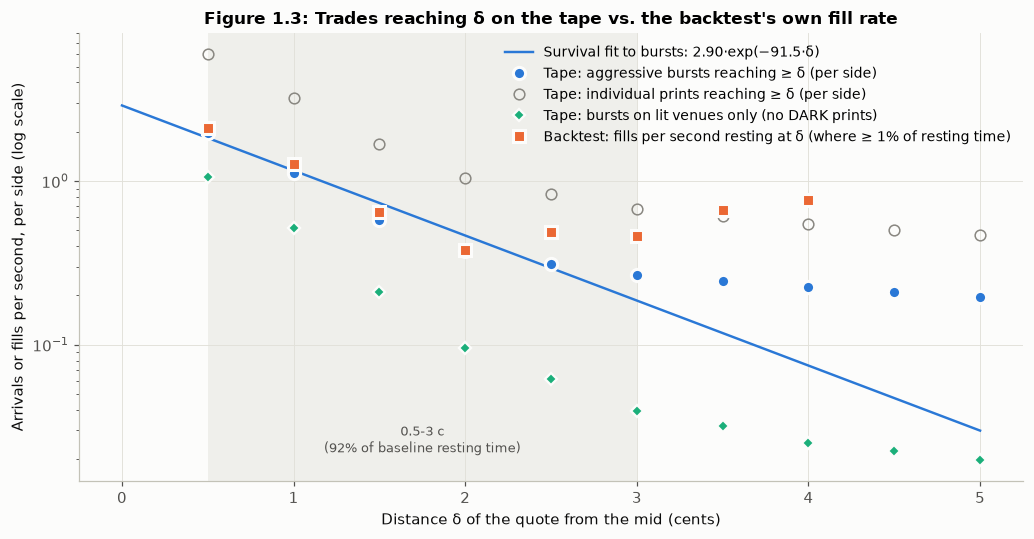

In [13]:
fig, ax = plt.subplots(figsize=(9.5, 5))
lo, hi = FIT_RANGE
ax.axvspan(100 * lo, 100 * hi, color="#e1e0d9", alpha=0.45, lw=0)
ax.text(100 * (lo + hi) / 2, 0.022, f"0.5-3 c\n({fit_share:.0%} of baseline resting time)",
        ha="center", fontsize=8.5, color=COLORS["ink"])
d_fine = np.linspace(0.0, DELTA_GRID.max(), 200)
ax.plot(100 * d_fine, A_burst * np.exp(-k_burst * d_fine), color=COLORS["real"], lw=1.6,
        label=f"Survival fit to bursts: {A_burst:.2f}·exp(−{k_burst:.1f}·δ)")
ax.plot(100 * DELTA_GRID, burst_counts / SESSION_SECONDS, "o", ms=8, color=COLORS["real"], mec="#fcfcfb", mew=2,
        label="Tape: aggressive bursts reaching ≥ δ (per side)")
ax.plot(100 * DELTA_GRID, print_counts / SESSION_SECONDS, "o", ms=7, mfc="none", color=COLORS["muted"],
        label="Tape: individual prints reaching ≥ δ (per side)")
ax.plot(100 * DELTA_GRID, lit_counts / SESSION_SECONDS, "D", ms=6, color=COLORS["accent"], mec="#fcfcfb", mew=1.5,
        label="Tape: bursts on lit venues only (no DARK prints)")
enough_time = bt_share.to_numpy() >= 0.01  # skip distances where the baseline rested < 1% of the time
ax.plot(100 * DELTA_GRID[enough_time], bt_rate.to_numpy()[enough_time], "s", ms=8, color=COLORS["sim"],
        mec="#fcfcfb", mew=2, label="Backtest: fills per second resting at δ (where ≥ 1% of resting time)")
ax.set_yscale("log")
ax.set_xlabel("Distance δ of the quote from the mid (cents)")
ax.set_ylabel("Arrivals or fills per second, per side (log scale)")
ax.set_title("Figure 1.3: Trades reaching δ on the tape vs. the backtest's own fill rate")
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**Result.** The backtest's fill rate lines up with bursts and not with raw prints: 2.09 vs 1.98 per second at 0.5 cents, 1.27 vs 1.11 at 1 cent, 0.65 vs 0.58 at 1.5 cents and 0.377 vs 0.376 at 2 cents. Counting raw prints would overstate it by about 3x, since there are 2.9 prints per burst. A survival fit to bursts over 0.5-3 cents (92% of resting time) gives k = 91.5, close to the Module 8 value of 97.2. The two A's are defined differently, so in 1c we check the Module 8 A by whether the simulation trades about as much as the backtest.

**Note for later sections.** 53% of baseline fills were set off by off-exchange (DARK) prints and 28% by average-price, derivatively priced or contingent prints. None of these can fill an order resting on a lit exchange. Using lit venues only gives k = 147 and A = 2.18, and only 0.095 bursts per second reach 2 cents compared with 0.376 overall. So the baseline fill model is already optimistic before queue position comes into it (Section 4).

### 1c - Calibrated `simulate_as` vs. the real `main.py` backtest

- **Setup.** One 23,400-second session (`T = 23_400`, `dt = 0.01` s, the same 10 ms grid as 1a) using $\hat\sigma$, $\hat A$, $\hat k$, the 09:30 mid as `s0`, and `max_inv = 20` as in `main.py`. We run 20 seeds (`SEED + i`) and one `dt = 0.005` check.
- **$\gamma$** can't be estimated from the tape. We set it so the A-S skew $\gamma\sigma^2\tau$ equals `main.py`'s 1 cent per share at mid-session ($\tau = T/2$).
- **P&L split.** Both runs are marked at the mid and split into spread capture, $\sum$(mid at fill - buy price) + $\sum$(sell price - mid at fill), and inventory P&L (everything else).
- **Second backtest.** `main.py` always quotes 2 cents wider than the NBBO. When the NBBO is crossed by 2 cents or more, its bid ends up at or above its own ask and `FakeBroker` fills both. To separate this from real market behaviour we also run `main.py` with both quotes pulled while the NBBO it has seen is crossed (`skip_when_crossed`). We only use this run as a diagnostic.

In [14]:
SIM_DT = 0.01  # 10 ms steps: the same grid sigma_hat was estimated on in 1a
CHECK_DT = 0.005
N_SIM_PATHS = 20
gamma = main.INVENTORY_SKEW / (sigma_hat ** 2 * SESSION_SECONDS / 2)
s0 = mid_1s[0]


def as_half_spread(tau):
    return (1 / gamma) * np.log(1 + gamma / k_hat) + 0.5 * gamma * sigma_hat ** 2 * tau


typical_bt_distance = (baseline.exposure["distance"] * baseline.exposure["seconds"]).sum() / baseline.exposure["seconds"].sum()
as_skew = 100 * gamma * sigma_hat ** 2 * SESSION_SECONDS  # cents per share of inventory at 09:30


def hit_probability(tau):
    return 1 - np.exp(-A_hat * np.exp(-k_hat * as_half_spread(tau)) * SIM_DT)


def run_sim(seed, dt=SIM_DT):
    """One calibrated simulate_as path, reduced to a 1-second grid plus exact fill and capture totals."""
    times, mid, inv, pnl = simulate_as(np.random.default_rng(seed), T=SESSION_SECONDS, dt=dt,
                                       sigma=sigma_hat, gamma=gamma, k=k_hat, A=A_hat, s0=s0,
                                       max_inv=main.MAX_INVENTORY)
    cash = pnl - inv * mid
    d_inv, d_cash = np.diff(inv), np.diff(cash)
    both_sides = (d_inv == 0) & (np.abs(d_cash) > 1e-6)  # a buy and a sell in the same step
    inventory_pnl = np.sum(inv[1:] * np.diff(mid))
    step, per_minute = int(round(1 / dt)), int(round(60 / dt))
    minute_max = np.abs(inv[:SESSION_MINUTES * per_minute]).reshape(SESSION_MINUTES, per_minute).max(axis=1)
    return {"pnl": pnl[::step], "inventory": inv[::step], "minute_max_inv": minute_max,
            "fills": np.abs(d_inv).sum() + 2 * both_sides.sum(), "capture": pnl[-1] - inventory_pnl}


started = walltime.perf_counter()
sims = [run_sim(SEED + i) for i in range(N_SIM_PATHS)]
sim_seconds = walltime.perf_counter() - started
assert all(len(s["pnl"]) == len(paths) for s in sims)
fine = run_sim(SEED, dt=CHECK_DT)

show({
    "gamma (per $)": f"{gamma:.5f}",
    "A-S skew per share at 09:30 / 12:45 / 16:00 (c)": f"{as_skew:.2f} / {as_skew / 2:.2f} / 0",
    "main.py skew per share, all day (c)": f"{100 * main.INVENTORY_SKEW:.2f}",
    "A-S half-spread at 09:30 / 12:45 / 16:00 (c)": f"{100 * as_half_spread(SESSION_SECONDS):.2f} / "
                                                    f"{100 * as_half_spread(SESSION_SECONDS / 2):.2f} / {100 * as_half_spread(0):.2f}",
    "main.py mean quote distance from the mid (c)": f"{100 * typical_bt_distance:.2f}",
    "A-S hit probability per step, 09:30 / 16:00": f"{hit_probability(SESSION_SECONDS):.1%} / {hit_probability(0):.1%}",
    "simulate_as paths / run time (s)": f"{N_SIM_PATHS} / {sim_seconds:.0f}",
    f"fills on seed {SEED}, dt = {SIM_DT} s / {CHECK_DT} s": f"{sims[0]['fills']:,.0f} / {fine['fills']:,.0f}",
}, "1c setup")

,1c setup
gamma (per $),0.00307
A-S skew per share at 09:30 / 12:45 / 16:00 (c),2.00 / 1.00 / 0
"main.py skew per share, all day (c)",1.00
A-S half-spread at 09:30 / 12:45 / 16:00 (c),2.03 / 1.53 / 1.03
main.py mean quote distance from the mid (c),1.90
"A-S hit probability per step, 09:30 / 16:00",0.5% / 1.3%
simulate_as paths / run time (s),20 / 620
"fills on seed 4170, dt = 0.01 s / 0.005 s","47,214 / 47,234"


In [15]:
def skip_when_crossed(tick_handler):
    """Run the tick handler unchanged, then pull both quotes while the NBBO the strategy has seen is crossed."""
    def guarded_handler(broker, book):
        tick_handler(broker, book)
        if book["best_bid"] is not None and book["best_ask"] < book["best_bid"]:
            broker.cancel_order("buy")
            broker.cancel_order("sell")
    return guarded_handler


guarded = run_session(tick_handler=skip_when_crossed(main.handle_next_tick))
guarded_paths = session_paths(guarded.fills, quotes)
assert guarded.messages_read == baseline.messages_read  # same tape, same evaluation window


def double_fills(result):
    """Prints that filled our bid and our ask at once (our own quotes crossed), and the loss they locked in."""
    f = result.fills
    pairs = f[f.groupby("time")["side"].transform("nunique") == 2]
    locked_in = pairs.loc[pairs["side"] == "buy", "price"].sum() - pairs.loc[pairs["side"] == "sell", "price"].sum()
    return pairs["time"].nunique(), locked_in, pairs["time"].drop_duplicates()


n_double, double_loss, double_times = double_fills(baseline)
n_double_guarded, _, _ = double_fills(guarded)


def doubles_in_minute(start):
    return double_times.between(start, start + pd.Timedelta(minutes=1), inclusive="left").sum()


# The real backtest's worst drawdown, located on the 1-second grid.
real_pnl = paths["pnl"].to_numpy()
real_dd = np.maximum.accumulate(real_pnl) - real_pnl
trough = int(real_dd.argmax())
peak = int(np.flatnonzero(real_dd[:trough] < 1e-9)[-1])
recovered = trough + int(np.flatnonzero(real_dd[trough:] < 1e-9)[0])
t_peak, t_trough = paths.index[peak], paths.index[trough]
window = fills[fills["time"].between(t_peak, t_trough)]

# Event-level inventory extremes (the 1-second grid can miss them).
event_inventory = fills["signed"].cumsum()


def inventory_range(start, end):
    sel = fills["time"].between(start, end)
    return f"{event_inventory[sel].min():+d} to {event_inventory[sel].max():+d}"


through_mid = fills[fills["distance"] <= 0]
through_capture = (through_mid["signed"] * (through_mid["mid"] - through_mid["price"])).sum()

show({
    "prints that filled both quotes": n_double,
    "  locked-in loss ($)": f"{double_loss:.2f}",
    "  in the 09:30 minute": doubles_in_minute(SESSION_OPEN),
    "  in the 10:31 minute": doubles_in_minute(SESSION_OPEN + pd.Timedelta(minutes=61)),
    "  with the crossed-NBBO guard": n_double_guarded,
    "worst drawdown ($)": f"{real_dd.max():.2f}",
    "  peak / trough / recovered": f"{t_peak:%H:%M:%S} / {t_trough:%H:%M:%S} / {paths.index[recovered]:%H:%M:%S}",
    "  mid at peak / low / trough": f"{mid_1s[peak]:.3f} / {mid_1s[peak:trough + 1].min():.3f} / {mid_1s[trough]:.3f}",
    "  fills in the window": f"{len(window):,}",
    "  of which against a crossed NBBO": f"{(window['bid'] > window['ask']).sum():,}",
    "  prints filling both quotes in the window": double_times.between(t_peak, t_trough).sum(),
    "inventory range 09:30-09:31, event level": inventory_range(SESSION_OPEN, SESSION_OPEN + pd.Timedelta(minutes=1)),
    "inventory range in the drawdown window": inventory_range(t_peak, t_trough),
    "fills at or through the mid": f"{len(through_mid):,} ({len(through_mid) / len(fills):.1%})",
    "  their spread capture ($)": f"{through_capture:.2f}",
}, "real backtest")

In [16]:
def path_metrics(pnl, inventory, fills, capture):
    pnl, inventory = np.asarray(pnl, dtype=float), np.asarray(inventory, dtype=float)
    drawdown = np.maximum.accumulate(pnl) - pnl  # P&L starts at 0, so the first peak is 0
    return {
        "Fills (shares)": fills,
        "Spread capture ($)": capture,
        "Capture per share (cents)": 100 * capture / fills,
        "Inventory P&L ($)": pnl[-1] - capture,
        "Session P&L at 16:00 ($)": pnl[-1],
        "P&L volatility, 1-min changes ($)": np.std(np.diff(pnl[::60]), ddof=1),
        "Max drawdown ($)": drawdown.max(),
        "Mean |inventory| (shares)": np.abs(inventory).mean(),
        "Max |inventory|, 1-s grid (shares)": np.abs(inventory).max(),
        "Time at |inventory| >= 5 (%)": 100 * np.mean(np.abs(inventory) >= 5),
    }


def real_path_metrics(result, result_paths):
    f = result.fills
    capture = (f["signed"] * (f["mid"] - f["price"])).sum()
    return pd.Series(path_metrics(result_paths["pnl"], result_paths["inventory"], f["size"].sum(), capture))


sim_metrics = pd.DataFrame([path_metrics(s["pnl"], s["inventory"], s["fills"], s["capture"]) for s in sims])
comparison = pd.DataFrame({
    "Real main.py backtest": real_path_metrics(baseline, paths),
    "Real, no quotes while NBBO crossed": real_path_metrics(guarded, guarded_paths),
    "simulate_as median": sim_metrics.median(),
    "sim 10th pct": sim_metrics.quantile(0.10),
    "sim 90th pct": sim_metrics.quantile(0.90),
})
comparison.style.format("{:,.2f}")

,Real main.py backtest,"Real, no quotes while NBBO crossed",simulate_as median,sim 10th pct,sim 90th pct
Fills (shares),"41,072.00","40,178.00","47,177.00","46,759.40","47,504.70"
Spread capture ($),482.26,543.40,486.52,482.31,490.05
Capture per share (cents),1.17,1.35,1.03,1.03,1.03
Inventory P&L ($),-234.71,-232.04,1.38,-4.22,4.32
Session P&L at 16:00 ($),247.54,311.35,486.88,480.72,491.87
"P&L volatility, 1-min changes ($)",3.95,1.09,0.28,0.25,0.30
Max drawdown ($),81.65,20.72,0.88,0.51,1.82
Mean |inventory| (shares),0.51,0.50,0.67,0.66,0.70
"Max |inventory|, 1-s grid (shares)",20.00,20.00,15.00,13.90,20.00
Time at |inventory| >= 5 (%),0.29,0.28,1.19,0.99,1.53


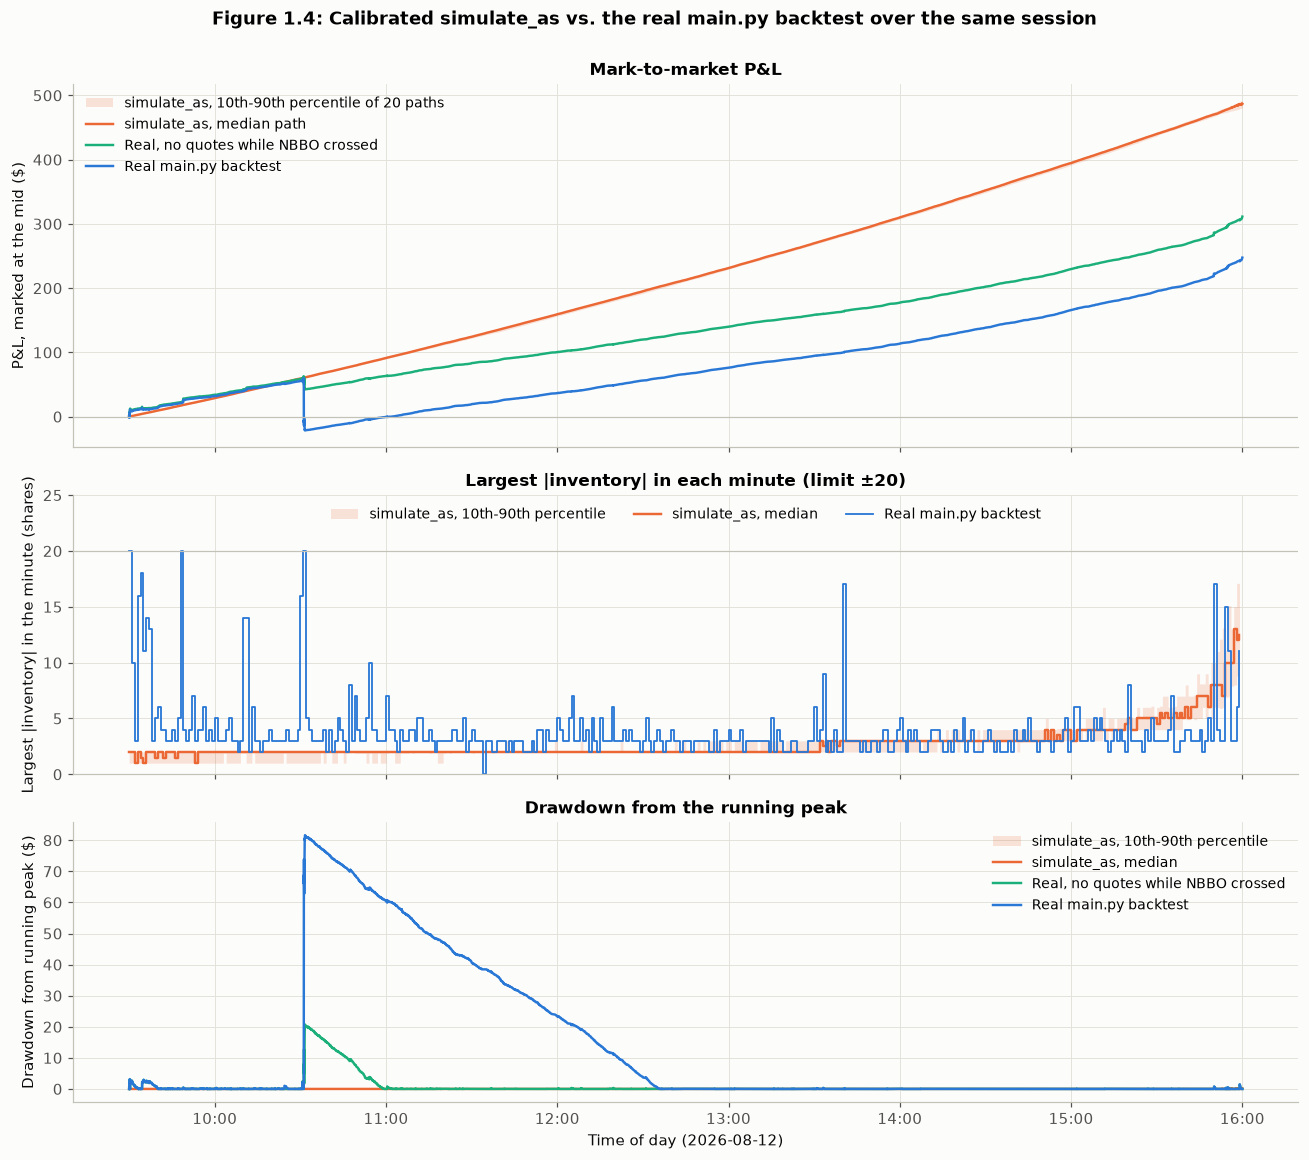

In [17]:
def minute_max_abs_inventory(fills):
    """Largest |inventory| reached in each session minute, at event level (not just on the 1-s grid)."""
    inventory = fills["signed"].cumsum()
    minute = ((fills["time"] - SESSION_OPEN).dt.total_seconds() // 60).astype(int).to_numpy()
    within = inventory.abs().groupby(minute).max().reindex(range(SESSION_MINUTES)).to_numpy()
    at_start = np.abs(np.nan_to_num(prevailing(fills["time"], inventory, session_grid(60)[:-1])))
    return np.fmax(within, at_start)


grid = paths.index
minutes = session_grid(60)[:-1]
sim_pnl = np.vstack([s["pnl"] for s in sims])
sim_dd = np.maximum.accumulate(sim_pnl, axis=1) - sim_pnl
sim_minute_inv = np.vstack([s["minute_max_inv"] for s in sims])
guarded_pnl = guarded_paths["pnl"].to_numpy()
guarded_dd = np.maximum.accumulate(guarded_pnl) - guarded_pnl
LABEL_REAL, LABEL_GUARD = "Real main.py backtest", "Real, no quotes while NBBO crossed"

fig, axes = plt.subplots(3, 1, figsize=(12, 10.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.fill_between(grid, np.percentile(sim_pnl, 10, axis=0), np.percentile(sim_pnl, 90, axis=0),
                color=COLORS["sim"], alpha=0.18, lw=0, label="simulate_as, 10th-90th percentile of 20 paths")
ax.plot(grid, np.median(sim_pnl, axis=0), color=COLORS["sim"], label="simulate_as, median path")
ax.plot(grid, guarded_pnl, color=COLORS["accent"], label=LABEL_GUARD)
ax.plot(grid, real_pnl, color=COLORS["real"], label=LABEL_REAL)
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_ylabel("P&L, marked at the mid ($)")
ax.set_title("Mark-to-market P&L")
ax.legend(fontsize=9, loc="upper left")

ax = axes[1]
ax.fill_between(minutes, np.percentile(sim_minute_inv, 10, axis=0), np.percentile(sim_minute_inv, 90, axis=0),
                step="post", color=COLORS["sim"], alpha=0.18, lw=0, label="simulate_as, 10th-90th percentile")
ax.step(minutes, np.median(sim_minute_inv, axis=0), where="post", color=COLORS["sim"], label="simulate_as, median")
ax.step(minutes, minute_max_abs_inventory(fills), where="post", color=COLORS["real"], lw=1.2, label=LABEL_REAL)
ax.axhline(main.MAX_INVENTORY, color="#c3c2b7", lw=0.8)
ax.set_ylim(0, main.MAX_INVENTORY + 5)
ax.set_ylabel("Largest |inventory| in the minute (shares)")
ax.set_title(f"Largest |inventory| in each minute (limit ±{main.MAX_INVENTORY})")
ax.legend(fontsize=9, loc="upper center", ncols=3)

ax = axes[2]
ax.fill_between(grid, np.percentile(sim_dd, 10, axis=0), np.percentile(sim_dd, 90, axis=0),
                color=COLORS["sim"], alpha=0.18, lw=0, label="simulate_as, 10th-90th percentile")
ax.plot(grid, np.median(sim_dd, axis=0), color=COLORS["sim"], label="simulate_as, median")
ax.plot(grid, guarded_dd, color=COLORS["accent"], label=LABEL_GUARD)
ax.plot(grid, real_dd, color=COLORS["real"], label=LABEL_REAL)
ax.set_ylabel("Drawdown from running peak ($)")
ax.set_title("Drawdown from the running peak")
ax.legend(fontsize=9, loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_xlabel("Time of day (2026-08-12)")
fig.suptitle("Figure 1.4: Calibrated simulate_as vs. the real main.py backtest over the same session",
             fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

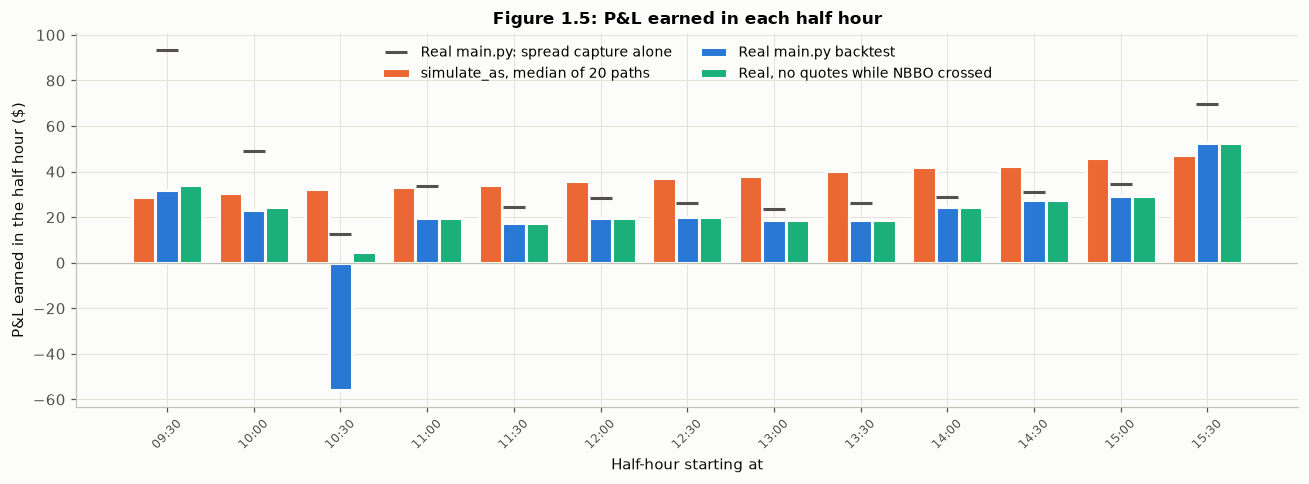

In [18]:
def half_hour_increments(pnl_1s):
    return np.diff(np.asarray(pnl_1s)[::1800])


def half_hour_capture(result):
    f = result.fills
    bucket = ((f["time"] - SESSION_OPEN).dt.total_seconds() // 1800).astype(int)
    return (f["signed"] * (f["mid"] - f["price"])).groupby(bucket).sum().reindex(range(13), fill_value=0).to_numpy()


real_inc, guarded_inc = half_hour_increments(real_pnl), half_hour_increments(guarded_pnl)
sim_inc_median = np.median(np.vstack([half_hour_increments(s["pnl"]) for s in sims]), axis=0)
real_capture_hh = half_hour_capture(baseline)

x = np.arange(13)
width = 0.27
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(x - width, sim_inc_median, width=width, color=COLORS["sim"], edgecolor="#fcfcfb", linewidth=2,
       label="simulate_as, median of 20 paths")
ax.bar(x, real_inc, width=width, color=COLORS["real"], edgecolor="#fcfcfb", linewidth=2, label=LABEL_REAL)
ax.bar(x + width, guarded_inc, width=width, color=COLORS["accent"], edgecolor="#fcfcfb", linewidth=2, label=LABEL_GUARD)
ax.plot(x, real_capture_hh, "_", ms=14, mew=2, color=COLORS["ink"], label="Real main.py: spread capture alone")
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xticks(x, half_hour_labels, rotation=45, fontsize=8)
ax.set_xlabel("Half-hour starting at")
ax.set_ylabel("P&L earned in the half hour ($)")
ax.set_title("Figure 1.5: P&L earned in each half hour")
ax.legend(fontsize=9, loc="upper center", ncols=2)
fig.tight_layout()
plt.show()

half_hours_table = pd.DataFrame({
    "sim median P&L": sim_inc_median, "real P&L": real_inc, "real spread capture": real_capture_hh,
    "real inventory P&L": real_inc - real_capture_hh, "guarded P&L": guarded_inc,
    "guarded inventory P&L": guarded_inc - half_hour_capture(guarded),
}, index=half_hour_labels)
display(half_hours_table.round(1).T)

**Where they agree.** The two match on volume and spread capture. The simulation fills 47,177 shares (median of 20 paths, 10th-90th percentile 46,759-47,505) compared with 41,072 in the backtest, and it captures \$487 of spread compared with \$482. Mean |inventory| is also similar (0.67 vs 0.51 shares).

**Where they diverge.** They differ on what happens after the fill.
- *P&L:* simulated inventory P&L is just noise around zero (-\$4.22 to +\$4.32 in 80% of paths). The real book loses \$234.71 on inventory, losing in all 13 half hours, and ends at \$247.54, which is 51% of the simulated \$486.88.
- *Drawdown:* the simulated P&L is close to a straight line (1-minute volatility \$0.28, max drawdown \$0.88). The real book has \$3.95 and \$81.65.
- *Inventory:* real inventory swings from -20 to +20 in the first minute and again during 10:31:10-10:31:37. Simulated inventory is loosest near the close, because the A-S skew decays to zero there.

**Why they diverge.**
1. *Self-crossing.* 291 prints filled both of `main.py`'s quotes at once, locking in \$57.20 of losses, and 177 of them were in the 10:31 minute. With the crossed-NBBO guard the strategy ends at \$311.35 with a \$20.72 max drawdown.
2. *Adverse selection.* In A-S, fills are independent of the price path, so inventory P&L averages zero. On the real tape, the burst that hits our bid is the same selling that pushes the mid down. This costs about 0.57 cents per filled share, against 1.17 cents captured. Section 6 measures this with markout.
3. *Changing conditions.* The model uses one $\sigma$ and one $\lambda$ for the whole day. On the tape, volatility varies 3.5x, trade rates at the open and close are about three times the midday rate, and the 10:31 move was 32 five-second standard deviations. Most of the real book's losses come in a few short episodes like this.
4. *Policy differences.* A-S skews 2 cents per share at the open and nothing at the close, and it quotes off a continuous mid instead of a penny grid.

**Summary.** The calibrated `simulate_as` gets volume and spread capture about right but misses what happens after each fill. It overstates `main.py`'s P&L by about 97% and understates its max drawdown by about 93x (56% and 24x once the self-crossing is removed).

### Section 1 summary: calibrated parameters carried forward

| Parameter | Estimate | Uncertainty | Units |
|---|---|---|---|
| $\sigma$ (mid volatility, 1a) | 0.0167 | 0.0167-0.0198 across 10 ms-2 min sampling | dollars per $\sqrt{s}$ |
| $k$ (Module 8 fit, 1b) | 97.2 | bootstrap 90.4-104.7; 87-124 across half hours | per dollar |
| $A$ (Module 8 fit, 1b) | 3.50 | bootstrap 3.17-3.88; 1.8-6.4 across half hours | trades per second per 0.393 c bin |
| $k$, $A$ survival fit to bursts (check) | 91.5, 2.90 | | per dollar, per second per side |
| $k$, $A$ lit venues only (check) | 147, 2.18 | | per dollar, per second per side |
| $\gamma$ (chosen, 1c) | 0.00307 | $\gamma\hat{\sigma}^2 T/2$ = `INVENTORY_SKEW` | per dollar |

All of these are full-session, in-sample estimates that drift during the day, and Section 7 refits $\sigma$ on a rolling basis. Two findings carry forward: 53% of baseline fills come from off-exchange prints (1b), and `main.py`'s quotes cross each other when the NBBO is crossed by 2 cents or more (1c).

## Section 2 - Trading Fees and Rebates: How Much Do They Matter?

Only the fee schedule changes here. The strategy, front-of-queue fills, zero latency and full session are the same as in Section 1, so none of these numbers are live estimates. *Gross P&L* is cash plus 16:00 inventory at the mid (\$247.54). *Net P&L* = gross + rebates - fees - flattening cost. We use Module 8's rates: a maker rebate of \$0.0020-0.0028 per share (headline $\rho$ = \$0.0025) and a taker fee of \$0.0030 per share. An inverted venue is a negative $\rho$.

### 2a - Maker rebate on every fill

`FeeBroker` adds $\rho \times$ size to `rebate_total` for every `OrderFilled`, buy or sell, without changing the matching or `book["cash"]`. On the first 300,000 messages, at $\rho$ = \$0.0025 and -\$0.0030, it gives exactly the same fills as `TapeBroker` and books $\rho$ on every filled share. The rebate never changes a fill, so full-day rebate revenue is just $\rho \times$ 41,072 shares.

In [19]:
from functools import partial

RHO_HEADLINE = 0.0025                 # $/share, middle of Module 8's 0.0020-0.0028 maker rebate
RHO_REALISTIC = (0.0020, 0.0028)
RHO_INVERTED_CHECK = -0.0030          # an inverted venue charging the maker
TAKER_FEE = 0.0030                    # $/share, Module 8's taker fee


class FeeBroker(TapeBroker):
    """TapeBroker that books a maker rebate of `maker_rebate` dollars per share on every OrderFilled."""

    def __init__(self, data_path, maker_rebate=0.0):
        super().__init__(data_path)
        self.maker_rebate = maker_rebate
        self.rebate_total = 0.0
        self.rebated_shares = 0

    def poll(self):
        messages = super().poll()
        for message in messages:
            if isinstance(message, OrderFilled):
                self.rebate_total += self.maker_rebate * message.size
                self.rebated_shares += message.size
        return messages


CHECK_WINDOW = 300_000  # first 300k messages: enough for a fill-for-fill check without replaying the whole day
fill_key = ["time", "side", "price", "size"]
plain = run_session(max_messages=CHECK_WINDOW)
check_shares = int(plain.fills["size"].sum())
for rho in (RHO_HEADLINE, RHO_INVERTED_CHECK):
    run = run_session(broker_cls=partial(FeeBroker, maker_rebate=rho), max_messages=CHECK_WINDOW)
    assert run.fills[fill_key].equals(plain.fills[fill_key])        # the rebate changes no fill
    assert run.broker.rebated_shares == check_shares                 # every filled share earned rho
    assert np.isclose(run.broker.rebate_total, rho * check_shares)
    print(f"rho = {rho:+.4f}: {len(run.fills):,} fills match TapeBroker, rebates ${run.broker.rebate_total:,.2f}")
del plain, run

gross_pnl = paths["pnl"].iloc[-1]          # Section 1 baseline, 16:00 inventory marked at the mid
filled_shares = int(fills["size"].sum())

rho = +0.0025: 4,292 fills match TapeBroker, rebates $10.73


rho = -0.0030: 4,292 fills match TapeBroker, rebates $-12.88


In [20]:
headline_rebates = RHO_HEADLINE * filled_shares  # exact, by the check above
real_capture = (fills["signed"] * (fills["mid"] - fills["price"])).sum()  # spread capture vs the pre-trade mid (1c)
attribution = pd.DataFrame({
    "maker rebate rho ($/share)": [RHO_REALISTIC[0], RHO_HEADLINE, RHO_REALISTIC[1]],
}).set_index("maker rebate rho ($/share)")
attribution["rebate revenue ($)"] = attribution.index * filled_shares
attribution["as % of gross P&L"] = 100 * attribution["rebate revenue ($)"] / gross_pnl
attribution["net P&L before flattening ($)"] = gross_pnl + attribution["rebate revenue ($)"]
attribution["rebate share of net P&L (%)"] = 100 * attribution["rebate revenue ($)"] / attribution["net P&L before flattening ($)"]

show({
    "gross P&L ($)": f"{gross_pnl:,.2f}",
    "filled shares": f"{filled_shares:,}",
    "gross P&L per share (c)": f"{100 * gross_pnl / filled_shares:.3f}",
    "  spread capture per share (c)": f"{100 * real_capture / filled_shares:.3f}",
    "  inventory P&L per share (c)": f"{100 * (gross_pnl - real_capture) / filled_shares:+.3f}",
}, "baseline")
display(attribution.style.format({"rebate revenue ($)": "{:,.2f}", "as % of gross P&L": "{:.1f}",
                                  "net P&L before flattening ($)": "{:,.2f}", "rebate share of net P&L (%)": "{:.1f}"}))

# Caveat on "always the passive side": main.py re-sends both quotes after every message, so the order behind each
# fill was placed against the NBBO logged with that fill. Buys priced at/above the offer, or sells at/below the bid,
# were marketable when placed and would really have executed as taker orders.
marketable = (((fills["side"] == "buy") & (fills["price"] >= fills["ask"] - 1e-9))
              | ((fills["side"] == "sell") & (fills["price"] <= fills["bid"] + 1e-9)))
marketable_shares = int(fills.loc[marketable, "size"].sum())
show({
    "shares filled on quotes marketable when placed": f"{marketable_shares:,} ({marketable_shares / filled_shares:.1%})",
    "  of which in a crossed NBBO": f"{int((marketable & (fills['bid'] > fills['ask'])).sum()):,}",
    "  cost if charged the taker fee instead of the rebate ($)": f"{marketable_shares * (RHO_HEADLINE + TAKER_FEE):,.2f}",
}, "marketable quotes")

,rebate revenue ($),as % of gross P&L,net P&L before flattening ($),rebate share of net P&L (%)
maker rebate rho ($/share),,,,
0.002000,82.14,33.2,329.68,24.9
0.002500,102.68,41.5,350.22,29.3
0.002800,115.00,46.5,362.54,31.7


**Result:** at $\rho$ = \$0.0025 the strategy earns **\$102.68 in rebates, which is 41.5% of its \$247.54 gross P&L** (33.2-46.5% across \$0.0020-0.0028). Rebates are this large relative to P&L because the gross edge is small: 0.603 cents per share, compared with a 0.25-cent rebate.

*Caveat:* 5,728 filled shares (13.9%) came from quotes that were already marketable when they were placed, so in reality they would have executed as taker orders. Charging those the taker fee instead of paying the rebate would cost \$31.50.

### 2b - Rebate sweep and breakeven

Fills don't depend on $\rho$, so net($\rho$) = gross + $\rho \times$ shares exactly. We sweep $\rho$ from -\$0.0090 to +\$0.0030 in \$0.0005 steps, which covers zero, the realistic range and inverted venues. The breakeven is $\rho^*$ = -gross / shares. We show it with and without 2c's flattening cost, and also for the crossed-NBBO-guarded run from 1c.

In [21]:
NBBO_AT_CLOSE = {side: float(prevailing(quotes["time"], quotes[side], [SESSION_CLOSE])[0]) for side in ("bid", "ask")}


def flatten_at_close(result_paths, taker_fee=TAKER_FEE):
    """One marketable order at 16:00 that closes the inventory against the prevailing NBBO, costed against the mid mark."""
    q = float(result_paths["inventory"].iloc[-1])
    bid, ask = NBBO_AT_CLOSE["bid"], NBBO_AT_CLOSE["ask"]
    mid = 0.5 * (bid + ask)
    exit_price = bid if q > 0 else ask
    return {"inventory (shares)": q, "exit price": exit_price,
            "spread cost vs mid ($)": abs(q) * abs(mid - exit_price),
            "taker fee ($)": taker_fee * abs(q),
            "total flattening cost ($)": abs(q) * abs(mid - exit_price) + taker_fee * abs(q)}


variants_2 = {
    "main.py baseline": (gross_pnl, filled_shares, flatten_at_close(paths)),
    "baseline, no quotes while NBBO crossed": (guarded_paths["pnl"].iloc[-1], int(guarded.fills["size"].sum()),
                                               flatten_at_close(guarded_paths)),
}


def net_pnl(gross, shares, rho, flatten_cost=0.0):
    return gross + rho * shares - flatten_cost



RHO_GRID = np.unique(np.round(np.r_[np.arange(-0.0090, 0.00301, 0.0005), RHO_REALISTIC, RHO_HEADLINE], 4))
sweep = pd.DataFrame({"rho ($/share)": RHO_GRID})
breakevens = {}
for name, (gross, shares, flat) in variants_2.items():
    sweep[f"{name}: net, held at mid ($)"] = net_pnl(gross, shares, RHO_GRID)
    sweep[f"{name}: net, flattened ($)"] = net_pnl(gross, shares, RHO_GRID, flat["total flattening cost ($)"])
    breakevens[name] = {"held to the close, marked at the mid": -gross / shares,
                        "flattened at 16:00 with taker fee": -(gross - flat["total flattening cost ($)"]) / shares}
    assert RHO_GRID.min() < min(breakevens[name].values()) < RHO_GRID.max()  # the grid brackets the breakeven

shown = [-0.009, -0.008, -0.007, -0.006, -0.005, -0.004, -0.003, -0.002, -0.001, 0.0, 0.001, 0.002, 0.0025, 0.0028, 0.003]
shown_rows = np.isclose(sweep["rho ($/share)"].to_numpy()[:, None], shown).any(axis=1)
display(sweep[shown_rows].style.hide(axis="index")
        .format({"rho ($/share)": "{:+.4f}"} | {c: "{:,.2f}" for c in sweep.columns[1:]}))
breakeven_table = pd.DataFrame(breakevens).T
breakeven_table.index.name = "breakeven rho* ($/share)"
display(breakeven_table.style.format("{:+.5f}"))

rho ($/share),"main.py baseline: net, held at mid ($)","main.py baseline: net, flattened ($)","baseline, no quotes while NBBO crossed: net, held at mid ($)","baseline, no quotes while NBBO crossed: net, flattened ($)"
-0.0090,-122.11,-122.25,-50.25,-50.39
-0.0080,-81.04,-81.17,-10.07,-10.21
-0.0070,-39.96,-40.10,30.10,29.97
-0.0060,1.11,0.97,70.28,70.14
-0.0050,42.18,42.04,110.46,110.32
-0.0040,83.25,83.11,150.64,150.50
-0.0030,124.32,124.19,190.82,190.68
-0.0020,165.40,165.26,230.99,230.86
-0.0010,206.47,206.33,271.17,271.03
+0.0000,247.54,247.40,311.35,311.21


**Result:** each 0.1 cents of rebate is worth \$41.07. Net P&L crosses zero at **$\rho^*$ = -\$0.00602 per share** after flattening (-\$0.00603 without). So the baseline stays profitable until a venue *charges* makers about 0.6 cents a share, which is twice the taker fee. At an inverted -\$0.0030 it still makes \$124.19. Without the self-crossing fills, $\rho^*$ moves to -\$0.00775.

### 2c - End-of-day flattening with a taker fee

At 16:00 one marketable order sells a long position at the bid (or buys back a short at the ask), using the NBBO the strategy has already seen. It is the only trade that pays the \$0.0030 taker fee. Against the mid mark it costs half the spread plus the fee.

In [22]:
flattening = pd.DataFrame({name: flat for name, (_, _, flat) in variants_2.items()})
display(flattening.style.format("{:,.3f}"))

flat = variants_2["main.py baseline"][2]
close_spread = NBBO_AT_CLOSE["ask"] - NBBO_AT_CLOSE["bid"]
show({
    "NBBO at 16:00 (bid / ask)": f"{NBBO_AT_CLOSE['bid']:.2f} / {NBBO_AT_CLOSE['ask']:.2f}",
    "headline rebate revenue ($)": f"{headline_rebates:,.2f}",
    "taker fee as % of rebate revenue": f"{flat['taker fee ($)'] / headline_rebates:.4%}",
    "total flattening cost as % of rebate revenue": f"{flat['total flattening cost ($)'] / headline_rebates:.3%}",
    f"taker fee to flatten {main.MAX_INVENTORY} shares ($)": f"{TAKER_FEE * main.MAX_INVENTORY:.3f}",
    f"half-spread to flatten {main.MAX_INVENTORY} shares ($)": f"{main.MAX_INVENTORY * close_spread / 2:.2f}",
}, "2c")

,main.py baseline,"baseline, no quotes while NBBO crossed"
inventory (shares),6.000,6.000
exit price,772.590,772.590
spread cost vs mid ($),0.120,0.120
taker fee ($),0.018,0.018
total flattening cost ($),0.138,0.138


,2c
NBBO at 16:00 (bid / ask),772.59 / 772.63
headline rebate revenue ($),102.68
taker fee as % of rebate revenue,0.0175%
total flattening cost as % of rebate revenue,0.134%
taker fee to flatten 20 shares ($),0.060
half-spread to flatten 20 shares ($),0.40


**Result:** the book ends the day long 6 shares, with a 16:00 NBBO of 772.59 / 772.63. Flattening costs \$0.120 of half-spread plus **\$0.018 of taker fee, which is 0.0175% of the day's \$102.68 in rebates**. Even flattening the full 20-share limit would only cost \$0.06 in fees. The inventory skew keeps inventory close to zero, so this trade barely matters.

### 2d - Net P&L as a function of $\rho$, and the answer for the head trader

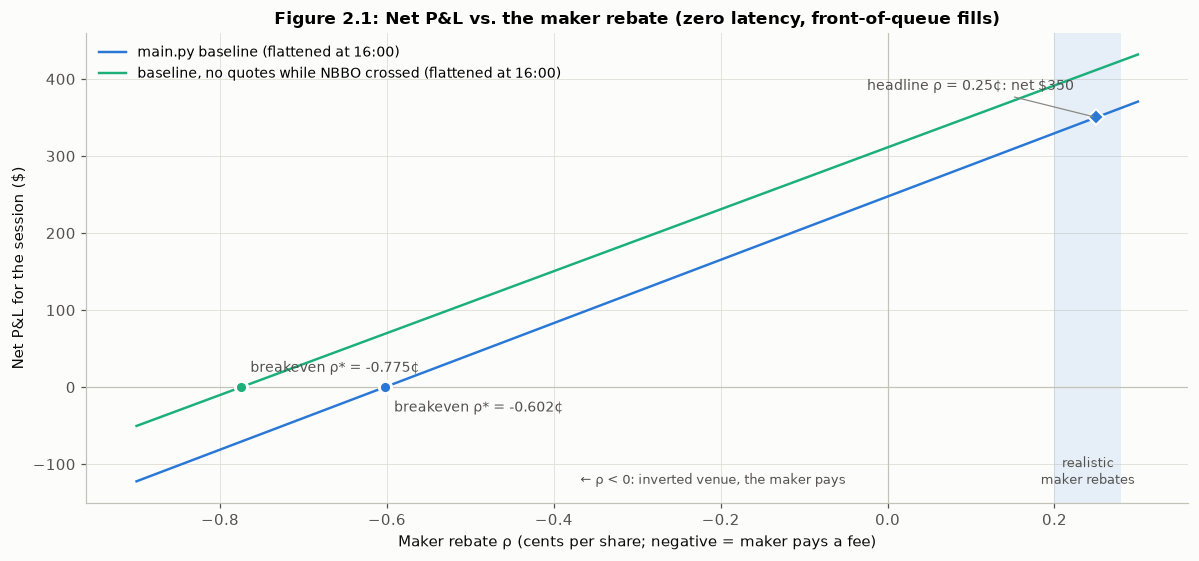

In [23]:
fig, ax = plt.subplots(figsize=(11, 5.2))
rho_c = 100 * RHO_GRID  # cents per share
ax.axvspan(100 * RHO_REALISTIC[0], 100 * RHO_REALISTIC[1], color=COLORS["real"], alpha=0.10, lw=0)
ax.axvline(0, color="#c3c2b7", lw=0.8)
ax.axhline(0, color="#c3c2b7", lw=0.8)
line_colors = {"main.py baseline": COLORS["real"], "baseline, no quotes while NBBO crossed": COLORS["accent"]}
for name, (gross, shares, flat) in variants_2.items():
    net = net_pnl(gross, shares, RHO_GRID, flat["total flattening cost ($)"])
    ax.plot(rho_c, net, color=line_colors[name], label=f"{name} (flattened at 16:00)")
    be = breakevens[name]["flattened at 16:00 with taker fee"]
    ax.plot(100 * be, 0, "o", ms=8, color=line_colors[name], mec="#fcfcfb", mew=2)
    ax.annotate(f"breakeven ρ* = {100 * be:+.3f}¢", xy=(100 * be, 0), xytext=(6, -16 if name == "main.py baseline" else 10),
                textcoords="offset points", fontsize=9, color=COLORS["ink"])
headline_net = net_pnl(gross_pnl, filled_shares, RHO_HEADLINE, flat["total flattening cost ($)"])
ax.plot(100 * RHO_HEADLINE, headline_net, "D", ms=7, color=COLORS["real"], mec="#fcfcfb", mew=1.5)
ax.annotate(f"headline ρ = {100 * RHO_HEADLINE:.2f}¢: net ${headline_net:,.0f}", xy=(100 * RHO_HEADLINE, headline_net),
            xytext=(-150, 18), textcoords="offset points", fontsize=9, color=COLORS["ink"],
            arrowprops={"arrowstyle": "-", "color": COLORS["muted"], "lw": 0.8})
ymin, ymax = ax.get_ylim()
ax.text(100 * np.mean(RHO_REALISTIC), ymin + 0.04 * (ymax - ymin), "realistic\nmaker rebates", ha="center",
        fontsize=8.5, color=COLORS["ink"])
ax.text(-0.05, ymin + 0.04 * (ymax - ymin), "← ρ < 0: inverted venue, the maker pays", fontsize=8.5,
        color=COLORS["ink"], ha="right")
ax.set_xlabel("Maker rebate ρ (cents per share; negative = maker pays a fee)")
ax.set_ylabel("Net P&L for the session ($)")
ax.set_title("Figure 2.1: Net P&L vs. the maker rebate (zero latency, front-of-queue fills)")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
plt.show()

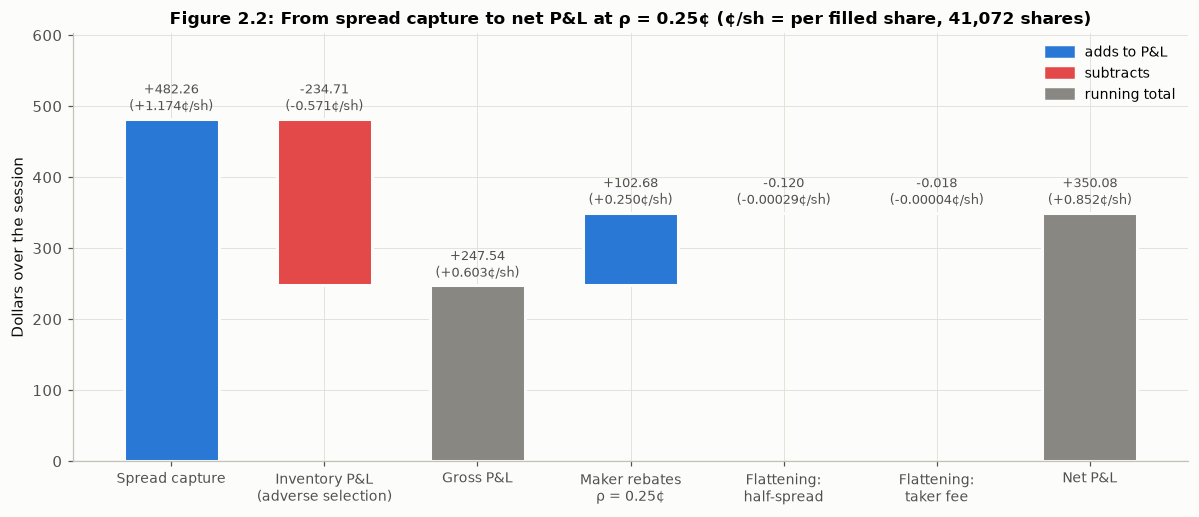

In [24]:
from matplotlib.patches import Patch

waterfall = [  # (label, change in $, or None for a running subtotal)
    ("Spread capture", real_capture),
    ("Inventory P&L\n(adverse selection)", gross_pnl - real_capture),
    ("Gross P&L", None),
    (f"Maker rebates\nρ = {100 * RHO_HEADLINE:.2f}¢", headline_rebates),
    ("Flattening:\nhalf-spread", -flat["spread cost vs mid ($)"]),
    ("Flattening:\ntaker fee", -flat["taker fee ($)"]),
    ("Net P&L", None),
]
bars, running = [], 0.0
for label, change in waterfall:
    if change is None:
        bars.append((label, 0.0, running, "total", running))
    else:
        bars.append((label, running + min(change, 0.0), abs(change), "gain" if change >= 0 else "cost", change))
        running += change
assert np.isclose(running, headline_net) and np.isclose(bars[2][4], gross_pnl)

colors = {"gain": COLORS["real"], "cost": "#e34948", "total": COLORS["muted"]}
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(bars))
ax.bar(x, [b[2] for b in bars], bottom=[b[1] for b in bars], width=0.62, color=[colors[b[3]] for b in bars],
       edgecolor="#fcfcfb", linewidth=2)
for xi, (label, bottom, height, kind, value) in zip(x, bars):
    small = abs(value) < 1  # the flattening terms: show enough digits to see them at all
    per_share = 100 * value / filled_shares
    ax.text(xi, bottom + height + 6, f"{value:+,.3f}\n({per_share:+.5f}¢/sh)" if small else
            f"{value:+,.2f}\n({per_share:+.3f}¢/sh)", ha="center", va="bottom", fontsize=8.5, color=COLORS["ink"])
ax.axhline(0, color="#c3c2b7", lw=0.8)
ax.set_xticks(x, [b[0] for b in bars], fontsize=9)
ax.set_ylim(0, max(b[1] + b[2] for b in bars) * 1.25)
ax.set_ylabel("Dollars over the session")
ax.set_title(f"Figure 2.2: From spread capture to net P&L at ρ = {100 * RHO_HEADLINE:.2f}¢ "
             f"(¢/sh = per filled share, {filled_shares:,} shares)")
ax.legend(handles=[Patch(color=colors["gain"], label="adds to P&L"), Patch(color=colors["cost"], label="subtracts"),
                   Patch(color=colors["total"], label="running total")], fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

**How much do fees and rebates matter?** For the baseline, they move net P&L by about a third, but the strategy would be profitable without them. Realistic rebates add \$82-115 to \$247.54 of gross P&L (Figure 2.1). Per filled share (Figure 2.2), the strategy gets 1.174 cents of captured spread + 0.250 cents of rebates - 0.0003 cents of flattening - 0.571 cents lost on inventory (a stand-in for adverse selection until Section 6) = **0.852 cents**, or \$350.08 for the day. Net P&L only reaches zero at **$\rho^*$ = -0.602 cents**, and the end-of-day taker trade costs **\$0.018, 0.02% of rebates**.

There are two caveats. Rebates scale with fills, so if fills are overcounted (14% were marketable when placed, and 53% came from off-exchange prints) the rebates are overstated too. And as later sections shrink the gross edge, the rebate becomes a bigger share of what is left.

**For the head trader:** on this tape, fees and rebates make up about 30% of the baseline's net P&L, but they don't decide whether it is profitable.

## Section 3 - Latency: How Much Does Speed Cost You?

Only latency changes in this section. The strategy, front-of-queue fills, full session and Section 2 fees (0.25-cent rebate, 16:00 flattening with taker fee) stay fixed.

### 3a - Latency model

`LatencyBroker` adds a fixed one-way latency $L$ to both legs, measured in tape time:
- **Outbound:** `send_limit_order` and `cancel_order` reach the exchange $L$ ms after they are sent. Until then the exchange keeps matching against the old orders.
- **Market data:** every message (quotes, prints and our own fills) reaches the strategy $L$ ms after it happens.

**The stale-order race.** If the market drops through our bid, we only see it $L$ ms later, and our cancel lands $L$ ms after that. For that $2L$ window the old bid is resting above the market, and any seller at or below it fills us. This comes out of the two delay queues without any extra code. To measure it, we count fills that happen while a cancel for that side is still in flight, and fills on quotes at or through the far side of the real NBBO. Orders expire at 16:00. At $L = 0$ the broker gives the same fills as `TapeBroker` (checked below).

In [25]:
from collections import deque
from datetime import timedelta


class LatencyBroker(TapeBroker):
    """TapeBroker with a fixed one-way latency on both legs, in tape time (see 3a)."""

    def __init__(self, data_path, latency_ms):
        super().__init__(data_path)
        self.latency = timedelta(milliseconds=latency_ms)
        self._outbound = deque()  # (time it reaches the exchange, FakeBroker method, args)
        self._inbound = deque()   # (time the strategy sees it, message)
        self._now = None          # tape time of the latest line read, i.e. the strategy's clock
        self._cancels_in_flight = {"buy": 0, "sell": 0}
        self.fills_with_cancel_in_flight = 0

    def send_limit_order(self, side, price, size):
        self._outbound.append((self._now + self.latency, FakeBroker.send_limit_order, (side, price, size)))

    def cancel_order(self, side):
        self._cancels_in_flight[side] += 1
        self._outbound.append((self._now + self.latency, FakeBroker.cancel_order, (side,)))

    def poll(self):
        event = self._read_event()
        if event is None:
            return []
        self._now = event.time
        while self._outbound and self._outbound[0][0] <= event.time:  # requests that have reached the exchange
            _, action, args = self._outbound.popleft()
            action(self, *args)
            if action is FakeBroker.cancel_order:
                self._cancels_in_flight[args[0]] -= 1
        if event.time >= SESSION_CLOSE:
            self._resting.clear()  # day orders expire at the close
        fills = self._exchange_step(event)
        self.fills_with_cancel_in_flight += sum(f.size > 0 and self._cancels_in_flight[f.side] > 0 for f in fills)
        for message in (event, *fills):
            self._inbound.append((event.time + self.latency, message))
        self._pending_broker_messages.clear()  # acks aren't modelled (main.py ignores them)
        released = []
        while self._inbound and self._inbound[0][0] <= event.time:
            released.append(self._inbound.popleft()[1])
        return released


# Check: with zero latency the broker has to match the plain TapeBroker fill for fill.
plain = run_session(max_messages=CHECK_WINDOW)
zero_latency = run_session(broker_cls=partial(LatencyBroker, latency_ms=0), max_messages=CHECK_WINDOW)
assert zero_latency.fills[fill_key].equals(plain.fills[fill_key])
assert zero_latency.book["cash"] == plain.book["cash"] and zero_latency.book["inventory"] == plain.book["inventory"]
print(f"L = 0: {len(plain.fills):,} fills, identical to TapeBroker")
del plain, zero_latency

L = 0: 4,292 fills, identical to TapeBroker


### 3b - Running the latency grid

$L \in \{0, 1, 5, 20, 100, 500\}$ ms, plus 200 ms to pin down the breakeven ($L$ = 0 reuses the Section 1 baseline). The metrics are net P&L (gross at the 16:00 mid + rebates - flattening), shares filled, and markout-free spread capture per share, which is (mid at fill - buy price) or (sell price - mid at fill) using the pre-trade mid.

In [26]:
LATENCIES_MS = [0, 1, 5, 20, 100, 200, 500]  # the prompt's grid plus 200 ms to pin down the breakeven
latency_runs = {0: baseline}
for latency_ms in LATENCIES_MS[1:]:
    latency_runs[latency_ms] = run_session(broker_cls=partial(LatencyBroker, latency_ms=latency_ms))
    assert latency_runs[latency_ms].messages_read == baseline.messages_read  # same tape and window


def latency_metrics(result):
    f = result.fills
    p = session_paths(f, quotes)
    shares = int(f["size"].sum())
    gross = p["pnl"].iloc[-1]
    flat_cost = flatten_at_close(p)["total flattening cost ($)"]
    capture = (f["signed"] * (f["mid"] - f["price"])).sum()
    through_touch = (((f["side"] == "buy") & (f["price"] >= f["ask"] - 1e-9))
                     | ((f["side"] == "sell") & (f["price"] <= f["bid"] + 1e-9)))
    return {
        "fills (shares)": shares,
        "gross P&L ($)": gross,
        "net P&L ($)": net_pnl(gross, shares, RHO_HEADLINE, flat_cost),
        "spread capture per share (c)": 100 * capture / shares,
        "inventory P&L ($)": gross - capture,
        "fills on quotes through the touch (%)": 100 * through_touch.mean(),
        "fills with a cancel already sent (%)": 100 * getattr(result.broker, "fills_with_cancel_in_flight", 0) / shares,
        "max drawdown ($)": (np.maximum.accumulate(p["pnl"]) - p["pnl"]).max(),
        "max |inventory| (shares)": p["inventory"].abs().max(),
    }


latency_table = pd.DataFrame({L: latency_metrics(r) for L, r in latency_runs.items()}).T
latency_table.index.name = "latency L (ms)"
display(latency_table.style.format("{:,.2f}").format("{:,.0f}", subset=["fills (shares)"]))

def breakeven(series):
    """Latency where the series first turns from positive to <= 0, interpolated linearly in log(L)."""
    for lo, hi in zip(LATENCIES_MS[:-1], LATENCIES_MS[1:]):
        if series[lo] > 0 >= series[hi]:
            share = series[lo] / (series[lo] - series[hi])  # fraction of the way from lo to hi
            return lo, hi, hi * share if lo == 0 else 10 ** (np.log10(lo) + share * (np.log10(hi) - np.log10(lo)))
    return None


crossings = {label: breakeven(latency_table[column])
             for label, column in (("net P&L", "net P&L ($)"), ("gross P&L", "gross P&L ($)"))}
show({f"{label} turns negative at (ms)": f"about {c[2]:.0f} (between {c[0]} and {c[1]})" if c else "never"
      for label, c in crossings.items()}, "breakeven latency")
net_crossing = crossings["net P&L"]
breakeven_ms = net_crossing[2] if net_crossing else None

,fills (shares),gross P&L ($),net P&L ($),spread capture per share (c),inventory P&L ($),fills on quotes through the touch (%),fills with a cancel already sent (%),max drawdown ($),max |inventory| (shares)
latency L (ms),,,,,,,,,
0,"41,072",247.54,350.08,1.17,-234.71,13.95,0.00,81.65,20.00
1,"36,020",90.54,180.41,0.84,-211.20,12.26,33.39,102.48,49.00
5,"35,928",111.18,200.82,0.94,-225.34,12.13,36.19,97.01,68.00
20,"37,733",137.14,231.31,0.90,-200.66,14.58,47.30,70.69,29.00
100,"46,278",-20.15,95.36,0.35,-184.30,29.63,85.75,149.75,27.00
200,"53,753",-330.29,-196.16,-0.29,-176.75,43.65,94.58,358.31,46.00
500,"67,937","-1,454.93","-1,285.20",-1.90,-162.27,65.64,99.46,"1,458.81",109.00


,breakeven latency
net P&L turns negative at (ms),about 125 (between 100 and 200)
gross P&L turns negative at (ms),about 81 (between 20 and 100)


### 3c - Plots

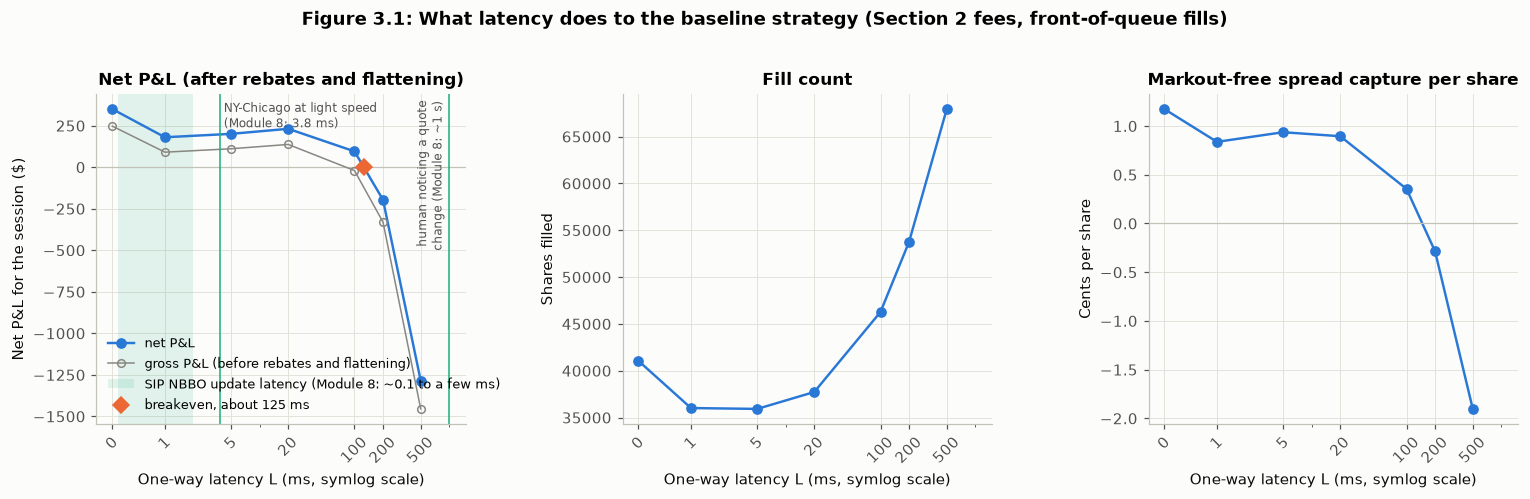

In [27]:
x = np.array(LATENCIES_MS, dtype=float)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
panels = [
    ("net P&L ($)", "Net P&L for the session ($)", "Net P&L (after rebates and flattening)"),
    ("fills (shares)", "Shares filled", "Fill count"),
    ("spread capture per share (c)", "Cents per share", "Markout-free spread capture per share"),
]
for ax, (column, ylabel, title) in zip(axes, panels):
    ax.plot(x, latency_table[column], marker="o", ms=6, color=COLORS["real"])
    if column != "fills (shares)":
        ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_xscale("symlog", linthresh=1, linscale=0.5)
    ax.set_xlim(-0.3, 1500)
    ax.set_xticks(x, [f"{int(v)}" for v in x], rotation=45)
    ax.set_xlabel("One-way latency L (ms, symlog scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].plot(x, latency_table["gross P&L ($)"], marker="o", ms=5, lw=1, color=COLORS["muted"], mfc="none",
             label="gross P&L (before rebates and flattening)")
axes[0].lines[0].set_label("net P&L")
axes[0].axvspan(0.1, 2, color=COLORS["accent"], alpha=0.12, lw=0, label="SIP NBBO update latency (Module 8: ~0.1 to a few ms)")
for ref_ms, label, rotation in ((3.8, "NY-Chicago at light speed\n(Module 8: 3.8 ms)", 0),
                                (1000, "human noticing a quote\nchange (Module 8: ~1 s)", 90)):
    axes[0].axvline(ref_ms, color=COLORS["accent"], lw=1)
    axes[0].text(ref_ms * (1.1 if rotation == 0 else 0.92), 0.98, label, transform=axes[0].get_xaxis_transform(),
                 fontsize=8, color=COLORS["ink"], va="top", ha="left" if rotation == 0 else "right", rotation=rotation)
if breakeven_ms is not None:
    axes[0].plot(breakeven_ms, 0, "D", ms=7, color=COLORS["sim"], label=f"breakeven, about {breakeven_ms:.0f} ms")
axes[0].legend(fontsize=8.5, loc="lower left")
fig.suptitle("Figure 3.1: What latency does to the baseline strategy (Section 2 fees, front-of-queue fills)",
             fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**What latency does** (Figure 3.1):
1. *The first millisecond costs the most.* Net P&L falls from \$350.08 at $L$ = 0 to \$180.41 at 1 ms. At $L = 0$ the strategy can re-quote in the middle of bursts of prints that are microseconds apart (2.9 prints within 1 ms, see 1b), which no real system could do. With latency it keeps re-sending quotes before it knows it has been filled, so a stale price can be hit more than once. Inventory also goes past the $\pm$20 limit (49 shares at 1 ms) because the limit check uses stale inventory. At 1 ms, 33.4% of fills happen while a cancel is in flight.
2. *1 to 20 ms is roughly flat.* Net P&L is \$180-231, capture is 0.84-0.94 cents per share, and about 36,000-38,000 shares fill.
3. *At 100 ms and above, stale quotes get picked off.* Fills on quotes at or through the far side go from 12-15% up to 29.6% at 100 ms and 65.6% at 500 ms. Capture falls to 0.35 cents at 100 ms and goes negative after that (-1.90 at 500 ms). Fills actually *rise* (67,937 shares at 500 ms) because a stale quote on the wrong side gets hit by almost any trade. Net P&L is \$95.36 at 100 ms, -\$196.16 at 200 ms and -\$1,285.20 at 500 ms.

### 3d - Where the strategy stops being profitable

Net P&L crosses zero between 100 and 200 ms, at about **125 ms** using log interpolation. Without rebates it crosses at about 80 ms. If the through-the-touch fills were charged as taker fills (an upper bound), that would take about \$75 off at 100 ms, so the breakeven is somewhere around 100-125 ms.

Compared with Module 8's latency table, a colocated direct feed (low single-digit microseconds), the SIP NBBO (hundreds of microseconds to low milliseconds) and even New York to Chicago at light speed (3.8 ms) are all far below 100 ms, so any automated setup would keep the strategy profitable. A human noticing a quote change (~1 second) would not, since the strategy already loses \$196 at 200 ms. So the breakeven is a lot closer to "a human noticing a quote change" (within a factor of 10) than to "colocated direct feed" (more than 10,000 times slower). The strategy needs to be automated but doesn't need to be the fastest. Also, going from 0 to 1 ms alone costs \$170, so the frictionless \$350 is more than any real system could earn.

## Section 4 - Queue Priority: How Important Is It Really?

Held fixed: `main.handle_next_tick`, the full session, Section 2 fees and **5 ms** latency (in the middle of Section 3's flat 1-20 ms range, and about what an automated system on the SIP would get). Only the fill model changes.

### 4a - A pessimistic, queue-aware fill model

Level 1 data only shows the best bid and ask and the size displayed there. It doesn't show order counts, arrival order or deeper levels. **True queue position can't be reconstructed from this tape**, so we bracket the answer with an optimistic and a pessimistic model.

**Size units.** Every `bid_size`/`ask_size` is a multiple of 4,000. When lit prints hit an unchanged bid, the displayed size falls by a median of 87x the shares printed, and a bid that gets cleared by lit prints had shown a median of 98x the shares printed. So we read the sizes as shares $\times$ 100 (the smallest display is then 40 shares, one round lot at this price, and the median is 160).

In [28]:
# What unit are bid_size / ask_size in? Compare each drop in the displayed bid (price unchanged) with the
# lit volume printed at that bid between the two quote updates.
quote_before = np.searchsorted(quotes["line"].to_numpy(), trades["line"].to_numpy()) - 1
lit_print = (~trades["exchange"].eq("DARK").to_numpy()) & (trades["size"].to_numpy() > 0) & (quote_before >= 0)
at_bid = lit_print & np.isclose(trades["price"].to_numpy(), trades["bid_before"].to_numpy())
printed_at_bid = np.bincount(quote_before[at_bid], weights=trades["size"].to_numpy()[at_bid], minlength=len(quotes))

bid, bid_size = quotes["bid"].to_numpy(), quotes["bid_size"].to_numpy()
drop = bid_size[:-1] - bid_size[1:]
pairs = (bid[1:] == bid[:-1]) & (drop > 0) & (printed_at_bid[:-1] > 0)
ratio = drop[pairs] / printed_at_bid[:-1][pairs]
# Second check: when lit prints clear the bid (the next quote shows a lower bid), compare the size that was displayed
# there with the shares that printed at it.
cleared = (bid[1:] < bid[:-1] - TOL) & (printed_at_bid[:-1] > 0)
clear_ratio = bid_size[:-1][cleared] / printed_at_bid[:-1][cleared]
lit_sizes = rth_trades.loc[(rth_trades["exchange"] != "DARK") & (rth_trades["size"] > 0), "size"]
shown = rth_quotes["bid_size"] / 100
show({
    "displayed sizes that are multiples of 4,000": f"{np.mean(quotes[['bid_size', 'ask_size']].to_numpy() % 4000 == 0):.2%}",
    "bid-size drops with lit prints at that bid in between": f"{pairs.sum():,}",
    "  drop / shares printed, 25th pct / median / 75th pct": f"{np.percentile(ratio, 25):.1f} / {np.median(ratio):.1f} / "
                                                            f"{np.percentile(ratio, 75):.1f}",
    "bids cleared by lit prints": f"{cleared.sum():,}",
    "  displayed size / shares printed, 25th pct / median / 75th pct": f"{np.percentile(clear_ratio, 25):.0f} / "
                                                                      f"{np.median(clear_ratio):.1f} / {np.percentile(clear_ratio, 75):.0f}",
    "median lit print (shares)": f"{lit_sizes.median():.0f}",
    "bid size / 100, 10th pct / median / 90th pct": f"{shown.quantile(0.1):.0f} / {shown.median():.0f} / {shown.quantile(0.9):.0f}",
}, "size units")

,size units
"displayed sizes that are multiples of 4,000",100.00%
bid-size drops with lit prints at that bid in between,"4,209"
"drop / shares printed, 25th pct / median / 75th pct",29.8 / 87.0 / 300.0
bids cleared by lit prints,"1,334"
"displayed size / shares printed, 25th pct / median / 75th pct",50 / 97.6 / 219
median lit print (shares),40
"bid size / 100, 10th pct / median / 90th pct",40 / 160 / 520


**The pessimistic model.** `QueueBroker` extends `LatencyBroker` with three switches, all turned on in the pessimistic model:
1. **Lit prints only.** Off-exchange (`DARK`) prints and average-price, derivatively priced or contingent prints can't fill an order resting on an exchange. These set off 53% and 28% of baseline fills.
2. **Marketable orders take.** A quote that is at or through the far side when it arrives trades right away at the far-side price. It pays the taker fee and earns no rebate.
3. **Back of the queue.**
   - At the touch, the whole displayed size is ahead of us. Behind the touch the queue isn't displayed, so once that level becomes the touch, its whole displayed size is ahead of us.
   - Each lit print at our price uses up some of the shares ahead of us. We fill once a print is bigger than what is left.
   - If the displayed size drops below our estimate, we lower the estimate to match (cancellations ahead of us). Size increases are added behind us.
   - A lit print *through* our price fills us right away (under Reg NMS our level must already be gone).

**Assumptions that could be wrong.** The NBBO size is treated as one queue, but it really belongs to one or a few venues. Cancellations are assumed to come from behind us. Hidden or reserve orders ahead of us can't be seen. Our own order isn't counted in the displayed size.

**Order handling (every fill model).** `main.py` cancels and re-sends both quotes on every message, which we treat as a single cancel/replace. A replace at the same price keeps its place in the queue, and a replace that arrives after the order has already filled is rejected. This fixes the repeated stale fills from Section 3. With all switches off and $L = 0$, `QueueBroker` gives the same fills as `TapeBroker` (checked below).

In [29]:
DISPLAY_SIZE_SCALE = 100  # the tape's bid_size / ask_size are shares x 100 (checked above)
TICK = 0.01


class QueueBroker(LatencyBroker):
    """LatencyBroker with cancel/replace handling and a choice of fill model (see 4a).

    Order handling, for every fill model: main.py's cancel-then-resend on a side is read as one cancel/replace.
      - A replace at an unchanged price leaves the order, and its place in the queue, alone.
      - An order sent before the strategy could have seen the latest fill on that side (less than L after
        it) replaces an order that no longer exists, so the exchange rejects it.
    Fill model switches (all off = FakeBroker's matching):
      lit_only        only lit-exchange prints without average-price / contingent conditions can fill us.
      taker           an order that is marketable when it reaches the exchange trades at once against the far
                      side of the NBBO as a taker. These fills are logged with exchange "TAKER".
      queue           a new order joins the back of the displayed queue at its price and fills only after lit
                      prints at that price have worked through the shares ahead of it.
      ahead_fraction  share of the displayed queue assumed to be ahead of us when we join it (1 = all of it).
    """

    def __init__(self, data_path, latency_ms, lit_only=True, taker=True, queue=True, ahead_fraction=1.0):
        super().__init__(data_path, latency_ms)
        self.lit_only, self.taker, self.queue, self.ahead_fraction = lit_only, taker, queue, ahead_fraction
        self.bid_size = self.ask_size = None      # displayed NBBO shares, in exchange time
        self._ahead = {}                          # side -> shares ahead of our resting order (None = not known yet)
        self._last_fill_time = {}                 # side -> exchange time of our latest fill
        self._replaced = {}                       # side -> (price, ahead) of an order cancelled in this batch
        self._taker_fills = []
        self.replaces_kept = self.replaces_rejected = 0
        self.touch_exposure = defaultdict(float)  # (side, cents behind the touch) -> seconds resting there

    # --- requests from the strategy ----------------------------------------------------------------
    def send_limit_order(self, side, price, size):
        self._outbound.append((self._now + self.latency, QueueBroker._arrive_order, (side, price, size, self._now)))

    def cancel_order(self, side):
        self._cancels_in_flight[side] += 1
        self._outbound.append((self._now + self.latency, QueueBroker._arrive_cancel, (side,)))

    # --- the exchange --------------------------------------------------------------------------------
    def _arrive_cancel(self, side):
        self._cancels_in_flight[side] -= 1
        resting = self._resting.pop(side, None)
        if resting is not None:
            self._replaced[side] = (resting[1], self._ahead.pop(side, None))

    def _arrive_order(self, side, price, size, sent_at):
        last_fill = self._last_fill_time.get(side)
        if last_fill is not None and last_fill > sent_at - self.latency:
            self.replaces_rejected += 1   # too late to replace: the order it replaces has already filled
            return
        order_id = self._next_order_id
        self._next_order_id += 1
        if self.taker and self._spread_ticks() > 0 and self._behind_touch(side, price) <= -self._spread_ticks():
            far = self.ask if side == "buy" else self.bid
            self._taker_fills.append(OrderFilled(order_id, side, far, size))
            self._last_fill_time[side] = self._now
            self.fill_log.append((self._now, side, far, size, self.mid, self._distance(side, far),
                                  self.bid, self.ask, far, size, "TAKER", ()))
            return
        self._resting[side] = (order_id, price, size)
        previous = self._replaced.pop(side, None)
        if previous is not None and abs(previous[0] - price) < TOL:
            self._ahead[side] = previous[1]   # same price: keep our place in the queue
            self.replaces_kept += 1
        else:
            self._ahead[side] = self._shares_ahead_on_arrival(side, price)

    def _spread_ticks(self):
        return int(round((self.ask - self.bid) / TICK)) if self.bid is not None else 0

    def _touch(self, side):
        return (self.bid, self.bid_size) if side == "buy" else (self.ask, self.ask_size)

    def _behind_touch(self, side, price):
        """Cents behind the NBBO on our own side: 0 at the touch, 1 one cent behind, negative = improving it."""
        touch, _ = self._touch(side)
        return int(round(((touch - price) if side == "buy" else (price - touch)) / TICK))

    def _shares_ahead_on_arrival(self, side, price):
        if self.bid is None or self._behind_touch(side, price) < 0:
            return 0.0                                          # we set a new best price: nobody is ahead
        if self._behind_touch(side, price) == 0:
            return self.ahead_fraction * self._touch(side)[1]   # join the displayed queue at the touch
        return None                                             # level behind the touch isn't displayed

    def _update_on_quote(self):
        for side, ahead in self._ahead.items():
            behind = self._behind_touch(side, self._resting[side][1])
            if behind < 0:
                self._ahead[side] = 0.0   # the NBBO moved behind our price: everyone ahead of us is gone
            elif behind == 0:
                shown = self._touch(side)[1]
                self._ahead[side] = self.ahead_fraction * shown if ahead is None else min(ahead, shown)

    def _exchange_step(self, event):
        self._replaced.clear()            # a cancel and its resend arrive together, in one batch
        fills = self._taker_fills + super()._exchange_step(event)
        self._taker_fills = []
        for fill in fills:
            self._last_fill_time[fill.side] = event.time
        for side in set(self._ahead) - set(self._resting):  # filled, or expired at the close
            del self._ahead[side]
        if isinstance(event, QuoteUpdate):
            self.bid_size = event.bid_size / DISPLAY_SIZE_SCALE
            self.ask_size = event.ask_size / DISPLAY_SIZE_SCALE
            self._update_on_quote()
        return fills

    def _check_fill(self, trade):
        if not (self.lit_only or self.queue):
            return super()._check_fill(trade)
        if trade.size == 0 or (self.lit_only and (trade.exchange == "DARK"
                                                  or NON_BOOK_CONDITIONS.intersection(trade.conditions))):
            return []
        fills = []
        for side, sign in (("buy", 1.0), ("sell", -1.0)):
            resting = self._resting.get(side)
            if resting is None:
                continue
            order_id, price, size = resting
            through = sign * (price - trade.price)  # > 0: the print traded through our price
            if through < -TOL:
                continue
            if through > TOL or not self.queue:
                filled = min(size, trade.size)
            elif self._ahead[side] is None:
                filled = 0
            else:
                filled = int(min(size, max(trade.size - self._ahead[side], 0)))
                self._ahead[side] = max(self._ahead[side] - trade.size, 0.0)
            if filled > 0:
                fills.append(OrderFilled(order_id, side, price, filled))
                del self._resting[side]
        return fills

    def _accumulate_exposure(self, now):
        super()._accumulate_exposure(now)
        if self._last_time is None or self.mid is None:
            return
        elapsed = (now - self._last_time).total_seconds()
        for side, (_, price, _) in self._resting.items():
            self.touch_exposure[(side, self._behind_touch(side, price))] += elapsed


# Check: at L = 0 with every switch off, QueueBroker has to match the plain TapeBroker fill for fill.
plain = run_session(max_messages=CHECK_WINDOW)
same = run_session(broker_cls=partial(QueueBroker, latency_ms=0, lit_only=False, taker=False, queue=False),
                   max_messages=CHECK_WINDOW)
assert same.fills[fill_key].equals(plain.fills[fill_key])
assert same.broker.replaces_rejected == 0
print(f"L = 0, all switches off: {len(same.fills):,} fills, identical to TapeBroker")
del plain, same

L = 0, all switches off: 4,292 fills, identical to TapeBroker


### 4b - Head to head: same strategy, fees and latency

The switches are turned on one at a time, plus one case where only half the displayed queue is ahead of us. Section 3's 5 ms run (without cancel/replace handling) is included for reference.

In [30]:
QUEUE_LATENCY_MS = 5
FILL_MODELS = {
    "optimistic": dict(lit_only=False, taker=False, queue=False),
    "+ lit prints only": dict(lit_only=True, taker=False, queue=False),
    "+ marketable orders take": dict(lit_only=True, taker=True, queue=False),
    "pessimistic (+ back of queue)": dict(lit_only=True, taker=True, queue=True),
    "half the queue ahead": dict(lit_only=True, taker=True, queue=True, ahead_fraction=0.5),
}
OPTIMISTIC, PESSIMISTIC = "optimistic", "pessimistic (+ back of queue)"


def pnl_breakdown(result, rho=RHO_HEADLINE, taker_fee=TAKER_FEE):
    """The P&L lines used from Section 4 on. Signs as in Setup: rebates add, fees and costs subtract.

    Passive fills earn rho; TAKER fills and the 16:00 flattening trade pay the taker fee.
    """
    f = result.fills
    p = session_paths(f, quotes)
    taker = f["exchange"].eq("TAKER")
    flat = flatten_at_close(p, taker_fee)
    gross = p["pnl"].iloc[-1]
    capture = (f["signed"] * (f["mid"] - f["price"])).sum()
    rebates = rho * f.loc[~taker, "size"].sum()
    fees = taker_fee * f.loc[taker, "size"].sum() + flat["taker fee ($)"]
    return {
        "fills (shares)": int(f["size"].sum()),
        "buy / sell (shares)": f"{int(f.loc[f['side'] == 'buy', 'size'].sum()):,} / "
                               f"{int(f.loc[f['side'] == 'sell', 'size'].sum()):,}",
        "taker fills (%)": 100 * taker.mean(),
        "spread capture ($)": capture,
        "spread capture per share (c)": 100 * capture / f["size"].sum(),
        "inventory P&L ($)": gross - capture,
        "gross P&L ($)": gross,
        "rebates ($)": rebates,
        "fees ($)": fees,
        "flattening half-spread ($)": flat["spread cost vs mid ($)"],
        "net P&L ($)": gross + rebates - fees - flat["spread cost vs mid ($)"],
        "mean |inventory| (shares)": p["inventory"].abs().mean(),
        "max |inventory| (shares)": p["inventory"].abs().max(),
        "16:00 inventory (shares)": p["inventory"].iloc[-1],
        "P&L volatility, 1-min changes ($)": np.std(np.diff(p["pnl"].to_numpy()[::60]), ddof=1),
        "max drawdown ($)": (np.maximum.accumulate(p["pnl"]) - p["pnl"]).max(),
    }


def dollars(x, digits=2):
    return f"{'-' if x < 0 else ''}${abs(x):,.{digits}f}"


def show_breakdown(table):
    return table.style.format(lambda v: f"{v:,.2f}" if isinstance(v, float) else (f"{v:,}" if isinstance(v, int) else v))


queue_runs = {}
for name, switches in FILL_MODELS.items():
    queue_runs[name] = run_session(broker_cls=partial(QueueBroker, latency_ms=QUEUE_LATENCY_MS, **switches))
    assert queue_runs[name].messages_read == baseline.messages_read  # same tape, same window

queue_table = pd.DataFrame({"Section 3 broker (no cancel/replace)": pnl_breakdown(latency_runs[QUEUE_LATENCY_MS])}
                           | {name: pnl_breakdown(r) for name, r in queue_runs.items()})
display(show_breakdown(queue_table))

# Net P&L as each switch is added; "half the queue ahead" is compared with the pessimistic row above it.
steps = queue_table.loc["net P&L ($)"].astype(float).rename("net P&L ($)").to_frame()
steps["change from the row above ($)"] = steps["net P&L ($)"].diff()
display(steps.style.format("{:+,.2f}", na_rep=""))

pess = queue_runs[PESSIMISTIC].fills
maker = pess[~pess["exchange"].eq("TAKER")]
traded_through = np.where(maker["side"] == "buy", maker["print_price"] < maker["price"] - TOL,
                          maker["print_price"] > maker["price"] + TOL)
show({
    "fills": f"{len(pess):,}",
    "passive fills": f"{len(maker):,}",
    "  from a print through our price": f"{traded_through.mean():.1%}",
    "  from working through the queue at our price": f"{1 - traded_through.mean():.1%}",
}, "pessimistic model")

,Section 3 broker (no cancel/replace),optimistic,+ lit prints only,+ marketable orders take,pessimistic (+ back of queue),half the queue ahead
fills (shares),"35,928","31,879","11,473","12,588","8,192","8,558"
buy / sell (shares),"17,968 / 17,960","15,942 / 15,937","5,739 / 5,734","6,296 / 6,292","4,098 / 4,094","4,281 / 4,277"
taker fills (%),0.00,0.00,0.00,15.78,24.56,22.88
spread capture ($),336.51,370.69,98.40,105.38,44.86,49.02
spread capture per share (c),0.94,1.16,0.86,0.84,0.55,0.57
inventory P&L ($),-225.34,-164.00,-148.53,-118.53,-76.26,-79.00
gross P&L ($),111.18,206.70,-50.13,-13.15,-31.40,-29.97
rebates ($),89.82,79.70,28.68,26.50,15.45,16.50
fees ($),0.02,0.01,0.01,5.97,6.05,5.89
flattening half-spread ($),0.16,0.10,0.10,0.08,0.08,0.08


,net P&L ($),change from the row above ($)
Section 3 broker (no cancel/replace),+200.82,
optimistic,+286.28,+85.47
+ lit prints only,-21.56,-307.84
+ marketable orders take,+7.30,+28.86
pessimistic (+ back of queue),-22.08,-29.38
half the queue ahead,-19.44,+2.64


,pessimistic model
fills,"8,192"
passive fills,"6,180"
from a print through our price,36.6%
from working through the queue at our price,63.4%


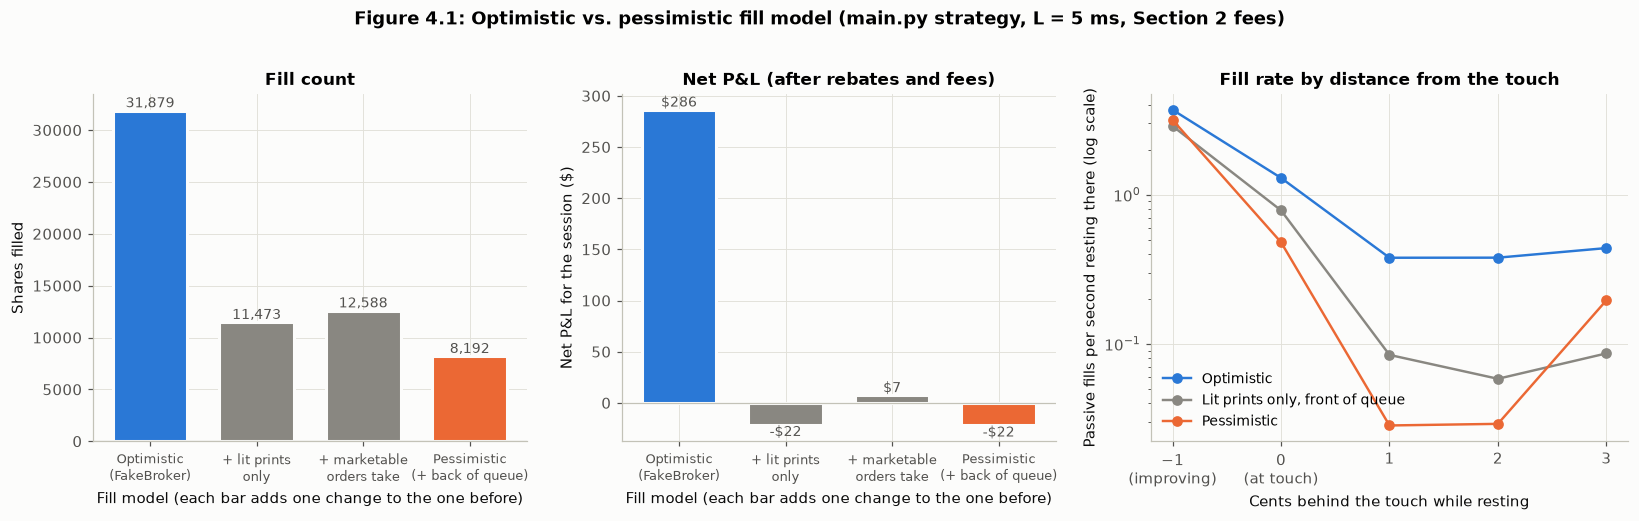

In [31]:
def fill_rate_by_touch_distance(result, cents=(-1, 0, 1, 2, 3)):
    """Passive fills per second of resting time, by how many cents behind the touch the order sat."""
    f = result.fills[~result.fills["exchange"].eq("TAKER")]
    behind = np.rint(100 * np.where(f["side"] == "buy", f["bid"] - f["price"], f["price"] - f["ask"])).astype(int)
    seconds = pd.Series(result.broker.touch_exposure).groupby(level=1).sum()
    n_fills = pd.Series(behind).value_counts()
    return pd.DataFrame({"resting share": (seconds / seconds.sum()).reindex(cents, fill_value=0),
                         "fills per resting second": (n_fills.reindex(seconds.index, fill_value=0) / seconds).reindex(cents)})


touch_rates = {name: fill_rate_by_touch_distance(queue_runs[name])
               for name in (OPTIMISTIC, "+ lit prints only", PESSIMISTIC)}
display(pd.concat(touch_rates, axis=1).style.format("{:.3f}"))

shown_models = list(FILL_MODELS)[:4]
model_labels = ["Optimistic\n(FakeBroker)", "+ lit prints\nonly", "+ marketable\norders take", "Pessimistic\n(+ back of queue)"]
model_colors = [COLORS["real"], COLORS["muted"], COLORS["muted"], COLORS["sim"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, row, ylabel, title in ((axes[0], "fills (shares)", "Shares filled", "Fill count"),
                               (axes[1], "net P&L ($)", "Net P&L for the session ($)", "Net P&L (after rebates and fees)")):
    values = queue_table.loc[row, shown_models].astype(float)
    ax.bar(range(4), values, color=model_colors, edgecolor="#fcfcfb", linewidth=2, width=0.7)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:,.0f}" if row.startswith("fills") else dollars(v, 0), ha="center",
                va="bottom" if v >= 0 else "top", fontsize=9, color=COLORS["ink"])
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_xticks(range(4), model_labels, fontsize=8.5)
    ax.set_xlabel("Fill model (each bar adds one change to the one before)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
ax = axes[2]
for name, color, label in ((OPTIMISTIC, COLORS["real"], "Optimistic"), ("+ lit prints only", COLORS["muted"], "Lit prints only, front of queue"),
                           (PESSIMISTIC, COLORS["sim"], "Pessimistic")):
    rate = touch_rates[name]
    ax.plot(rate.index, rate["fills per resting second"], marker="o", ms=6, color=color, label=label)
ax.set_yscale("log")
ax.set_xticks([-1, 0, 1, 2, 3], ["−1\n(improving)", "0\n(at touch)", "1", "2", "3"])
ax.set_xlabel("Cents behind the touch while resting")
ax.set_ylabel("Passive fills per second resting there (log scale)")
ax.set_title("Fill rate by distance from the touch")
ax.legend(fontsize=9, loc="lower left")
fig.suptitle(f"Figure 4.1: Optimistic vs. pessimistic fill model (main.py strategy, L = {QUEUE_LATENCY_MS} ms, Section 2 fees)",
             fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**Results** (Figure 4.1):
- *Fill count:* 31,879 shares in the optimistic model vs 8,192 in the pessimistic one. Most of the drop comes from excluding off-exchange and non-book prints (down to 11,473).
- *Net P&L:* **\$286.28 optimistic vs -\$22.08 pessimistic.** Going step by step: lit prints only is -\$307.84, marketable orders taking is +\$28.86 (quotes that cross get the far-side price right away), and back of the queue is -\$29.38. The cancel/replace handling by itself had already raised the optimistic run from \$200.82 to \$286.28.
- *Fill rate by distance from the touch:* one cent behind the touch, where the pessimistic run rests 71% of the time, an order fills 0.378 times per resting second in the optimistic model and 0.028 in the pessimistic one, 13x less. At the touch it is 1.29 vs 0.48.

### 4c - Where does the truth sit?

**At 5 ms, all of the baseline's profit came from the optimistic fill model** (\$286.28 vs -\$22.08, a \$308 gap). Most of that is from letting off-exchange prints fill a lit order (-\$307.84). Queue position by itself is only worth about \$29. This is because `main.py` mostly rests a cent behind the touch, and 37% of the pessimistic model's passive fills come from prints trading through our price, where queue place doesn't matter. Assuming only half the queue is ahead of us only gets back \$2.64.

Excluding off-exchange prints is more of a correction than an assumption, so the realistic range is from front-of-queue with lit prints and taker execution (+\$7.30) down to the pessimistic model (-\$22.08). We think the truth is near the pessimistic end, around -\$15 to -\$20 for the day. The pessimistic model is harsh in assuming cancellations come from behind us, but that is only worth a few dollars, and it is too generous in ignoring hidden orders and venue fragmentation. Either way, `main.py`'s quoting doesn't have an edge at 5 ms. We use the pessimistic model from here on.

## Section 5 - Alternative Quoting Strategies: Tilting Away from the Midpoint

**Setup used for Sections 5-7:** 5 ms latency, pessimistic fills, and Section 2 fees (0.25-cent rebate on passive fills, 0.30-cent taker fee on taker fills and flattening). Every variant also pulls its quotes while its view of the NBBO is crossed (the 1c guard, which is worth \$3.43 to `main.py` here). Every run covers the full session.

### 5a - The alternative: a depth-imbalance lean

Using the latest NBBO the strategy has seen,

$$I = \frac{\text{bid size} - \text{ask size}}{\text{bid size} + \text{ask size}}.$$

If $I > 0.5$ (bid at least 3x the ask), both quotes move **up one cent**. If $I < -0.5$, they move down one cent. Otherwise nothing changes. The lean is added on top of `main.py`'s inventory skew:

$$\text{bid} = \text{best bid} - \text{offset} - 0.01\,q + \text{lean}, \qquad \text{ask} = \text{best ask} + \text{offset} - 0.01\,q + \text{lean}.$$

**Construction:** there is no lookback window. Only the latest quote the strategy has seen (5 ms old) is used, so there is no look-ahead. The threshold (0.5) and lean (1 cent) are round numbers we picked without fitting, and 5b checks thresholds of 1/3 and 2/3.

**Why this signal:** we keep getting filled because the price is moving through our quote, and book imbalance is one of the few Level 1 signals about the next move. In-sample (table below), when $I > 0.5$ the mid rises 0.50 cents over the next second on average, and when $I < -0.5$ it falls 0.44 cents. A typical half-spread is about 0.9 cents. The book is this lopsided 38% of the session.

In [32]:
# Does the displayed depth imbalance say anything about the next mid move? (Descriptive, whole session.)
imbalance = ((rth_quotes["bid_size"] - rth_quotes["ask_size"]) / (rth_quotes["bid_size"] + rth_quotes["ask_size"])).to_numpy()
buckets = np.select([imbalance < -0.5, imbalance < -0.2, imbalance <= 0.2, imbalance <= 0.5],
                    ["I < -0.5 (ask at least 3x bid)", "-0.5 to -0.2", "-0.2 to 0.2", "0.2 to 0.5"],
                    "I > 0.5 (bid at least 3x ask)")
evidence = pd.DataFrame({"share of session": pd.Series(standing_s, index=rth_quotes.index).groupby(buckets).sum() / standing_s.sum()})
for h in (0.1, 1, 5):
    later = prevailing(quotes["time"], quotes["mid"], rth_quotes["time"] + pd.Timedelta(seconds=h))
    evidence[f"mean mid move next {h:g} s (c)"] = pd.Series(100 * (later - rth_quotes["mid"].to_numpy())).groupby(buckets).mean()
order = ["I < -0.5 (ask at least 3x bid)", "-0.5 to -0.2", "-0.2 to 0.2", "0.2 to 0.5", "I > 0.5 (bid at least 3x ask)"]
evidence = evidence.loc[order]
evidence.index.name = "displayed imbalance I"
display(evidence.style.format({"share of session": "{:.1%}"} | {c: "{:+.3f}" for c in evidence.columns[1:]}))

,share of session,mean mid move next 0.1 s (c),mean mid move next 1 s (c),mean mid move next 5 s (c)
displayed imbalance I,,,,
I < -0.5 (ask at least 3x bid),21.0%,-0.340,-0.441,-0.616
-0.5 to -0.2,18.4%,-0.107,-0.129,-0.184
-0.2 to 0.2,26.1%,+0.020,+0.044,+0.011
0.2 to 0.5,17.2%,+0.144,+0.234,+0.194
I > 0.5 (bid at least 3x ask),17.4%,+0.341,+0.503,+0.477


In [33]:
def make_quoter(offset=main.QUOTE_OFFSET, inventory_skew=main.INVENTORY_SKEW, depth_lean=0.0, depth_threshold=0.5,
                skip_crossed=True, toxicity=None):
    """main.handle_next_tick with the quoting rule opened up. Message handling and P&L logging are main.py's.

    offset          cents behind the touch, in dollars; or a function of the time (Section 7's rolling offset)
    inventory_skew  dollars per share of inventory (main.py: 0.01; 0 = symmetric quotes)
    depth_lean      dollars to lean both quotes toward the heavy side of the NBBO when |imbalance| > depth_threshold
    skip_crossed    pull both quotes while the NBBO the strategy has seen is crossed (the 1c guard)
    toxicity        optional object with on_fill(message, book) and paused(book) (Section 8)
    With the defaults and skip_crossed=False this is main.handle_next_tick exactly (checked below).
    """

    def handler(broker, book):
        for message in broker.poll():
            if isinstance(message, QuoteUpdate):
                book["time"] = message.time
                book["best_bid"], book["best_ask"] = message.bid, message.ask
                book["bid_size"], book["ask_size"] = message.bid_size, message.ask_size
            elif isinstance(message, TradePrint):
                book["time"] = message.time
                book["last_trade_price"] = message.price
            elif isinstance(message, OrderFilled):
                if message.side == "buy":
                    book["inventory"] += message.size
                    book["cash"] -= message.price * message.size
                else:
                    book["inventory"] -= message.size
                    book["cash"] += message.price * message.size
                if toxicity is not None:
                    toxicity.on_fill(message, book)

        if book["best_bid"] is None:
            return

        mark = book["last_trade_price"]
        if mark is None:
            mark = 0.5 * (book["best_bid"] + book["best_ask"])
        book["pnl_history"].append((book["time"], book["cash"] + book["inventory"] * mark))

        trading_hours = main.MARKET_OPEN <= book["time"].time() < main.MARKET_CLOSE
        crossed = book["best_ask"] < book["best_bid"]
        paused = toxicity is not None and toxicity.paused(book)
        if not trading_hours or (skip_crossed and crossed) or paused:
            broker.cancel_order("buy")
            broker.cancel_order("sell")
            return

        skew = book["inventory"] * inventory_skew
        if depth_lean:
            depth = book["bid_size"] + book["ask_size"]
            imbalance = (book["bid_size"] - book["ask_size"]) / depth if depth > 0 else 0.0
            if abs(imbalance) > depth_threshold:
                skew -= depth_lean * np.sign(imbalance)  # heavy bid: lean both quotes up
        half_offset = offset(book["time"]) if callable(offset) else offset
        desired_bid = round(book["best_bid"] - half_offset - skew, 2)
        desired_ask = round(book["best_ask"] + half_offset - skew, 2)

        broker.cancel_order("buy")
        broker.cancel_order("sell")
        if book["inventory"] < main.MAX_INVENTORY:
            broker.send_limit_order("buy", desired_bid, main.ORDER_SIZE)
        if book["inventory"] > -main.MAX_INVENTORY:
            broker.send_limit_order("sell", desired_ask, main.ORDER_SIZE)

    return handler


# Checks on the first 300k messages: make_quoter reproduces main.py, and main.py + the 1c crossed-NBBO guard.
for reference, variant in ((main.handle_next_tick, make_quoter(skip_crossed=False)),
                           (skip_when_crossed(main.handle_next_tick), make_quoter())):
    a = run_session(tick_handler=reference, max_messages=CHECK_WINDOW)
    b = run_session(tick_handler=variant, max_messages=CHECK_WINDOW)
    assert b.fills[fill_key].equals(a.fills[fill_key])
print("make_quoter matches main.handle_next_tick, with and without the crossed-NBBO guard")
del a, b

make_quoter matches main.handle_next_tick, with and without the crossed-NBBO guard


### 5b - Three-way comparison on the same window

Symmetric (no skew), `main.py`'s linear inventory skew, and inventory skew + depth lean, all with the 1-cent offset and $\pm$20 limit. As sensitivity checks we also run the lean without inventory skew, and thresholds of 1/3 and 2/3.

In [34]:
SETTLED_BROKER = partial(QueueBroker, latency_ms=QUEUE_LATENCY_MS)  # pessimistic fill model, 5 ms
DEPTH_LEAN = 0.01
STRATEGIES = {
    "symmetric (no skew)": dict(inventory_skew=0.0),
    "linear inventory skew (main.py)": dict(),
    "inventory skew + depth lean": dict(depth_lean=DEPTH_LEAN),
}
SENSITIVITY = {
    "depth lean, no inventory skew": dict(inventory_skew=0.0, depth_lean=DEPTH_LEAN),
    "inventory skew + depth lean, threshold 1/3": dict(depth_lean=DEPTH_LEAN, depth_threshold=1 / 3),
    "inventory skew + depth lean, threshold 2/3": dict(depth_lean=DEPTH_LEAN, depth_threshold=2 / 3),
}
SYMMETRIC, LINEAR, ALTERNATIVE = STRATEGIES

strategy_runs = {}
for name, knobs in (STRATEGIES | SENSITIVITY).items():
    strategy_runs[name] = run_session(tick_handler=make_quoter(**knobs), broker_cls=SETTLED_BROKER)
    assert strategy_runs[name].messages_read == baseline.messages_read  # same tape, same window
strategy_paths = {name: session_paths(r.fills, quotes) for name, r in strategy_runs.items()}

strategy_table = pd.DataFrame({name: pnl_breakdown(r) for name, r in strategy_runs.items()})
strategy_table.loc["time at |inventory| >= 5 (%)"] = [100 * (strategy_paths[n]["inventory"].abs() >= 5).mean()
                                                      for n in strategy_table.columns]
rows = ["fills (shares)", "buy / sell (shares)", "taker fills (%)", "spread capture per share (c)", "inventory P&L ($)",
        "gross P&L ($)", "rebates ($)", "fees ($)", "net P&L ($)", "mean |inventory| (shares)", "max |inventory| (shares)",
        "time at |inventory| >= 5 (%)", "16:00 inventory (shares)", "P&L volatility, 1-min changes ($)", "max drawdown ($)"]
display(show_breakdown(strategy_table.loc[rows, list(STRATEGIES)]))
display(show_breakdown(strategy_table.loc[["fills (shares)", "net P&L ($)", "mean |inventory| (shares)", "max drawdown ($)"],
                                          [ALTERNATIVE] + list(SENSITIVITY)]))

,symmetric (no skew),linear inventory skew (main.py),inventory skew + depth lean
fills (shares),"5,118","8,144","9,416"
buy / sell (shares),"2,569 / 2,549","4,074 / 4,070","4,710 / 4,706"
taker fills (%),23.02,24.50,33.58
spread capture per share (c),0.55,0.57,0.41
inventory P&L ($),-59.44,-74.18,-57.65
gross P&L ($),-31.51,-27.94,-19.29
rebates ($),9.85,15.37,15.63
fees ($),3.59,6.00,9.50
net P&L ($),-25.65,-18.64,-13.23
mean |inventory| (shares),13.89,0.24,0.23


,inventory skew + depth lean,"depth lean, no inventory skew","inventory skew + depth lean, threshold 1/3","inventory skew + depth lean, threshold 2/3"
fills (shares),"9,416","5,659","10,818","8,444"
net P&L ($),-13.23,-2.15,-16.95,-13.25
mean |inventory| (shares),0.23,12.44,0.25,0.22
max drawdown ($),24.25,55.23,26.95,24.95


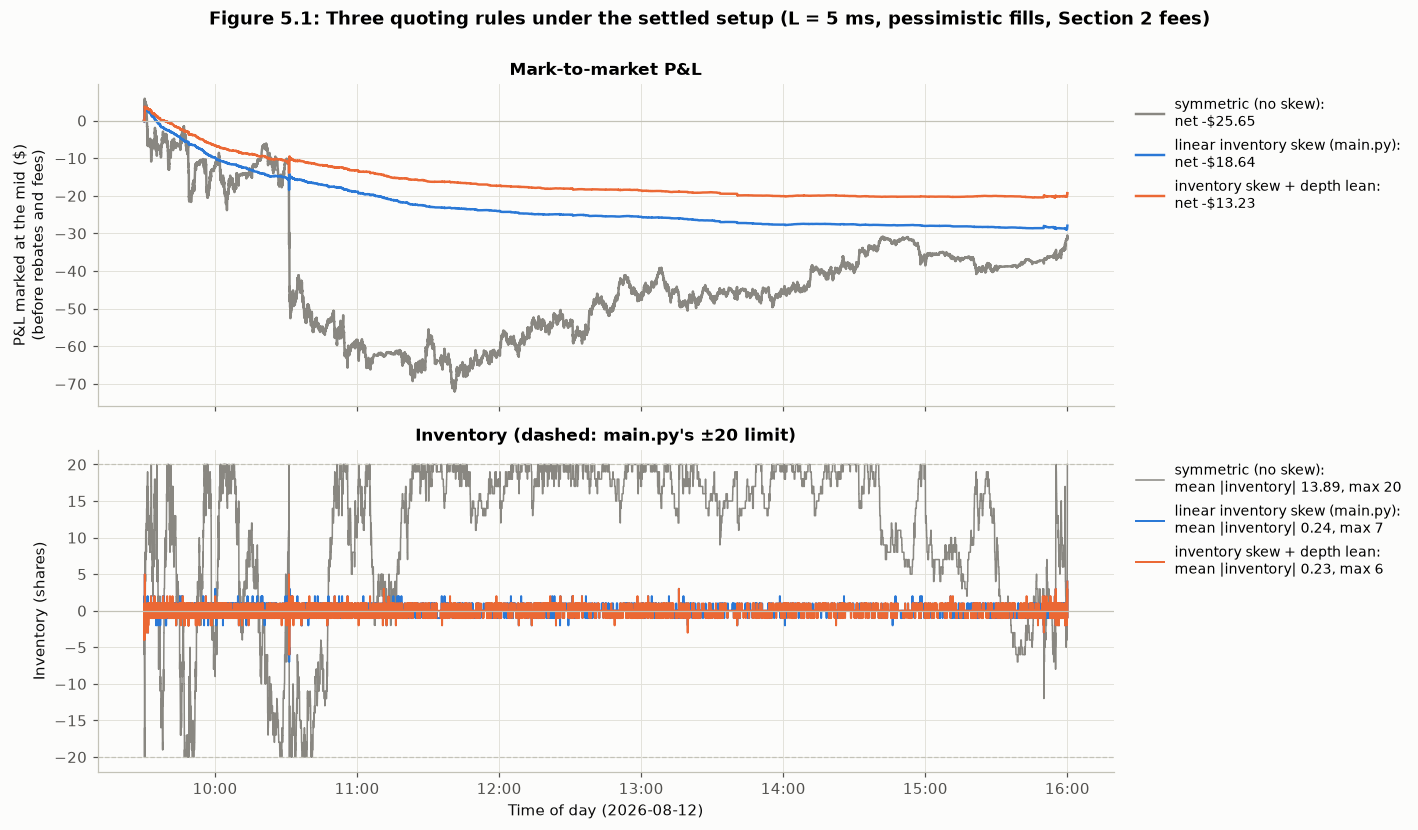

In [35]:
strategy_colors = {SYMMETRIC: COLORS["muted"], LINEAR: COLORS["real"], ALTERNATIVE: COLORS["sim"]}
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
for name, color in strategy_colors.items():
    p = strategy_paths[name]
    net = strategy_table.loc["net P&L ($)", name]
    axes[0].plot(p.index, p["pnl"], color=color, label=f"{name}:\nnet {dollars(net)}")
    axes[1].plot(p.index, p["inventory"], color=color, lw=1 if name == SYMMETRIC else 1.3,
                 label=f"{name}:\nmean |inventory| {strategy_table.loc['mean |inventory| (shares)', name]:.2f}, "
                       f"max {strategy_table.loc['max |inventory| (shares)', name]:.0f}")
axes[0].axhline(0, color="#c3c2b7", lw=0.8)
axes[0].set_ylabel("P&L marked at the mid ($)\n(before rebates and fees)")
axes[0].set_title("Mark-to-market P&L")
axes[0].legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[1].axhline(0, color="#c3c2b7", lw=0.8)
for limit in (main.MAX_INVENTORY, -main.MAX_INVENTORY):
    axes[1].axhline(limit, color="#c3c2b7", lw=0.8, ls="--")
axes[1].set_ylabel("Inventory (shares)")
axes[1].set_title(f"Inventory (dashed: main.py's ±{main.MAX_INVENTORY} limit)")
axes[1].legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[1].set_xlabel("Time of day (2026-08-12)")
fig.suptitle(f"Figure 5.1: Three quoting rules under the settled setup (L = {QUEUE_LATENCY_MS} ms, pessimistic fills, Section 2 fees)",
             fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

### 5c - Did the depth lean help?

| | Symmetric (no skew) | Linear inventory skew | Inventory skew + depth lean |
|---|---|---|---|
| Net P&L | -\$25.65 | -\$18.64 | -\$13.23 |
| Fills (shares) | 5,118 | 8,144 | 9,416 |
| Mean / max \|inventory\| (shares) | 13.89 / 20 | 0.24 / 7 | 0.23 / 6 |
| Time at \|inventory\| $\geq$ 5 | 88% | 0.03% | 0.03% |
| Max drawdown | \$77.80 | \$32.69 | \$24.25 |

- **Symmetric** quoting lets inventory random-walk out to the $\pm$20 limit (Figure 5.1). |inventory| is at least 5 for 88% of the session, the book is long 20 at the close, and it has the largest drawdown. At that point the strategy is mostly just carrying a directional position.
- **The depth lean helped without losing inventory control.** Compared with the linear skew, net P&L is \$5.41 higher, max drawdown drops from \$32.69 to \$24.25, and mean |inventory| is about the same (0.23 vs 0.24). It seems to reduce adverse selection: it captures less spread at the fill (0.41 vs 0.57 cents per share) but loses less on inventory afterwards (-\$57.65 vs -\$74.18).
- **Threshold:** 2/3 gives the same result (-\$13.25), and 1/3 fires too often (-\$16.95).
- **Without inventory skew** the lean nets -\$2.15, but inventory random-walks (mean |inventory| 12.4, drawdown \$55.23). Adding the skew costs about \$11 and cuts average inventory by about 50x, which we think is worth it.

**Verdict:** the depth lean **helped**. It improved both P&L and drawdown, so there was no tradeoff between the two. But every variant still loses money at a 1-cent offset.

## Section 6 - Markout: Are You Getting Picked Off?

**Sign convention.** For a fill at price $p$, the markout at horizon $h$ (cents per share) is

$$\text{buy: } \text{mid}(t+h) - p, \qquad \text{sell: } p - \text{mid}(t+h),$$

so **positive means the price moved in our favour**, for both sides. $h = 0$ uses the pre-trade mid (Section 3's markout-free capture). Horizons run from 0.1 s to 5 min. This is after-the-fact evaluation, so using later mids is not look-ahead in the strategy.

**Uncertainty:** fills cluster in fast markets, so the 95% band comes from a one-minute block bootstrap (1,000 draws, seeded).

### 6a/6b - Markout for the Section 5 alternative

In [36]:
MARKOUT_HORIZONS_S = [0, 0.1, 0.5, 1, 2, 5, 10, 30, 60, 120, 300]


def markouts(fills, horizons=MARKOUT_HORIZONS_S):
    """Markout in cents per share, + = the mid moved in our favour: (mid at t+h - price) for buys, (price - mid) for sells.

    h = 0 uses the mid just before the print that filled us (Section 3's markout-free spread capture). Later mids come
    from the tape at t + h; this is after-the-fact evaluation, so looking ahead is the point here.
    """
    direction = np.where(fills["side"] == "buy", 1.0, -1.0)
    out = {}
    for h in horizons:
        mid_after = (fills["mid"].to_numpy() if h == 0 else
                     prevailing(quotes["time"], quotes["mid"], fills["time"] + pd.Timedelta(seconds=h)))
        out[h] = 100 * direction * (mid_after - fills["price"].to_numpy())
    return pd.DataFrame(out, index=fills.index)


def markout_curve(fills, n_boot=1000, seed=SEED):
    """Mean markout by horizon with a 95% band from resampling one-minute blocks of fills (fills cluster in time)."""
    assert (fills["size"] == 1).all()  # one-share orders, so a plain mean is the per-share mean
    m = markouts(fills)
    minute = ((fills["time"] - SESSION_OPEN).dt.total_seconds() // 60).astype(int).clip(0, SESSION_MINUTES - 1).to_numpy()
    sums = m.groupby(minute).sum().reindex(range(SESSION_MINUTES), fill_value=0).to_numpy()
    counts = np.bincount(minute, minlength=SESSION_MINUTES)
    draws = np.random.default_rng(seed).integers(0, SESSION_MINUTES, (n_boot, SESSION_MINUTES))
    boot = sums[draws].sum(axis=1) / counts[draws].sum(axis=1)[:, None]
    return pd.DataFrame({"mean": m.mean(), "lo": np.percentile(boot, 2.5, axis=0), "hi": np.percentile(boot, 97.5, axis=0)},
                        index=pd.Index(MARKOUT_HORIZONS_S, name="horizon (s)"))


alt_fills = strategy_runs[ALTERNATIVE].fills
alt_markouts = markouts(alt_fills)
alt_curve = markout_curve(alt_fills)
is_taker = alt_fills["exchange"].eq("TAKER")
markout_table = pd.DataFrame({
    "all fills": alt_curve["mean"],
    "95% band": [f"{lo:+.2f} to {hi:+.2f}" for lo, hi in zip(alt_curve["lo"], alt_curve["hi"])],
    "buys": alt_markouts[alt_fills["side"] == "buy"].mean(),
    "sells": alt_markouts[alt_fills["side"] == "sell"].mean(),
    "passive fills": alt_markouts[~is_taker].mean(),
    "taker fills": alt_markouts[is_taker].mean(),
})
print(f"fills: {len(alt_fills):,} ({(~is_taker).sum():,} passive, {is_taker.sum():,} taker)")
display(markout_table.style.format({c: "{:+.3f}" for c in markout_table.columns if c != "95% band"}))

fills: 9,416 (6,254 passive, 3,162 taker)


,all fills,95% band,buys,sells,passive fills,taker fills
0.000000,+0.407,+0.26 to +0.61,+0.282,+0.533,+0.983,-0.732
0.100000,+0.013,-0.17 to +0.25,-0.154,+0.180,+0.213,-0.383
0.500000,-0.128,-0.33 to +0.12,-0.254,-0.002,-0.219,+0.052
1.000000,-0.215,-0.37 to -0.03,-0.290,-0.140,-0.432,+0.215
2.000000,-0.189,-0.34 to +0.00,-0.315,-0.063,-0.625,+0.674
5.000000,-0.211,-0.33 to -0.08,-0.118,-0.304,-0.927,+1.206
10.000000,-0.243,-0.35 to -0.12,+0.632,-1.119,-1.304,+1.857
30.000000,-0.226,-0.32 to -0.11,+0.651,-1.104,-1.355,+2.006
60.000000,-0.225,-0.34 to -0.11,-1.178,+0.728,-0.729,+0.771
120.000000,-0.197,-0.34 to -0.05,-1.521,+1.128,-0.408,+0.219


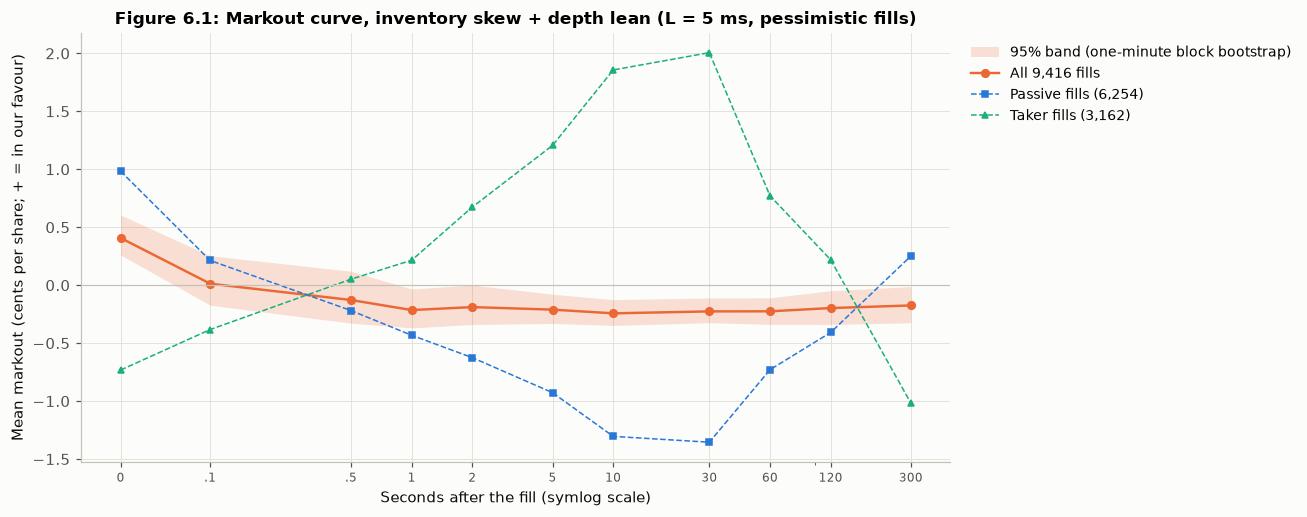

In [37]:
def symlog_horizon_axis(ax):
    ax.set_xscale("symlog", linthresh=0.1, linscale=0.4)
    ax.set_xticks(MARKOUT_HORIZONS_S, ["0", ".1", ".5", "1", "2", "5", "10", "30", "60", "120", "300"], fontsize=8)
    ax.set_xlabel("Seconds after the fill (symlog scale)")
    ax.axhline(0, color="#c3c2b7", lw=0.8)


fig, ax = plt.subplots(figsize=(12, 4.8))
h = np.array(MARKOUT_HORIZONS_S, dtype=float)
ax.fill_between(h, alt_curve["lo"], alt_curve["hi"], color=COLORS["sim"], alpha=0.2, lw=0, label="95% band (one-minute block bootstrap)")
ax.plot(h, alt_curve["mean"], marker="o", ms=5, color=COLORS["sim"], label=f"All {len(alt_fills):,} fills")
ax.plot(h, markout_table["passive fills"], marker="s", ms=4, lw=1, ls="--", color=COLORS["real"],
        label=f"Passive fills ({(~is_taker).sum():,})")
ax.plot(h, markout_table["taker fills"], marker="^", ms=4, lw=1, ls="--", color=COLORS["accent"],
        label=f"Taker fills ({is_taker.sum():,})")
symlog_horizon_axis(ax)
ax.set_ylabel("Mean markout (cents per share; + = in our favour)")
ax.set_title(f"Figure 6.1: Markout curve, {ALTERNATIVE} (L = {QUEUE_LATENCY_MS} ms, pessimistic fills)")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

**Result:** the depth-lean strategy earns +0.41 cents per share at the fill and gives all of it back within a second (-0.21 at 1 s). After that it stays flat (-0.23 at 60 s, -0.18 at 5 min). The 95% band is below zero at every horizon from 1 second to 5 minutes, except at 2 seconds where its upper edge just touches zero (Figure 6.1). This is adverse selection: the trade that fills us is the one moving the price.

*Sign check:* buys and sells agree at 1 s (-0.29 and -0.14 cents). They split apart at 5 minutes (-2.97 vs +2.62) because the mid fell \$2.07 over the day, and the combined curve cancels that drift out.

*Passive vs taker:* passive fills start at +0.98 cents and fall to -1.36 by 30 s, while taker fills start at -0.73 and rise to +2.01. A passive fill that gets picked off is often unwound by a taker fill in the direction of the move, so the two mostly offset.

### 6c - Comparing variants and quote offsets

We compare fill models (Section 4), quoting rules (Section 5), and the depth-lean strategy quoting 0-3 cents behind the touch.

In [38]:
OFFSETS = [0.0, 0.01, 0.02, 0.03]
offset_runs = {main.QUOTE_OFFSET: strategy_runs[ALTERNATIVE]}
for offset in OFFSETS:
    if offset not in offset_runs:
        offset_runs[offset] = run_session(tick_handler=make_quoter(offset=offset, depth_lean=DEPTH_LEAN), broker_cls=SETTLED_BROKER)
        assert offset_runs[offset].messages_read == baseline.messages_read

curve_groups = {
    "Fill model (main.py strategy, Section 4)": {
        "optimistic": queue_runs[OPTIMISTIC], "pessimistic": queue_runs[PESSIMISTIC]},
    "Quoting rule (Section 5, pessimistic fills)": {name: strategy_runs[name] for name in STRATEGIES},
    "Quote offset (inventory skew + depth lean)": {f"{100 * o:.0f} c behind the touch": offset_runs[o] for o in OFFSETS},
}
curves = {group: {label: markout_curve(r.fills) for label, r in runs.items()} for group, runs in curve_groups.items()}

rows = []
for group, runs in curve_groups.items():
    for label, r in runs.items():
        c = curves[group][label]["mean"]
        rows.append({"comparison": group, "variant": label, "fills": len(r.fills),
                     **{f"{h:g} s": c[h] for h in (0, 1, 5, 60, 300)},
                     "change 5 s to 300 s": c[300] - c[5], "net P&L ($)": pnl_breakdown(r)["net P&L ($)"]})
curve_table = pd.DataFrame(rows).set_index(["comparison", "variant"])
display(curve_table.style.format({"fills": "{:,}", "net P&L ($)": "{:,.2f}"}
                                 | {c: "{:+.2f}" for c in curve_table.columns if c.endswith(" s")}))

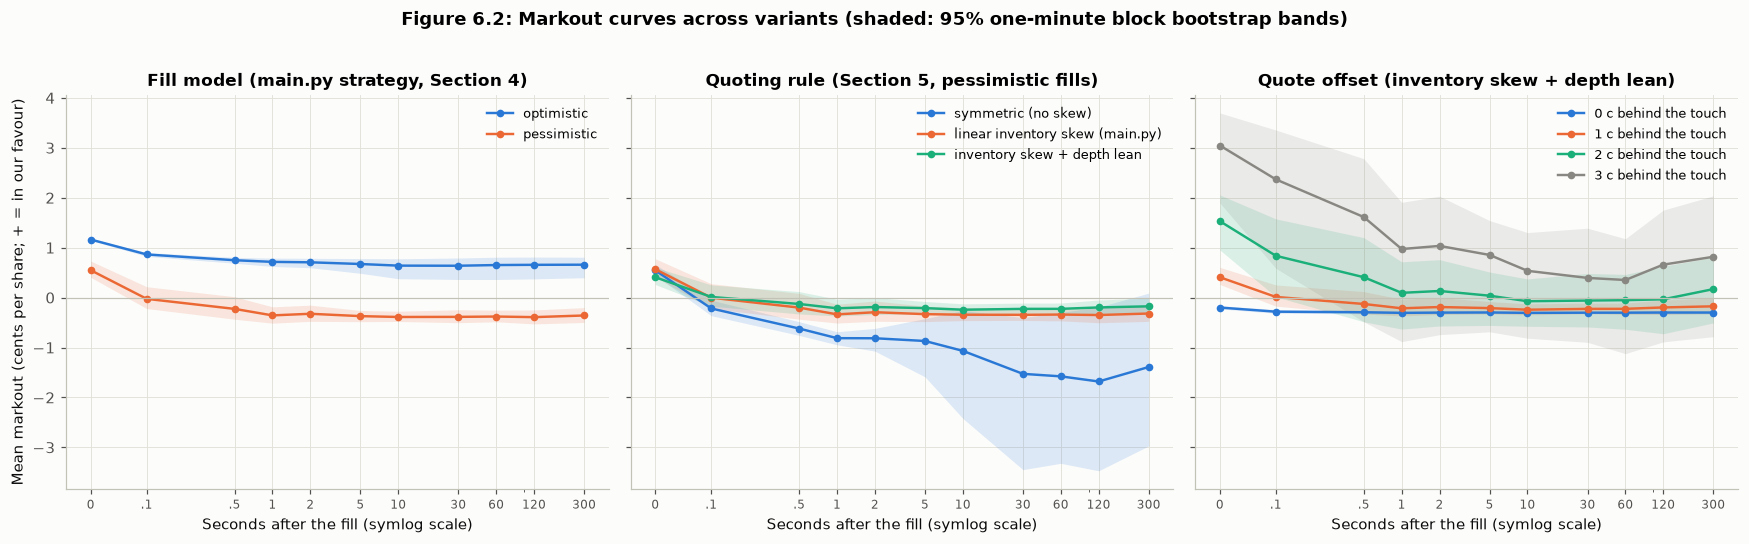

In [39]:
palette = [COLORS["real"], COLORS["sim"], COLORS["accent"], COLORS["muted"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, (group, group_curves) in zip(axes, curves.items()):
    for color, (label, c) in zip(palette, group_curves.items()):
        ax.fill_between(h, c["lo"], c["hi"], color=color, alpha=0.15, lw=0)
        ax.plot(h, c["mean"], marker="o", ms=4, color=color, label=label)
    symlog_horizon_axis(ax)
    ax.set_title(group)
    ax.legend(fontsize=8.5, loc="upper right")
axes[0].set_ylabel("Mean markout (cents per share; + = in our favour)")
fig.suptitle("Figure 6.2: Markout curves across variants (shaded: 95% one-minute block bootstrap bands)",
             fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

**Fill model.** The optimistic markout stays positive (+0.65 cents at 60 s), while the pessimistic one turns negative (-0.38). The extra fills in the optimistic model were off-exchange prints that didn't move the price against us.

**Quoting rule.** The depth lean is the least toxic (-0.23 cents at 60 s vs -0.34 for the linear skew). The symmetric curve keeps falling (-1.58 at 60 s) because it holds inventory for minutes at a time, so price drift ends up in its markout.

**Offset vs toxicity.** A larger `QUOTE_OFFSET` gives a much less toxic profile, but with far fewer fills:

| Offset | Fills | Markout at fill (c) | at 1 s | at 60 s | Net P&L |
|---|---|---|---|---|---|
| 0 c (join the touch) | 52,467 | -0.20 | -0.31 | -0.30 | -\$196.68 |
| 1 c (main.py) | 9,416 | +0.41 | -0.21 | -0.23 | -\$13.23 |
| 2 c | 2,458 | +1.53 | +0.10 | -0.05 | +\$4.71 |
| 3 c | 1,147 | +3.05 | +0.97 | +0.35 | +\$8.33 |

Each extra cent cuts fills by 2-6x and moves the whole curve up. Only at 2-3 cents is any edge left after the first second.

**Does markout stabilize?** Yes. Apart from the symmetric strategy, almost all of the move happens in the first second, and between 5 s and 5 min the curves move by less than 0.15 cents. We measure adverse selection at 60 s, which is past the point where it levels off but short enough to leave out most of the day's drift.

### 6d - The edge equation, with our numbers

This uses the Section 5 alternative under the settled setup: 5 ms latency (Section 3), pessimistic fills (Section 4), and a 0.25-cent rebate and 0.30-cent taker fee (Section 2). Adverse selection is the captured spread minus the 60-second markout (Section 6). Inventory P&L after 60 s and the flattening half-spread make up the rest of the difference between the edge and net P&L. The 2- and 3-cent offsets are shown for comparison.

In [40]:
AS_HORIZON_S = 60


def edge_equation(result, horizon=AS_HORIZON_S):
    """Module 8's edge equation in dollars, with adverse selection measured by markout at `horizon` seconds."""
    b = pnl_breakdown(result)
    m = markouts(result.fills, [0, horizon]) / 100  # dollars per share; every fill is one share
    captured, kept = m[0].sum(), m[horizon].sum()
    terms = {
        "captured spread": captured,
        "+ rebates": b["rebates ($)"],
        "- fees": -b["fees ($)"],
        f"- adverse selection (markout 0 to {horizon} s)": -(captured - kept),
        "= edge": captured + b["rebates ($)"] - b["fees ($)"] - (captured - kept),
        f"inventory P&L after {horizon} s": b["gross P&L ($)"] - kept,
        "flattening half-spread": -b["flattening half-spread ($)"],
    }
    terms["= net P&L"] = terms["= edge"] + terms[f"inventory P&L after {horizon} s"] + terms["flattening half-spread"]
    assert np.isclose(terms["= net P&L"], b["net P&L ($)"])
    return pd.Series(terms), b["fills (shares)"]


edge_cols = {f"{ALTERNATIVE}, 1 c (Section 5)": offset_runs[0.01],
             "same, 2 c offset": offset_runs[0.02], "same, 3 c offset": offset_runs[0.03]}
edge_parts = {name: edge_equation(r) for name, r in edge_cols.items()}
edge_table = pd.concat({name: terms for name, (terms, _) in edge_parts.items()}, axis=1)
per_share = pd.concat({name: 100 * terms / shares for name, (terms, shares) in edge_parts.items()}, axis=1)
display(pd.concat({"$ for the session": edge_table, "cents per filled share": per_share}, axis=1)
        .style.format("{:+,.2f}"))
as_share = {name: -terms[f"- adverse selection (markout 0 to {AS_HORIZON_S} s)"] / terms["captured spread"]
            for name, (terms, _) in edge_parts.items()}
display(pd.DataFrame(as_share, index=["adverse selection / captured spread"]).style.format("{:.0%}"))

Per filled share, at a 1-cent offset:

$$\underbrace{-0.16\text{ c}}_{\text{edge}} = \underbrace{0.41\text{ c}}_{\text{captured spread}} + \underbrace{0.17\text{ c}}_{\text{rebates}} - \underbrace{0.10\text{ c}}_{\text{fees}} - \underbrace{0.63\text{ c}}_{\text{adverse selection}}$$

That is -\$15.08 for the session (-\$13.23 net after +\$1.93 of later inventory P&L and \$0.08 of flattening).

**None of the captured spread survives.** Adverse selection takes 155% of it (\$59.58 lost vs \$38.36 captured), and rebates (\$15.63) only cover about a quarter of that loss. At a 2-cent offset it takes 103% (edge +\$1.60, all of it from rebates), and at 3 cents it takes 88%, leaving an edge of +0.46 cents per share (\$5.25). For comparison, Section 2's frictionless edge was 0.852 cents per share.

## Section 7 - Full Backtest and Performance Tearsheet

**The configuration**, one choice from each section:

| Piece | Choice | Why |
|---|---|---|
| Fees | 0.25-cent maker rebate, 0.30-cent taker fee, flatten at 16:00 | Module 8's figures (Section 2) |
| Latency | 5 ms each way | inside the 1-20 ms range any automated setup reaches (Section 3) |
| Fill model | pessimistic: lit prints only, marketable orders take, back of the queue | Section 4c |
| Quoting | inventory skew (1 cent per share) + depth lean, crossed-NBBO guard | best P&L and drawdown with inventory under control (Section 5c) |
| Quote offset | set by volatility, refit every 30 minutes | wider quotes are less toxic but fill less (Section 6c) |

### 7a - Rolling recalibration

**Rule.** Adverse selection plays out within about a second (Section 6), so we set the offset to about one typical 1-second mid move, $\hat\sigma\sqrt{1\text{ s}}$, rounded to the cent. There is a floor of 1 cent, since joining the touch was the worst option in 6c, and a cap of 3 cents (about 1,100 fills a day). $\hat\sigma$ is Section 1's 10 ms realized volatility.

**Refits.** At 10:00, 10:30, ..., 15:30, $\hat\sigma$ is re-estimated using only the previous 30 minutes of quotes, so nothing comes from the future. The first half hour has no data yet, so it starts at the 3-cent cap (the open is the most volatile part of the day, Section 1).

**Why every 30 minutes:** volatility changes over hours (Section 1's intraday pattern), and 30 minutes gives 180,000 ten-millisecond observations, which is enough for a stable estimate. Refitting every 10 minutes nets \$8.22 vs \$8.06, so there's no real difference, and no schedule could react to something as fast as the 10:31 drop. We don't refit $k$ and $A$, because Section 6 shows the losses come from which trades reach us, and the number of trades isn't the issue.

In [41]:
REFIT_MINUTES = 30          # refit at 10:00, 10:30, ..., 15:30
SIGMA_WINDOW_MINUTES = 30   # trailing window for each refit
OFFSET_HORIZON_S = 1.0      # rest about one typical 1-second mid move behind the touch (Section 6)
OFFSET_FLOOR, OFFSET_CAP = 0.01, 0.03


def rolling_offsets(refit_minutes=REFIT_MINUTES, window_minutes=SIGMA_WINDOW_MINUTES):
    """Quote offset for each refit period, from realized sigma (Section 1's 10 ms estimator) on quotes before the refit.

    The first period has no session data yet and uses the cap.
    """
    points_per_minute = int(round(60 / SIGMA_STEP_S))
    rows = []
    for start in range(0, SESSION_MINUTES, refit_minutes):
        if start == 0:
            sigma, offset = np.nan, OFFSET_CAP
        else:
            window = mid_10ms[max(0, start - window_minutes) * points_per_minute: start * points_per_minute + 1]
            sigma = realized_sigma(window, 1, SIGMA_STEP_S)  # last point is the mid in force just before the refit
            offset = float(np.clip(round(100 * sigma * np.sqrt(OFFSET_HORIZON_S)) / 100, OFFSET_FLOOR, OFFSET_CAP))
        rows.append({"refit at": SESSION_OPEN + pd.Timedelta(minutes=start), "trailing sigma ($/sqrt s)": sigma,
                     "1-s move (c)": 100 * sigma * np.sqrt(OFFSET_HORIZON_S), "offset (c)": round(100 * offset)})
    return pd.DataFrame(rows)


def offset_schedule(table):
    """Turn a refit table into offset(time) for make_quoter."""
    starts = to_ns(table["refit at"])
    offsets = table["offset (c)"].to_numpy() / 100

    def offset_at(now):
        return offsets[max(np.searchsorted(starts, np.datetime64(now, "ns"), side="right") - 1, 0)]
    return offset_at


refits = rolling_offsets()
display(refits.style.hide(axis="index").format({"refit at": lambda t: f"{t:%H:%M}", "trailing sigma ($/sqrt s)": "{:.4f}",
                                                "1-s move (c)": "{:.2f}"}, na_rep="(none yet)"))

refit at,trailing sigma ($/sqrt s),1-s move (c),offset (c)
09:30,(none yet),(none yet),3
10:00,0.0297,2.97,3
10:30,0.0218,2.18,2
11:00,0.0278,2.78,3
11:30,0.0188,1.88,2
12:00,0.0141,1.41,1
12:30,0.0121,1.21,1
13:00,0.0117,1.17,1
13:30,0.0101,1.01,1
14:00,0.0097,0.97,1


In [42]:
FINAL_KNOBS = dict(offset=offset_schedule(refits), depth_lean=DEPTH_LEAN)
FINAL = "full strategy (rolling offset)"
final_run = run_session(tick_handler=make_quoter(**FINAL_KNOBS), broker_cls=SETTLED_BROKER)
faster_refits = rolling_offsets(refit_minutes=10)
faster_run = run_session(tick_handler=make_quoter(offset=offset_schedule(faster_refits), depth_lean=DEPTH_LEAN),
                         broker_cls=SETTLED_BROKER)
no_lean_run = run_session(tick_handler=make_quoter(offset=offset_schedule(refits)), broker_cls=SETTLED_BROKER)
for r in (final_run, faster_run, no_lean_run):
    assert r.messages_read == baseline.messages_read

choice = pd.DataFrame({FINAL: pnl_breakdown(final_run), "same, refit every 10 min": pnl_breakdown(faster_run),
                       "same, without the depth lean": pnl_breakdown(no_lean_run)}
                      | {f"fixed {100 * o:.0f} c offset": pnl_breakdown(offset_runs[o]) for o in (0.01, 0.02, 0.03)})
display(show_breakdown(choice.loc[["fills (shares)", "spread capture per share (c)", "gross P&L ($)", "rebates ($)",
                                   "fees ($)", "net P&L ($)", "mean |inventory| (shares)", "max drawdown ($)"]]))

,full strategy (rolling offset),"same, refit every 10 min","same, without the depth lean",fixed 1 c offset,fixed 2 c offset,fixed 3 c offset
fills (shares),"4,556","4,546","3,756","9,416","2,458","1,147"
spread capture per share (c),0.87,0.87,1.13,0.41,1.53,3.05
gross P&L ($),4.09,4.33,-0.62,-19.29,1.93,7.22
rebates ($),8.06,8.01,7.47,15.63,4.66,2.12
fees ($),4.01,4.04,2.32,9.50,1.80,0.91
net P&L ($),8.06,8.22,4.45,-13.23,4.71,8.33
mean |inventory| (shares),0.27,0.26,0.26,0.23,0.29,0.35
max drawdown ($),5.89,6.02,8.27,24.25,9.22,6.57


**Result.** The offset is 2-3 cents in the morning and 1 cent from 12:00 on. The rolling rule nets \$8.06 on 4,556 fills, with a max drawdown of \$5.89. A fixed 3-cent offset nets about the same (\$8.33) on a quarter of the fills, but we could only have picked that after seeing the day. The rolling rule only uses past data, so it is the fairer number to report. Without the depth lean it nets \$4.45 (drawdown \$8.27).

### 7b - Tearsheet

In [43]:
def tearsheet(result, with_fees=True):
    b = pnl_breakdown(result)
    terms, _ = edge_equation(result)
    if not with_fees:  # main.py as-is: no rebates, fees or flattening
        b["rebates ($)"] = b["fees ($)"] = 0.0
        b["net P&L ($)"] = b["gross P&L ($)"]
    return {
        "Gross P&L": b["gross P&L ($)"], "Rebates earned": b["rebates ($)"], "Fees paid": b["fees ($)"],
        "Net P&L": b["net P&L ($)"],
        f"Estimated adverse selection cost (markout 0 to {AS_HORIZON_S} s)": -terms[f"- adverse selection (markout 0 to {AS_HORIZON_S} s)"],
        "Fill count (buy / sell)": b["buy / sell (shares)"],
        "Mean |inventory| (shares)": b["mean |inventory| (shares)"], "Max |inventory| (shares)": b["max |inventory| (shares)"],
        "End-of-day inventory (shares, before flattening)": b["16:00 inventory (shares)"],
        "P&L volatility (std of 1-minute changes)": b["P&L volatility, 1-min changes ($)"],
        "Max intraday drawdown": b["max drawdown ($)"],
    }


sheet = pd.DataFrame({FINAL: tearsheet(final_run),
                      "naive symmetric (no skew), same setup": tearsheet(strategy_runs[SYMMETRIC]),
                      "main.py as-is (L = 0, optimistic, no fees)": tearsheet(baseline, with_fees=False)})
display(sheet.style.format(lambda v: f"{v:,.2f}" if isinstance(v, float) else v))

final_paths = session_paths(final_run.fills, quotes)
half_hour_pnl = np.diff(final_paths["pnl"].to_numpy()[::1800])
display(pd.DataFrame([half_hour_pnl], index=["gross P&L in the half hour ($)"], columns=half_hour_labels).round(2))
show({
    "net P&L per filled share (c)": f"{100 * sheet.loc['Net P&L', FINAL] / len(final_run.fills):.3f}",
    "rebates / net P&L": f"{sheet.loc['Rebates earned', FINAL] / sheet.loc['Net P&L', FINAL]:.0%}",
    "half hours with positive gross P&L": f"{(half_hour_pnl > 0).sum()} of 13",
    "standard error of the day's gross P&L, from the 13 half hours ($)": f"{np.std(half_hour_pnl, ddof=1) * np.sqrt(13):.2f}",
}, FINAL)

,full strategy (rolling offset),"naive symmetric (no skew), same setup","main.py as-is (L = 0, optimistic, no fees)"
Gross P&L,4.09,-31.51,247.54
Rebates earned,8.06,9.85,0.00
Fees paid,4.01,3.59,0.00
Net P&L,8.06,-25.65,247.54
Estimated adverse selection cost (markout 0 to 60 s),40.24,108.68,232.70
Fill count (buy / sell),"2,280 / 2,276","2,569 / 2,549","20,539 / 20,533"
Mean |inventory| (shares),0.27,13.89,0.51
Max |inventory| (shares),7.00,20.00,20.00
"End-of-day inventory (shares, before flattening)",4.00,20.00,6.00
P&L volatility (std of 1-minute changes),0.34,2.86,3.95


,09:30,10:00,10:30,11:00,11:30,12:00,12:30,13:00,13:30,14:00,14:30,15:00,15:30
gross P&L in the half hour ($),4.84,-0.66,1.25,0.35,0.3,-0.79,-0.52,-0.43,-1.04,0.05,-0.13,0.15,0.73


,full strategy (rolling offset)
net P&L per filled share (c),0.177
rebates / net P&L,100%
half hours with positive gross P&L,7 of 13
"standard error of the day's gross P&L, from the 13 half hours ($)",5.42


**Full strategy, SPY, 2026-08-12, 09:30-16:00:** 5 ms latency, pessimistic fills, Section 2 fees, inventory skew + depth lean, offset refit every 30 minutes.

| Metric | Value |
|---|---|
| Gross P&L | \$4.09 |
| Rebates earned | \$8.06 |
| Fees paid | \$4.01 |
| Net P&L | **\$8.06** (0.18 cents per share) |
| Estimated adverse selection cost (markout, 0 to 60 s) | \$40.24 (0.88 cents per share) |
| Fill count (buy / sell) | 2,280 / 2,276 |
| Mean \|inventory\| | 0.27 shares |
| Max \|inventory\| | 7 shares |
| End-of-day inventory | 4 shares long, sold at the 16:00 bid |
| P&L volatility (std of 1-minute changes) | \$0.34 |
| Max intraday drawdown | \$5.89 |

Net P&L also subtracts \$0.08 of flattening half-spread.

### 7c - P&L over the day

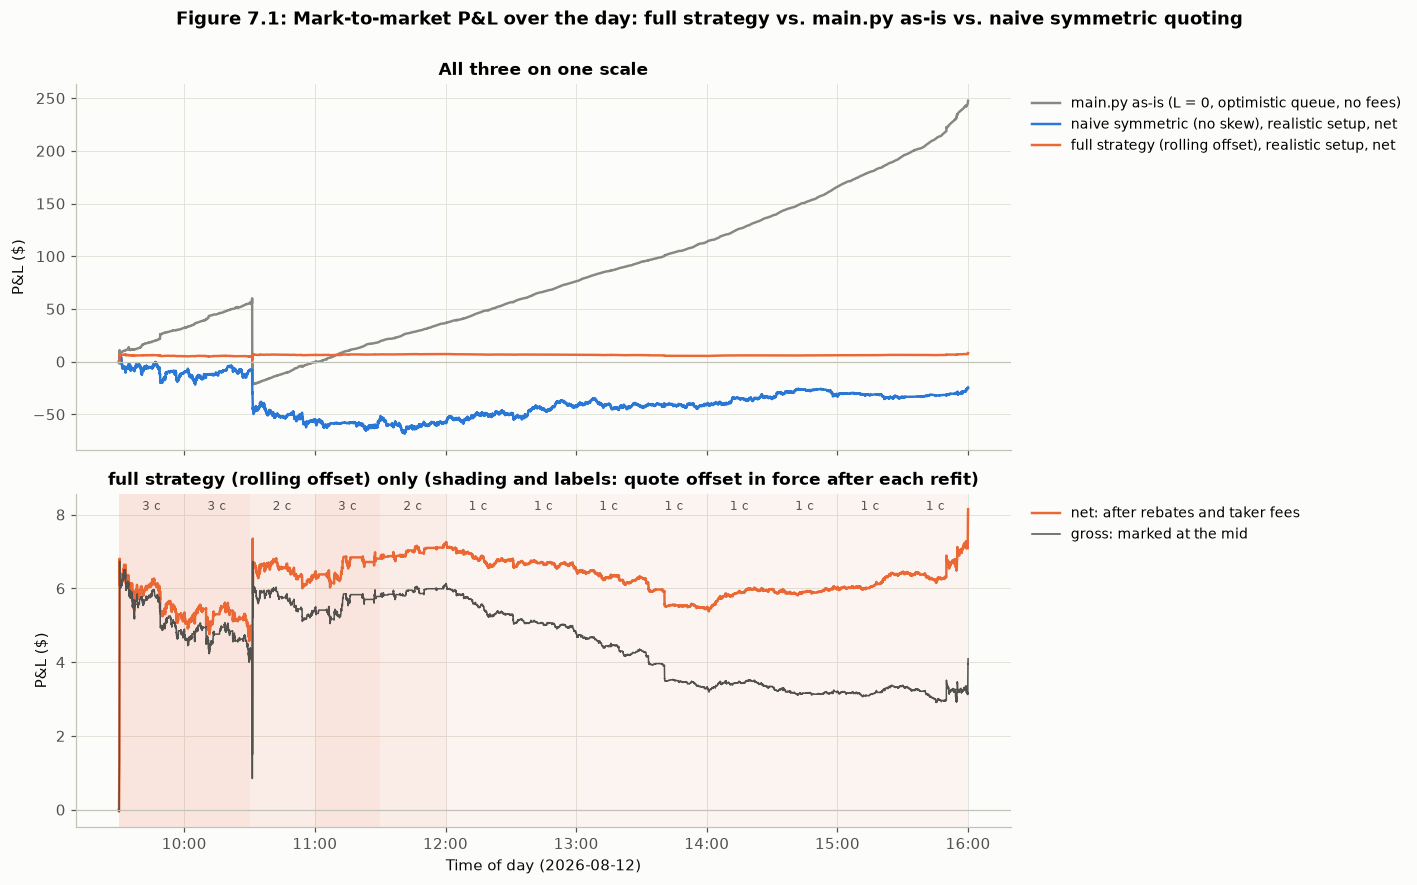

In [44]:
def net_path(result, result_paths, rho=RHO_HEADLINE, taker_fee=TAKER_FEE):
    """Mid-marked P&L plus rebates earned and taker fees paid so far (flattening is booked at 16:00 only)."""
    f = result.fills
    per_fill = np.where(f["exchange"].eq("TAKER"), -taker_fee, rho) * f["size"].to_numpy()
    so_far = pd.Series(per_fill, index=f["time"]).groupby(level=0).sum().cumsum()
    return result_paths["pnl"] + np.nan_to_num(prevailing(so_far.index, so_far.to_numpy(), result_paths.index))


fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [1.1, 1]})
for name, p, color in (("main.py as-is (L = 0, optimistic queue, no fees)", paths["pnl"], COLORS["muted"]),
                       ("naive symmetric (no skew), realistic setup, net", net_path(strategy_runs[SYMMETRIC], strategy_paths[SYMMETRIC]), COLORS["real"]),
                       (f"{FINAL}, realistic setup, net", net_path(final_run, final_paths), COLORS["sim"])):
    axes[0].plot(p.index, p, color=color, label=name)
axes[0].set_ylabel("P&L ($)")
axes[0].set_title("All three on one scale")
axes[1].plot(final_paths.index, net_path(final_run, final_paths), color=COLORS["sim"], label="net: after rebates and taker fees")
axes[1].plot(final_paths.index, final_paths["pnl"], color=COLORS["ink"], lw=1, label="gross: marked at the mid")
for _, row in refits.iterrows():
    axes[1].axvspan(row["refit at"], row["refit at"] + pd.Timedelta(minutes=REFIT_MINUTES), color=COLORS["sim"],
                    alpha=0.05 * row["offset (c)"], lw=0)
    axes[1].text(row["refit at"] + pd.Timedelta(minutes=REFIT_MINUTES / 2), 0.98, f"{row['offset (c)']:.0f} c",
                 transform=axes[1].get_xaxis_transform(), ha="center", va="top", fontsize=8, color=COLORS["ink"])
axes[1].set_ylabel("P&L ($)")
axes[1].set_title(f"{FINAL} only (shading and labels: quote offset in force after each refit)")
for ax in axes:
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[1].set_xlabel("Time of day (2026-08-12)")
fig.suptitle("Figure 7.1: Mark-to-market P&L over the day: full strategy vs. main.py as-is vs. naive symmetric quoting",
             fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

opening = final_paths["pnl"].iloc[60]
show({"gross P&L by 09:31 ($)": f"{opening:.2f}",
      "gross P&L from 09:31 to 16:00 ($)": f"{final_paths['pnl'].iloc[-1] - opening:.2f}"}, FINAL)

`main.py` as-is climbs to \$247.54 (Figure 7.1). With realistic fills, the naive symmetric benchmark ends at -\$25.65 net and the full strategy ends at +\$8.06. There are two caveats on the \$8.06:
- **It comes from the rebate.** Gross trading P&L is \$4.09, which is cancelled out by \$4.01 of taker fees. Its standard error is about \$5.42 (from 13 half-hour pieces), so trading P&L can't be told apart from zero.
- **Most of the gross P&L comes from the open.** \$6.09 of gross P&L is made in the first minute. From 09:31 to the close, gross P&L is -\$1.99.

### 7d - Recommendation for the head trader

**We don't recommend a live allocation yet.** With realistic fills, 5 ms latency and real fees, the strategy made \$8.06 on 4,556 one-share fills, and all of that was maker rebate. Trading P&L was \$4.09 with a standard error of about \$5, and it was negative after the first minute. Risk is well controlled (inventory never went above 7 shares and max drawdown was \$5.89), but there is no clear trading edge. Instead we would fund a two-to-four-week paper-trading run on one lit venue with order-level data, so fills and queue position are measured instead of modeled, and only go live if net-of-markout P&L stays positive over those days, latency stays under about 20 ms, and the venue pays a standard maker rebate.

### Interpretation

**Ranking the frictions.** The table below adds them to the `main.py` strategy one at a time, in section order.

In [45]:
# How much each friction moves the main.py strategy, in the order the sections added them (net P&L, $).
baseline_as = -edge_equation(baseline)[0][f"- adverse selection (markout 0 to {AS_HORIZON_S} s)"]
final_as = -edge_equation(final_run)[0][f"- adverse selection (markout 0 to {AS_HORIZON_S} s)"]
ladder = pd.DataFrame([
    ("main.py, frictionless (Section 1)", gross_pnl, np.nan),
    ("+ maker rebates, flattening fee (Section 2)", headline_net, headline_net - gross_pnl),
    (f"+ {QUEUE_LATENCY_MS} ms latency (Section 3)", latency_table.loc[QUEUE_LATENCY_MS, "net P&L ($)"],
     latency_table.loc[QUEUE_LATENCY_MS, "net P&L ($)"] - headline_net),
    ("+ cancel/replace handling (Section 4, a fix not a friction)", queue_table.loc["net P&L ($)", OPTIMISTIC],
     queue_table.loc["net P&L ($)", OPTIMISTIC] - latency_table.loc[QUEUE_LATENCY_MS, "net P&L ($)"]),
    ("+ pessimistic fill model (Section 4)", queue_table.loc["net P&L ($)", PESSIMISTIC],
     queue_table.loc["net P&L ($)", PESSIMISTIC] - queue_table.loc["net P&L ($)", OPTIMISTIC]),
], columns=["step", "net P&L ($)", "change ($)"]).set_index("step")
display(ladder.style.format("{:+,.2f}", na_rep=""))
show({"frictionless baseline ($)": f"{baseline_as:.2f}", "full strategy ($)": f"{final_as:.2f}"},
     f"adverse selection, markout 0 to {AS_HORIZON_S} s")

,net P&L ($),change ($)
step,,
"main.py, frictionless (Section 1)",+247.54,
"+ maker rebates, flattening fee (Section 2)",+350.08,+102.54
+ 5 ms latency (Section 3),+200.82,-149.27
"+ cancel/replace handling (Section 4, a fix not a friction)",+286.28,+85.47
+ pessimistic fill model (Section 4),-22.08,-308.36


1. **Fill model / queue priority: -\$308** (\$286.28 to -\$22.08 at 5 ms). Almost all of it comes from excluding off-exchange prints, and joining the back of the queue by itself costs about \$29.
2. **Adverse selection: about -\$233** in the frictionless baseline (markout 0-60 s) and -\$40 in the full strategy. It is already included in every P&L number, so it doesn't show up as its own step in the table.
3. **Latency: -\$149** from 0 to 5 ms (\$350.08 to \$200.82), mostly in the first millisecond.
4. **Fees and rebates: +\$103** for the baseline and about +\$4 net for the full strategy. The strategy is mostly passive, and the 16:00 taker trade only costs pennies.

**Was this surprising?** Yes. We expected latency to matter most, since Module 8 puts so much weight on colocation. The fill model ended up mattering most instead, because of a data issue: half the prints on the tape are off-exchange, and it is easy to miss that letting them fill a lit order is wrong. Queue position itself mattered less than we expected.

**Did the Section 5 alternative survive?** Partly. With realistic frictions at a 1-cent offset it raised net P&L by \$5.41 and cut max drawdown by about a quarter, but the strategy still lost \$13.23. In the full strategy it adds \$3.61 (\$8.06 vs \$4.45) and lowers drawdown from \$8.27 to \$5.89. So the improvement held up, but it is only a few dollars a day.

**First change with real money: raise the offset floor from 1 to 2 cents.** Adverse selection takes 155% of the captured spread at 1 cent, 103% at 2 cents and 88% at 3 cents (Section 6d). In the full strategy, the eight afternoon half hours quoted at 1 cent lost \$1.98 before rebates. Inventory is already under control (max 7, mean 0.27 shares), so a tighter inventory limit wouldn't add much.

## Section 8 - Bonus: Toxicity-Aware Quoting

**Choice:** a toxicity rule built on the Section 6 markout analysis that only uses information the strategy has already seen. We didn't use time-of-day windows because with one day of data they would just be fit to that day.

**Rule:** one second after learning about each fill, the strategy works out that fill's markout from its own (5 ms old) NBBO. If its last 5 fills average below -1 cent, it pulls both quotes for 30 seconds. We use one second because that is where Section 6's curves flatten out. Everything else is the same as the Section 7 strategy, and three other settings are run to check robustness.

In [46]:
class ToxicityPause:
    """Pull both quotes for pause_s once our last n_fills fills average a 1-second markout below threshold_c.

    Uses only what the strategy has seen: each fill's markout is read horizon_s after the strategy learns of the
    fill, from the (L ms old) NBBO it is quoting off.
    """

    def __init__(self, horizon_s=1.0, n_fills=5, threshold_c=-1.0, pause_s=30.0):
        self.horizon, self.pause = timedelta(seconds=horizon_s), timedelta(seconds=pause_s)
        self.n_fills, self.threshold_c = n_fills, threshold_c
        self._pending = deque()   # (time the markout can be read, +1 buy / -1 sell, fill price)
        self._recent = deque(maxlen=n_fills)
        self._paused_until = None
        self.pauses = []          # time each pause started

    def on_fill(self, message, book):
        direction = 1.0 if message.side == "buy" else -1.0
        self._pending.append((book["time"] + self.horizon, direction, message.price))

    def paused(self, book):
        mid = 0.5 * (book["best_bid"] + book["best_ask"])
        while self._pending and self._pending[0][0] <= book["time"]:
            _, direction, price = self._pending.popleft()
            self._recent.append(100 * direction * (mid - price))
            if len(self._recent) == self.n_fills and np.mean(self._recent) < self.threshold_c:
                self._paused_until = book["time"] + self.pause
                self.pauses.append(book["time"])
                self._recent.clear()
        return self._paused_until is not None and book["time"] < self._paused_until

    def seconds_paused(self, end=SESSION_CLOSE):
        total, covered_to = 0.0, None
        for start in self.pauses:
            stop = min(start + self.pause, end)
            begin = max(start, covered_to) if covered_to else start
            total += max((stop - begin).total_seconds(), 0.0)
            covered_to = max(covered_to, stop) if covered_to else stop
        return total


TOXICITY_GRID = {  # (threshold in cents, fills averaged, pause in seconds); the first is the headline setting
    "-1 c over 5 fills, 30 s pause": (-1.0, 5, 30),
    "-0.5 c over 5 fills, 30 s pause": (-0.5, 5, 30),
    "-2 c over 5 fills, 30 s pause": (-2.0, 5, 30),
    "-1 c over 3 fills, 60 s pause": (-1.0, 3, 60),
}
toxicity_runs, toxicity_rules = {}, {}
for name, (threshold, n_fills, pause) in TOXICITY_GRID.items():
    toxicity_rules[name] = ToxicityPause(threshold_c=threshold, n_fills=n_fills, pause_s=pause)
    toxicity_runs[name] = run_session(tick_handler=make_quoter(**FINAL_KNOBS, toxicity=toxicity_rules[name]),
                                      broker_cls=SETTLED_BROKER)
    assert toxicity_runs[name].messages_read == baseline.messages_read

rows = {}
for name, r in ({FINAL + " (Section 7)": final_run} | toxicity_runs).items():
    b = pnl_breakdown(r)
    rule = toxicity_rules.get(name)
    rows[name] = {"pauses": len(rule.pauses) if rule else 0,
                  "time paused (% of session)": 100 * rule.seconds_paused() / SESSION_SECONDS if rule else 0.0,
                  "fills (shares)": b["fills (shares)"],
                  f"markout at {AS_HORIZON_S} s (c/share)": markouts(r.fills, [AS_HORIZON_S])[AS_HORIZON_S].mean(),
                  "gross P&L ($)": b["gross P&L ($)"], "net P&L ($)": b["net P&L ($)"],
                  "max drawdown ($)": b["max drawdown ($)"]}
toxicity_table = pd.DataFrame(rows).T
display(toxicity_table.style.format({"pauses": "{:,.0f}", "fills (shares)": "{:,.0f}"}, precision=2))

,pauses,time paused (% of session),fills (shares),markout at 60 s (c/share),gross P&L ($),net P&L ($),max drawdown ($)
full strategy (rolling offset) (Section 7),0,0.00,"4,556",-0.01,4.09,8.06,5.89
"-1 c over 5 fills, 30 s pause",129,15.65,"2,929",-0.23,-1.93,0.96,9.37
"-0.5 c over 5 fills, 30 s pause",209,25.88,"2,424",-0.17,2.36,4.81,2.41
"-2 c over 5 fills, 30 s pause",51,5.58,"3,472",-0.17,0.02,3.48,6.51
"-1 c over 3 fills, 60 s pause",147,35.10,"2,030",-0.20,1.89,3.93,7.88


In [47]:
# What did the pauses skip? Replay the headline rule over the Section 7 run's own fills (approximately: exchange-time
# mids, no feedback from pausing) and compare the fills that would have fallen inside a pause with the rest.
f = final_run.fills
m = markouts(f, [1, AS_HORIZON_S])
headline = TOXICITY_GRID["-1 c over 5 fills, 30 s pause"]
readable = f["time"] + pd.Timedelta(milliseconds=QUEUE_LATENCY_MS) + pd.Timedelta(seconds=1)
order = np.argsort(readable.to_numpy(), kind="stable")
recent, windows = deque(maxlen=headline[1]), []
for i in order:
    recent.append(m[1].iloc[i])
    if len(recent) == headline[1] and np.mean(recent) < headline[0]:
        windows.append((readable.iloc[i], readable.iloc[i] + pd.Timedelta(seconds=headline[2])))
        recent.clear()
starts, ends = to_ns([w[0] for w in windows]), to_ns([w[1] for w in windows])
k = np.searchsorted(starts, to_ns(f["time"]), side="right") - 1
inside = (k >= 0) & (to_ns(f["time"]) < ends[np.maximum(k, 0)])
trigger_fills = m[1] < headline[0]
summary = pd.DataFrame({
    "fills": [int(inside.sum()), int((~inside).sum())],
    f"mean markout at {AS_HORIZON_S} s (c)": [m.loc[inside, AS_HORIZON_S].mean(), m.loc[~inside, AS_HORIZON_S].mean()],
    "mean 1-s markout (c)": [m.loc[inside, 1].mean(), m.loc[~inside, 1].mean()],
}, index=["inside a would-be pause", "everywhere else"])
display(summary.style.format({"fills": "{:,}"}, precision=2))
print(f"would-be pauses: {len(windows)}")

,fills,mean markout at 60 s (c),mean 1-s markout (c)
inside a would-be pause,"1,898",0.26,0.63
everywhere else,"2,658",-0.21,-0.29


would-be pauses: 213


**Result: it made things worse.** Every setting lowers net P&L, from \$8.06 to between \$0.96 and \$4.81. The headline setting paused 129 times (16% of the session), its 60-second markout got worse (-0.23 vs -0.01 cents), and max drawdown went up from \$5.89 to \$9.37.

**Why:** toxicity doesn't last. Replaying the rule over the Section 7 fills, the 1,898 fills that fall inside would-be pauses have a 60-second markout of **+0.26 cents**, compared with -0.21 everywhere else. After a run of picked-off fills the price has already moved, and the next 30 seconds tend to be better than average. Adverse moves are over within about a second (Section 6), so a rule that needs a second to see each markout is always too late.

**What this means for Section 7:** stepping aside after bad fills doesn't avoid adverse selection. It has to be predicted before the fill (like the depth lean) or priced in by quoting wider (like the rolling offset).